# Models

The main line (M1-M6, with the checks M5+R and M5+T) and the drift branch (D1-D4 and the final model F), each at
both cross-validation seeds: the tables and figures of the Results chapter, then every model's measurements on
held-out fish. A model is a unit of five fold checkpoints (`twin/registry.py`); seeds are never pooled.

<a id="contents"></a>
**Contents**

- [Training and evaluation](#training-and-evaluation)
- [Every model at both seeds (Table tab:storyline)](#every-model-at-both-seeds-table-tab-storyline)
- [Individuality of every model (Table tab:realism)](#individuality-of-every-model-table-tab-realism)
- [What tells each model from real fish (Tables tab:app-imp-s0 and tab:app-imp-s101)](#what-tells-each-model-from-real-fish-tables-tab)
- [Slow structure (Figure fig:slow)](#slow-structure-figure-fig-slow)
- [Distance to the dots (Figure fig:profiles) and the between-fish bands (Figures fig:app-bands-*,](#distance-to-the-dots-figure-fig-profiles-and-the)
- [How the latent gain, the drift gains and the correction were set (Figures fig:app-latent-gain,](#how-the-latent-gain-the-drift-gains-and-the-corr)
- [Every model's measurements on held-out fish](#every-model-s-measurements-on-held-out-fish)

In [1]:
import pandas as pd
from twin import registry, tables, training, unit_eval
pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)

In [2]:
MODELS = tables.MAIN

<a id="training-and-evaluation"></a>
## Training and evaluation

`TRAIN = True` retrains every unit below (about 90 CPU-hours, 1-2 h per fold for the drift models), `EVALUATE = True` re-runs every evaluation (about 15 min per
unit); both write to `output/`. Evaluation is deterministic, so re-evaluating reproduces the saved numbers exactly.

[↑ back to contents](#contents)

In [3]:
TRAIN, EVALUATE = False, False
UNITS = [(name, seed) for name in MODELS for seed in (0, 101) if (name, seed) in registry.BY_NAME]
for name, seed in UNITS:
    if TRAIN:
        training.make_unit(name, seed)
    if EVALUATE:
        unit_eval.evaluate(registry.BY_NAME[(name, seed)])
pd.DataFrame([dict(model=n, seed=s, key=registry.BY_NAME[(n, s)], made=registry.unit(n, s)["make"],
                   arm=registry.arm(registry.unit(n, s))) for n, s in UNITS]).set_index(["model", "seed"])

key     made                                               arm
model seed                                                                
M1    0       1    train                                            S0_adt
      101   34a    train                                            S0_adt
M2    0       2     same                                            S0_adt
      101   34b     same                                            S0_adt
M3    0       3    train                                         S0_adt_z2
      101   34c    train                                         S0_adt_z2
M4    0     20f    train                                        S4i_adt_z2
      101   30a    train                                        S4i_adt_z2
M5    0     25d    train                                   S4i_adt_z2_w3ft
      101   30b    train                                   S4i_adt_z2_w3ft
M5+R  0     29a    train                                   S4x_adt_z2_w3ft
      101   30c    train                                   S4x_adt_z2_w3ft
M5+T  0     29b    train                      S4i_adt_z2_cdt_tr_rc_al_w3ft
      101   34d    train                      S4i_adt_z2_cdt_tr_rc_al_w3ft
M6    0     26e    train                      S4x_adt_z2_cdt_tr_rc_al_w3ft
      101   30d    train                      S4x_adt_z2_cdt_tr_rc_al_w3ft
D1    0     18a    train                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st
      101   24a    train                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st
D2    0     24b    train             S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st
      101   24c    train             S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st
D3    0     16e    train                    S4_adt_z2_cdt_tr_rc_al_w3ft_st
      101   30e    train                    S4_adt_z2_cdt_tr_rc_al_w3ft_st
D4    0     11e    train              S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
      101   32a    train              S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st
F     0     14f  correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last
      101   32b  correct  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last

<a id="every-model-at-both-seeds-table-tab-storyline"></a>
## Every model at both seeds (Table tab:storyline)
AUC: matched, standard, matched without the radial features; dip (mm) and its latency (s); grading (mm); late
plateau at 2-8 moving dots and at one moving dot (mm); moving and static profile errors (real SEM). Distances at
3.60 px/mm.

[↑ back to contents](#contents)

In [4]:
tables.profile_table(MODELS)

AUC match AUC std AUC no-rad dip (mm) latency (s) grading (mm) plateau 2-8 (mm) plateau 1 (mm) error moving error static
M1   s0       0.869   0.872      0.837     1.08         6.0         1.04            20.73          21.64         2.51         3.10
     s101     0.861   0.869      0.822     0.90         5.5         1.77            20.93          22.21         2.63         2.49
M2   s0       0.839   0.853      0.832     1.21         5.5         2.88            20.26          22.34         2.31         3.39
     s101     0.832   0.838      0.824     0.92         5.5         1.37            20.72          21.85         2.56         2.72
M3   s0       0.701   0.707      0.666     0.93         6.0         2.67            20.71          22.90         2.48         2.84
     s101     0.708   0.715      0.669     1.05         8.0         2.09            20.87          22.87         2.58         2.51
M4   s0       0.669   0.680      0.618     2.11         9.5         2.90            18.38          20.68         1.32         1.10
     s101     0.703   0.697      0.676     2.06        11.0         3.07            18.93          21.33         1.46         0.96
M5   s0       0.648   0.689      0.590     2.73        13.0         4.65            17.70          20.97         1.01         1.09
     s101     0.673   0.663      0.641     2.78        10.5         4.98            17.90          21.90         1.07         1.20
M5+R s0       0.722   0.736      0.662     2.18         8.0         5.36            18.94          23.04         1.51         1.15
     s101     0.753   0.775      0.722     3.12        10.0         4.07            17.34          20.57         0.94         1.15
M5+T s0       0.692   0.689      0.615     3.49        13.5         4.97            17.65          21.49         0.99         1.11
     s101     0.685   0.661      0.624     3.04        11.0         5.32            17.92          22.08         1.12         1.10
M6   s0       0.671   0.679      0.599     3.77        10.5         4.76            18.14          22.07         0.90         0.80
     s101     0.645   0.648      0.575     3.07         9.5         4.07            17.64          21.23         1.00         1.07
D1   s0       0.662   0.689      0.568     3.37        14.0         5.15            18.08          21.93         1.04         1.11
     s101     0.652   0.680      0.572     3.24         9.0         4.38            18.53          22.42         1.10         0.88
D2   s0       0.691   0.686      0.620     2.66         8.5         6.21            18.51          23.37         1.22         1.00
     s101     0.663   0.662      0.605     2.86        11.0         5.25            18.35          22.44         1.11         0.99
D3   s0       0.686   0.700      0.623     3.57        11.5         5.00            17.69          21.90         0.97         1.03
     s101     0.625   0.636      0.528     3.53         9.5         3.66            18.62          21.34         1.15         1.09
D4   s0       0.634   0.672      0.559     2.89         9.0         4.12            18.62          22.02         1.14         1.05
     s101     0.628   0.659      0.538     2.95         8.5         4.08            19.32          22.38         1.35         1.00
F    s0       0.641   0.675      0.561     3.73         9.5         5.92            18.14          22.83         0.82         0.88
     s101     0.643   0.663      0.555     3.49         9.0         5.69            18.33          22.62         0.85         0.96
Real          0.499   0.516      0.502     4.31        13.5         6.11            17.59          22.70           --           --

<a id="individuality-of-every-model-table-tab-realism"></a>
## Individuality of every model (Table tab:realism)
Spread of simulated 60-bout window means relative to real, between fish and within fish.

[↑ back to contents](#contents)

In [5]:
tables.individuality_table(MODELS)

between turn between disp. between interval between radial within turn within disp. within interval within radial
M1   s0           0.19          0.09             0.24           0.27        1.20         1.06            0.98          1.09
     s101         0.29          0.16             0.18           0.24        1.27         1.11            1.01          1.10
M2   s0           0.18          0.08             0.24           0.22        1.08         0.93            0.96          0.89
     s101         0.24          0.14             0.20           0.16        1.11         0.96            0.98          0.89
M3   s0           0.91          1.19             1.19           0.47        0.98         0.71            0.83          0.88
     s101         1.00          1.18             1.22           0.35        0.99         0.73            0.83          0.90
M4   s0           0.86          1.03             1.26           0.49        0.98         0.79            0.90          0.89
     s101         0.86          0.97             0.94           0.43        0.96         0.78            0.89          0.92
M5   s0           0.80          1.20             1.32           0.56        0.99         0.75            0.85          0.90
     s101         0.91          1.19             0.97           0.43        0.99         0.77            0.91          0.95
M5+R s0           0.73          1.09             1.07           0.41        0.98         0.91            0.83          0.89
     s101         1.10          1.84             1.23           0.66        1.03         0.68            0.89          0.94
M5+T s0           0.68          1.00             1.51           0.41        1.02         0.70            0.84          0.92
     s101         0.71          1.14             1.79           0.41        1.02         0.72            0.82          0.89
M6   s0           0.71          1.03             1.33           0.38        0.95         0.71            0.77          0.93
     s101         0.83          1.16             1.15           0.38        1.07         0.82            0.75          0.90
D1   s0           0.92          1.33             1.32           0.42        0.99         0.75            0.77          0.92
     s101         0.68          1.02             1.05           0.38        1.06         0.77            0.76          0.88
D2   s0           0.63          1.30             1.23           0.55        1.27         1.02            1.13          0.87
     s101         0.91          0.82             1.01           0.43        1.15         0.99            1.06          0.87
D3   s0           0.55          1.12             1.59           0.44        1.03         0.70            0.80          0.92
     s101         0.90          1.56             1.08           0.49        1.02         0.74            0.71          0.89
D4   s0           0.70          1.25             1.59           0.54        1.20         0.92            0.94          0.90
     s101         0.84          1.11             1.05           0.41        1.22         1.11            1.00          0.84
F    s0           0.70          1.25             1.59           0.51        1.21         0.92            0.95          0.91
     s101         0.83          1.14             1.05           0.41        1.21         1.11            1.00          0.84

<a id="what-tells-each-model-from-real-fish-tables-tab"></a>
## What tells each model from real fish (Tables tab:app-imp-s0 and tab:app-imp-s101)
Permutation importance of every window feature on the matched classifier (x 1000), and each feature group's share
of the positive importance (%).

[↑ back to contents](#contents)

In [6]:
for seed in (0, 101):
    imp, share = tables.importance_table(seed)
    print(f"seed {seed}"); display(imp); display(share)

seed 0


,M1,M2,M3,M4,M5,M6,D1,D2,D3,D4,F
uni_F,1.4,0.5,-3.6,9.1,7.6,7.6,0.7,1.1,6.2,-11.0,-3.4
uni_L,-0.4,-0.9,-4.0,0.8,-1.2,3.1,-0.3,0.5,-0.7,-1.0,-0.4
uni_R,-0.6,-1.3,-1.5,-2.4,-1.1,-1.3,0.2,-0.1,-0.7,-0.3,-1.9
T_FF,-0.4,-0.6,-0.2,0.1,-1.4,3.3,-1.3,-1.7,1.3,-0.5,-0.0
T_FL,-1.2,0.2,-1.5,-0.1,-0.9,0.4,-0.7,-1.4,-1.0,-0.5,-1.7
T_FR,-0.3,0.5,-2.0,-1.9,-0.7,0.5,-1.5,-0.9,-1.3,-0.8,-1.8
T_LF,1.1,1.8,-3.9,8.1,3.8,5.5,-5.1,-0.6,3.7,-6.3,-0.5
T_LL,1.2,-0.5,-2.4,-2.0,-0.2,1.9,0.9,0.3,-0.6,0.6,-1.3
T_LR,0.7,-0.3,-0.8,-2.0,0.0,0.0,2.7,1.0,-0.3,0.1,-3.1
T_RF,-0.6,-1.2,-3.5,4.8,1.8,3.4,-1.1,4.0,2.9,-2.6,-0.9


,M1,M2,M3,M4,M5,M6,D1,D2,D3,D4,F
Turn,5.0,4.0,9.0,25.0,30.0,32.0,8.0,18.0,12.0,16.0,6.0
Displacement,34.0,51.0,0.0,11.0,0.0,6.0,0.0,2.0,1.0,2.0,3.0
Interval,27.0,30.0,35.0,35.0,27.0,16.0,17.0,15.0,44.0,26.0,24.0
Dot distance,2.0,2.0,19.0,6.0,7.0,3.0,5.0,5.0,2.0,5.0,3.0
Radial,31.0,13.0,36.0,23.0,36.0,43.0,70.0,60.0,41.0,51.0,63.0


seed 101


,M1,M2,M3,M4,M5,M6,D1,D2,D3,D4,F
uni_F,-2.6,-4.2,4.5,8.7,11.7,1.3,-2.9,0.2,-0.3,-0.7,-0.3
uni_L,-0.2,-0.6,-0.3,-1.5,-0.3,-0.5,-1.4,2.4,0.2,2.2,2.3
uni_R,-0.8,-1.1,-2.0,1.9,-1.7,-2.6,-2.5,-1.6,-3.0,-4.7,-3.7
T_FF,0.2,-0.5,0.4,-0.3,0.6,-0.1,-0.1,-2.0,0.1,1.0,-0.8
T_FL,0.5,-0.0,0.4,-1.2,0.5,-0.8,-0.4,0.4,-0.6,0.9,1.1
T_FR,-0.3,0.1,-0.5,-1.0,-1.4,-1.4,-0.7,0.9,-3.0,0.2,0.8
T_LF,-0.3,-0.8,4.2,7.2,11.0,4.1,-1.4,9.2,10.3,-1.9,1.9
T_LL,-0.1,-0.4,-1.0,-1.3,-0.6,0.6,-2.6,-1.3,-2.6,-0.1,-0.9
T_LR,0.4,-0.6,-1.8,3.7,0.7,2.7,-3.0,2.0,0.5,-1.9,-0.5
T_RF,-1.0,-1.2,-0.0,3.7,4.4,2.0,-1.7,5.0,1.0,3.3,4.6


,M1,M2,M3,M4,M5,M6,D1,D2,D3,D4,F
Turn,6.0,2.0,15.0,31.0,33.0,17.0,5.0,24.0,10.0,22.0,22.0
Displacement,29.0,58.0,8.0,6.0,4.0,2.0,5.0,6.0,5.0,0.0,0.0
Interval,25.0,29.0,39.0,28.0,22.0,33.0,48.0,22.0,36.0,28.0,34.0
Dot distance,3.0,6.0,7.0,3.0,3.0,1.0,3.0,7.0,4.0,3.0,3.0
Radial,37.0,5.0,32.0,32.0,37.0,47.0,40.0,41.0,45.0,47.0,40.0


<a id="slow-structure-figure-fig-slow"></a>
## Slow structure (Figure fig:slow)

[↑ back to contents](#contents)

  wrote figures/out/fig_slow.pdf


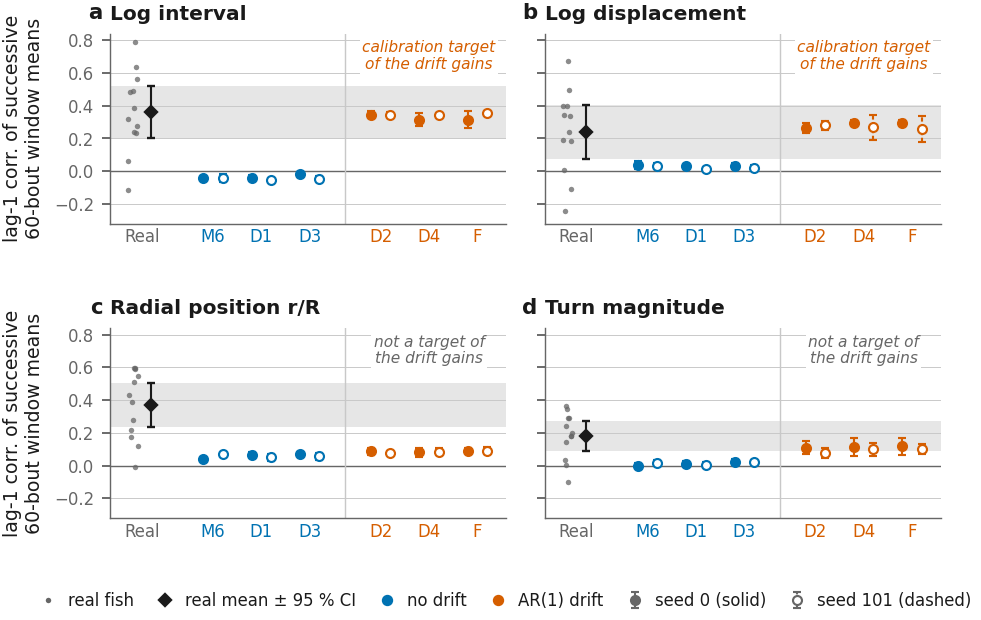

real fish with a defined value: [0, 1, 2, 3, 5, 7, 8, 9, 11, 12, 13, 14] (NaN: [4, 6, 10])
Log interval      real  mean +0.3635  95% CI [+0.2048, +0.5221]  n=12  per-fish range [-0.1136, +0.7865]  fish > 0: 11/12
                  M6    s0 -0.0430 [-0.0542, -0.0318]  -> -0.04  |  s101 -0.0408 [-0.0645, -0.0171]  -> -0.04
                  D1    s0 -0.0446 [-0.0632, -0.0260]  -> -0.04  |  s101 -0.0542 [-0.0643, -0.0442]  -> -0.05
                  D3    s0 -0.0203 [-0.0379, -0.0027]  -> -0.02  |  s101 -0.0495 [-0.0688, -0.0302]  -> -0.05
                  D2    s0 +0.3449 [+0.3241, +0.3657]  -> +0.34  |  s101 +0.3417 [+0.3237, +0.3597]  -> +0.34
                  D4    s0 +0.3149 [+0.2728, +0.3570]  -> +0.31  |  s101 +0.3421 [+0.3293, +0.3550]  -> +0.34
                  F     s0 +0.3151 [+0.2622, +0.3681]  -> +0.32  |  s101 +0.3522 [+0.3399, +0.3646]  -> +0.35
Log displacement  real  mean +0.2418  95% CI [+0.0770, +0.4066]  n=12  per-fish range [-0.2441, +0.6749]  fish > 0: 10/12
     

In [7]:
from figures import fig_slow
fig_slow.main()

<a id="distance-to-the-dots-figure-fig-profiles-and-the"></a>
## Distance to the dots (Figure fig:profiles) and the between-fish bands (Figures fig:app-bands-*,
Table tab:profile-spread)

[↑ back to contents](#contents)

  model key       metric  regenerated  archived    diff   ok
  M6 s0 26e          dip       3.6967     3.697 -0.0003 True
  M6 s0 26e          lat      10.5000    10.500  0.0000 True
  M6 s0 26e      plateau      17.7908    17.791 -0.0002 True
  M6 s0 26e   d1_plateau      21.6520    21.652  0.0000 True
  M6 s0 26e      grading       4.6690     4.669 -0.0000 True
  M6 s0 26e   mv_err_sem       0.8959     0.896 -0.0001 True
  M6 s0 26e   st_err_sem       0.8020     0.802 -0.0000 True
  M6 s0 26e static_drift       0.5231     0.523  0.0001 True
  M6 s0 26e      attr_N1       1.2994     1.300 -0.0006 True
  M6 s0 26e      attr_N2       3.3710     3.370  0.0010 True
  M6 s0 26e      attr_N4       4.7000     4.700  0.0000 True
  M6 s0 26e      attr_N6       4.8878     4.890 -0.0022 True
  M6 s0 26e      attr_N8       5.4349     5.430  0.0049 True
M6 s101 30d          dip       3.0151     3.015  0.0001 True
M6 s101 30d          lat       9.5000     9.500  0.0000 True
M6 s101 30d      plateau

  wrote figures/out/fig_profiles.pdf


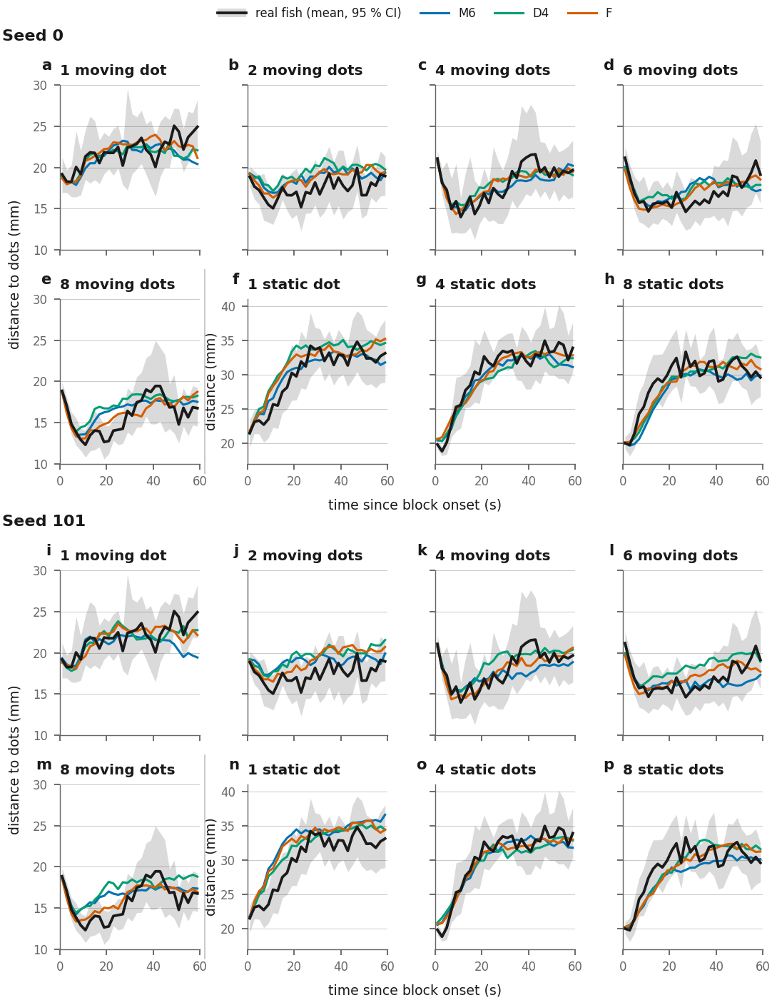

  wrote figures/out/fig_profiles_s0.pdf


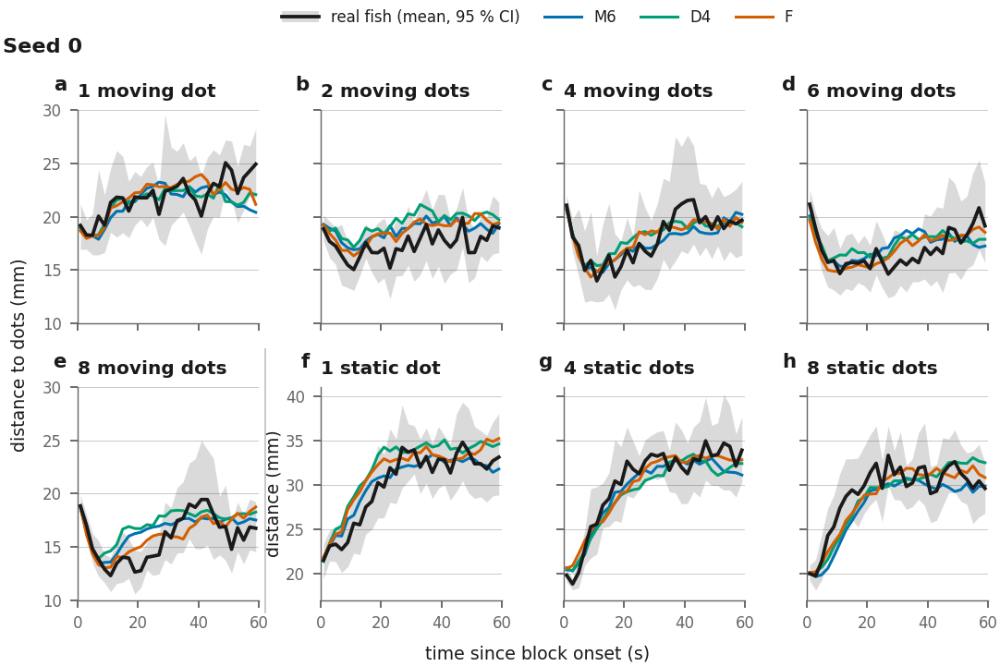

  wrote figures/out/fig_profiles_s101.pdf


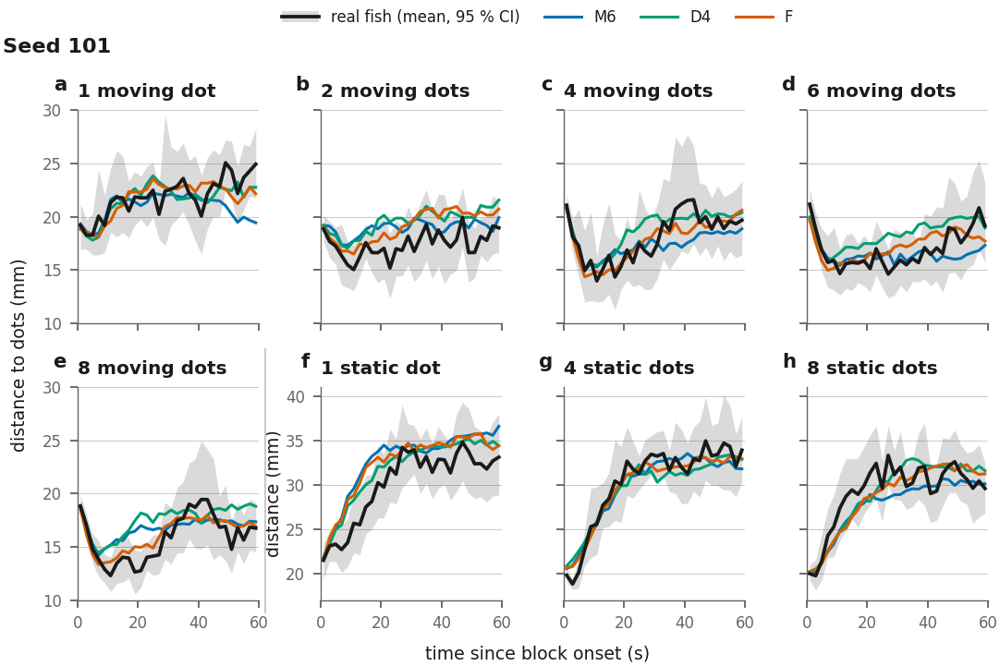

  M6 s0 (26e): bands done


  M6 s101 (30d): bands done


  F s0 (14f): bands done


  F s101 (32b): bands done


  D4 s0 (11e): bands done


  D4 s101 (32a): bands done


model / real band width (bouts thinned, 15 fish each, mean of 5 thinnings):
unit    M6 s0  M6 s101  D4 s0  D4 s101  F s0  F s101
cond                                                
d1s3.5   0.90     0.80   0.93     0.93  0.93    0.91
d2s3.5   0.86     0.97   1.11     1.01  1.02    1.05
d4s3.5   0.61     0.65   0.76     0.71  0.75    0.68
d6s3.5   0.71     0.71   0.83     0.87  0.80    0.79
d8s3.5   0.90     0.93   1.03     1.03  0.88    0.86
d1s0     0.87     0.92   0.90     0.87  0.89    0.85
d4s0     0.94     0.87   1.00     0.91  0.97    0.91
d8s0     0.84     0.90   0.91     0.84  0.97    0.93
largest SD over thinnings: 0.017


  wrote figures/out/fig_profiles_bands_M6.pdf


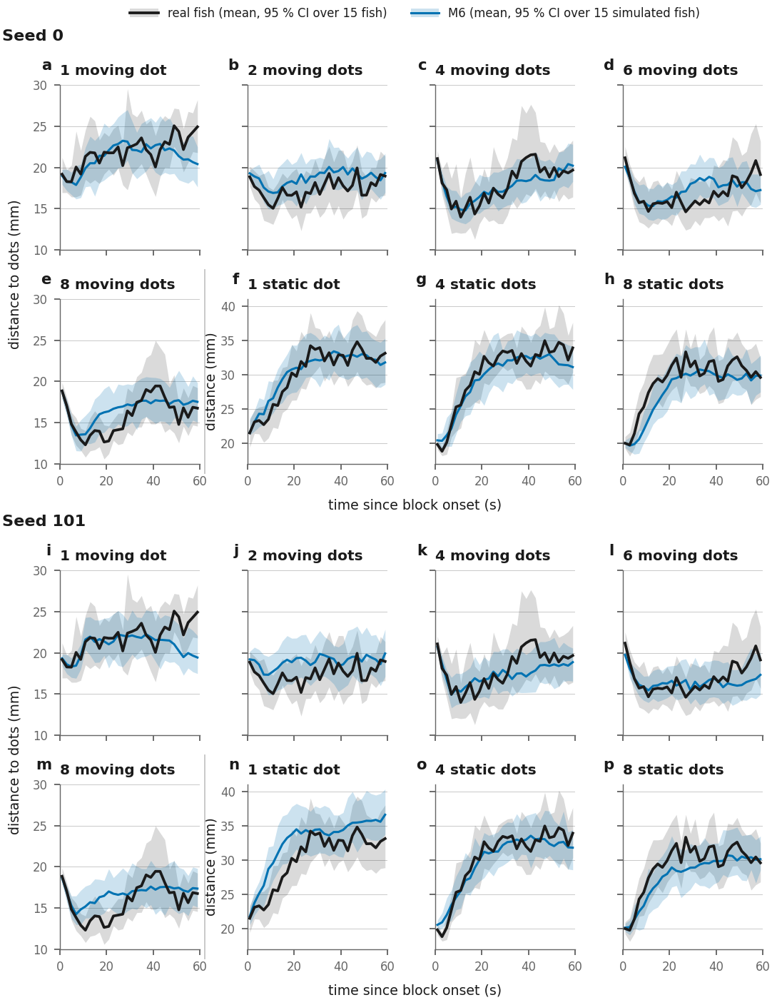

  wrote figures/out/fig_profiles_bands_D4.pdf


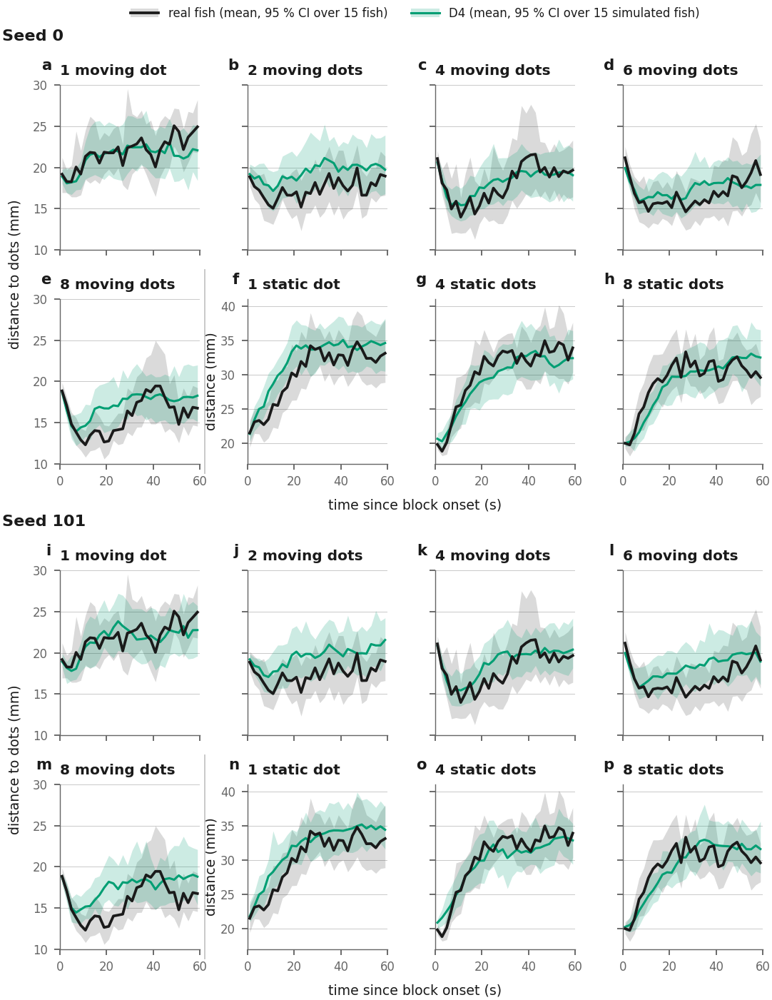

  wrote figures/out/fig_profiles_bands_F.pdf


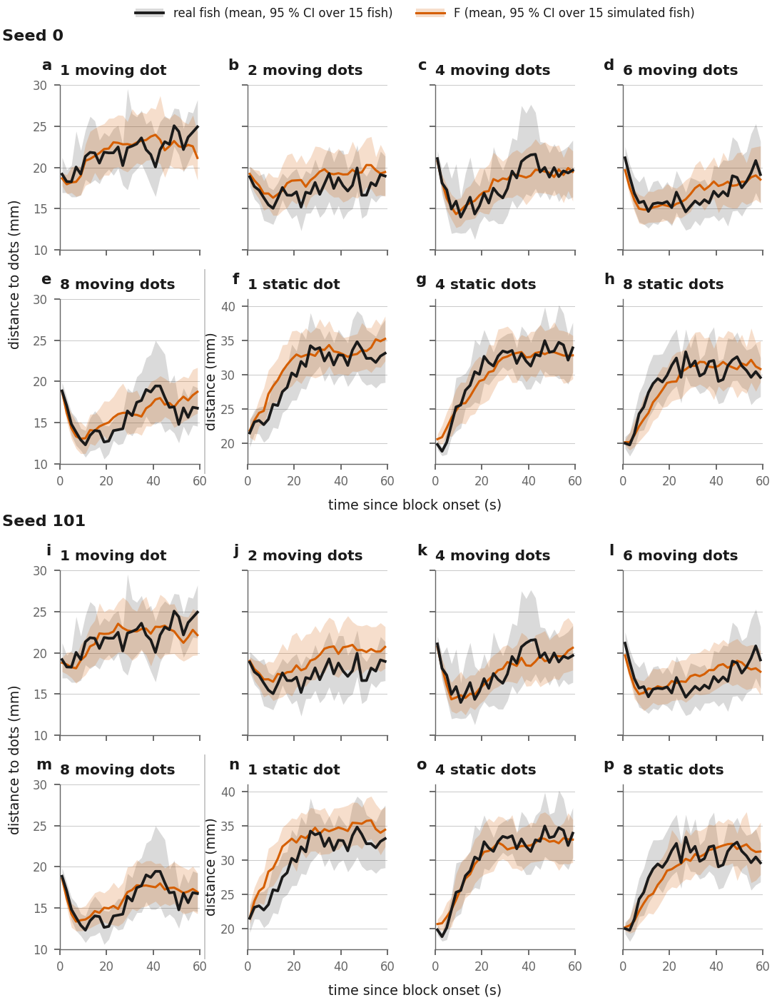

In [8]:
from figures import fig_profiles, fig_profiles_bands
fig_profiles.main([])
fig_profiles_bands.main()

In [9]:
r = pd.read_csv(fig_profiles.CACHE / "fig_profiles_bands_ratio.csv")
r.pivot_table(index="cond", columns=["model", "seed"], values="ratio", sort=False).round(2)

model     M6           F          D4      
seed     0     101   0     101   0     101
cond                                      
d1s3.5  0.90  0.80  0.93  0.91  0.93  0.93
d2s3.5  0.86  0.97  1.02  1.05  1.11  1.01
d4s3.5  0.61  0.65  0.75  0.68  0.76  0.71
d6s3.5  0.71  0.71  0.80  0.79  0.83  0.87
d8s3.5  0.90  0.93  0.88  0.86  1.03  1.03
d1s0    0.87  0.92  0.89  0.85  0.90  0.87
d4s0    0.94  0.87  0.97  0.91  1.00  0.91
d8s0    0.84  0.90  0.97  0.93  0.91  0.84

<a id="how-the-latent-gain-the-drift-gains-and-the-corr"></a>
## How the latent gain, the drift gains and the correction were set (Figures fig:app-latent-gain,
fig:app-drift-gain, fig:app-correction-trace)

[↑ back to contents](#contents)

latent gain chosen: [0.7]


  wrote figures/out/fig_app_latent_gain.pdf


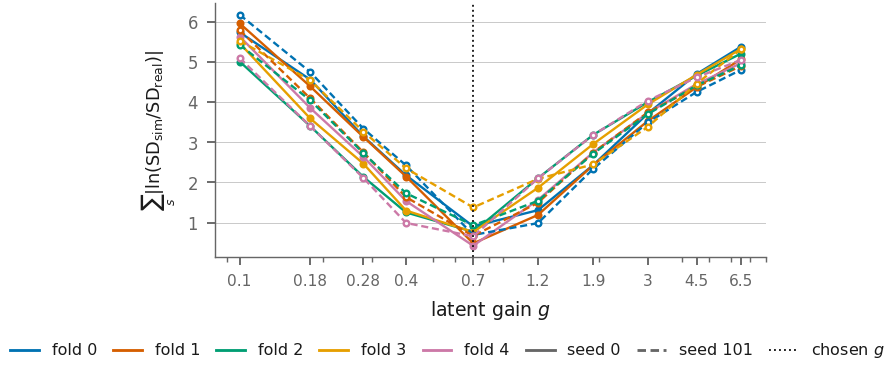

drift gains (D4), per fold: g_dist, g_dt, pick
  s0 fold 0: g_dist 0.40 (ok), g_dt 5.00 (saturated), target dist 0.274 dt 0.368
  s0 fold 1: g_dist 0.23 (ok), g_dt 2.46 (ok), target dist 0.249 dt 0.316
  s0 fold 2: g_dist 1.78 (ok), g_dt 0.47 (ok), target dist 0.291 dt 0.319
  s0 fold 3: g_dist 1.03 (ok), g_dt 1.34 (ok), target dist 0.320 dt 0.377
  s0 fold 4: g_dist 5.00 (saturated), g_dt 0.56 (ok), target dist 0.311 dt 0.319
  s101 fold 0: g_dist 3.29 (ok), g_dt 0.75 (ok), target dist 0.271 dt 0.322
  s101 fold 1: g_dist 0.15 (saturated), g_dt 0.58 (ok), target dist 0.290 dt 0.343
  s101 fold 2: g_dist 0.60 (ok), g_dt 1.72 (ok), target dist 0.279 dt 0.335
  s101 fold 3: g_dist 0.39 (ok), g_dt 5.00 (saturated), target dist 0.300 dt 0.344
  s101 fold 4: g_dist 2.27 (ok), g_dt 0.88 (ok), target dist 0.304 dt 0.355


  wrote figures/out/fig_app_drift_gain.pdf


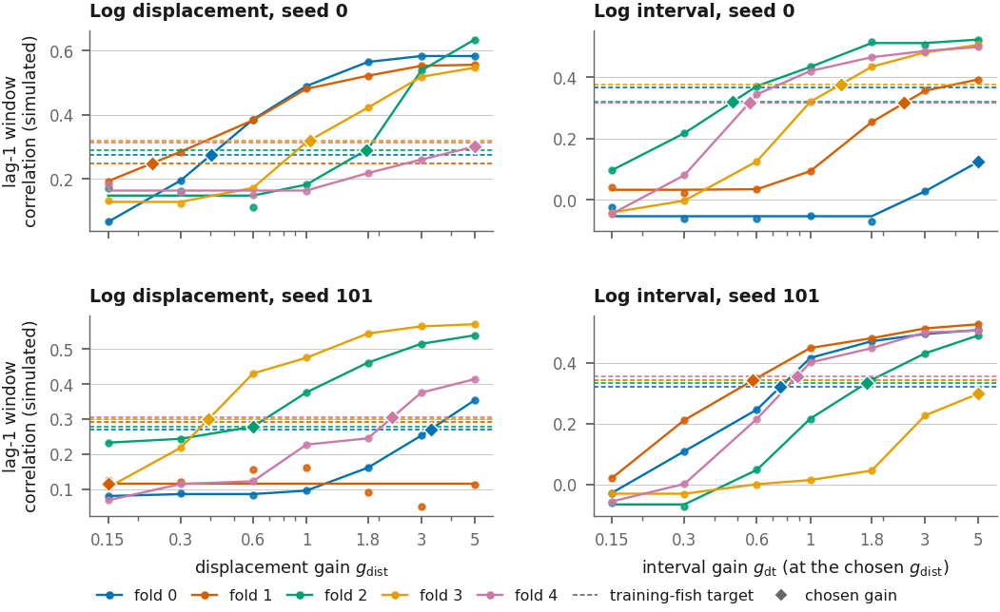

correction, final step (s0 | s101), per fold:
  s0 fold 0: profile 117.4 -> 105.8 (-9.9%), nll 9.1794 -> 9.1889 (+0.0095), kappa F/B 0.23 / 7.27
  s0 fold 1: profile 204.4 -> 147.0 (-28.1%), nll 9.1424 -> 9.1614 (+0.0190), kappa F/B 0.14 / 0.40
  s0 fold 2: profile 141.5 -> 126.0 (-11.0%), nll 9.2787 -> 9.2315 (-0.0472), kappa F/B 0.24 / 0.41
  s0 fold 3: profile 349.6 -> 267.8 (-23.4%), nll 8.9773 -> 8.9912 (+0.0139), kappa F/B 0.18 / 1.51
  s0 fold 4: profile 396.8 -> 196.5 (-50.5%), nll 9.1921 -> 9.1823 (-0.0098), kappa F/B 0.13 / 0.24
  s101 fold 0: profile 215.9 -> 176.6 (-18.2%), nll 9.0538 -> 9.0855 (+0.0317), kappa F/B 0.14 / 0.70
  s101 fold 1: profile 262.0 -> 186.1 (-29.0%), nll 9.1069 -> 9.0868 (-0.0200), kappa F/B 0.22 / 1.64
  s101 fold 2: profile 222.3 -> 116.1 (-47.8%), nll 9.1246 -> 9.1074 (-0.0172), kappa F/B 0.15 / 1.64
  s101 fold 3: profile 156.0 -> 122.7 (-21.4%), nll 9.1746 -> 9.1239 (-0.0507), kappa F/B 9.80 / 2.18
  s101 fold 4: profile 243.5 -> 144.9 (-40.5%),

  wrote figures/out/fig_app_correction_trace.pdf


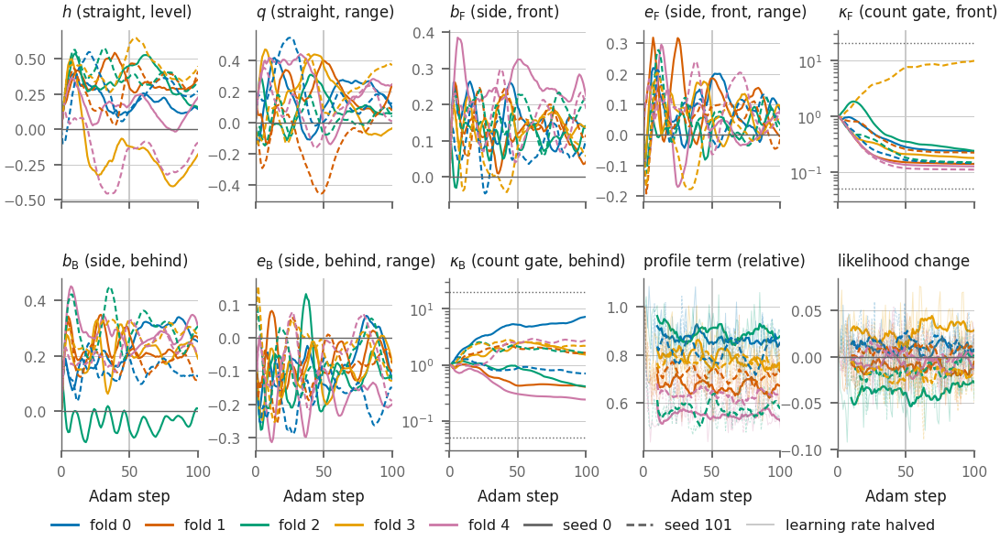

In [10]:
from figures import fig_app_training
fig_app_training.fig_latent()
fig_app_training.fig_drift()
fig_app_training.fig_correction()

<a id="every-model-s-measurements-on-held-out-fish"></a>
## Every model's measurements on held-out fish

The saved outputs of `unit_eval.evaluate`, the nine measurements of `unit_eval.CELLS` per unit; a unit with no saved evaluation is evaluated first.

[↑ back to contents](#contents)

### M1, seed 0


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.536
interval         1.222
joint           13.419

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
arms filter ['S0_adt'] -> writing panelB_model1_S0_adt.csv / c2st_model1_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_S0_adt.csv  (15 rows) in 1638s

Metric B, mean over held-out fish (lower = closer to real):
arm                      S0_adt
abs_dtheta_w1            6.6508
symbol_js                0.0064
dt_w1                    0.2216
dist_w1                  2.5233
trans_js                 0.0082
acf_l2                   0.0488
runlen_w1                0.1391
bigram_H_gap             0.0745
tuning_mse               0.0193
following_gap_h          0.0373
following_gap_static_h   0.0330
dot_dist_w1             13

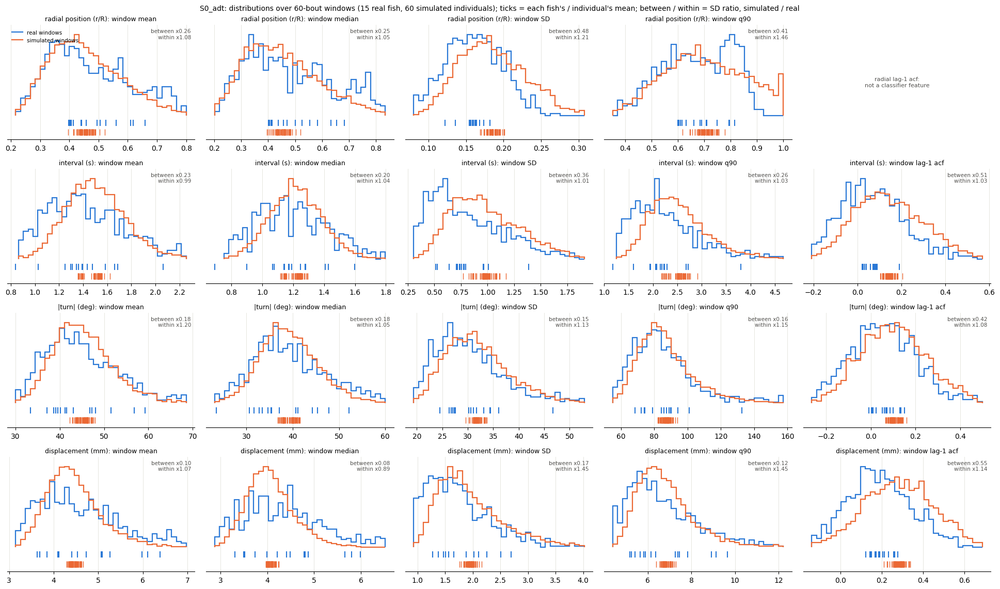


== distance to the dots across the block
  S0_adt_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.09  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.0 +/- 0.7
d2s3.5    2.96     2.36  2.64  0.99  11.0  19.0                  17.4 +/- 0.9  20.3 +/- 0.7
d4s3.5    2.85     1.78  4.68  1.49  19.0   7.0                  18.7 +/- 1.7  20.9 +/- 0.8
d6s3.5    4.10     3.02  4.62  0.23  13.0   5.0                  16.7 +/- 1.3  20.8 +/- 0.8
d8s3.5    4.45     4.15  4.97  0.47  11.0  11.0                  16.3 +/- 1.0  20.8 +/- 0.8
d1s0      3.21     1.70           

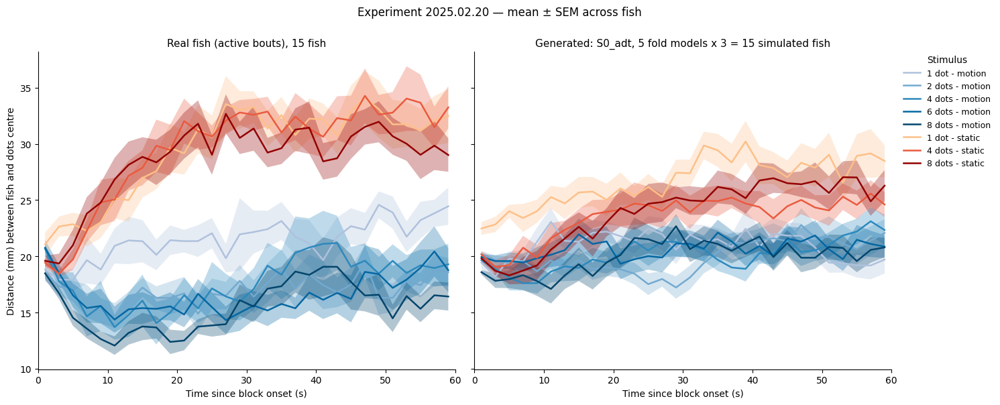


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                 

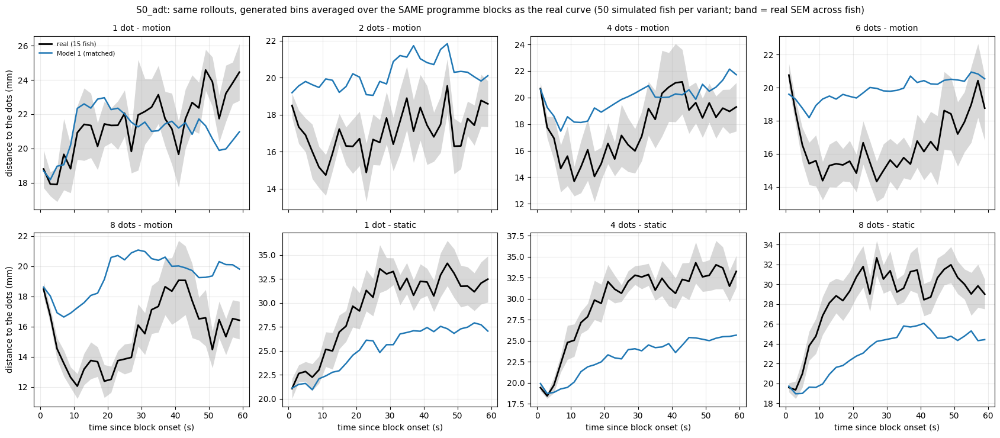


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   20.88  22.27       1.39
d2s3.5       17.39  23.58       6.19   20.41  22.17       1.75
d4s3.5       18.74  23.93       5.19   20.94  22.17       1.23
d6s3.5       16.69  23.12       6.43   20.66  22.01       1.35
d8s3.5       16.41  23.36       6.94   21.02  22.06       1.04

== turn toward the moving dots by dot count
           real  S0_adt
win    N               
0-20 s 1   9.09    9.08
       2  13.90    9.59
       4  15.73   10.37
       6  14.50   10.33
       8  16.00   11.55
4-20 s 1   6.25    8.61
       2  12.27    9.21
  

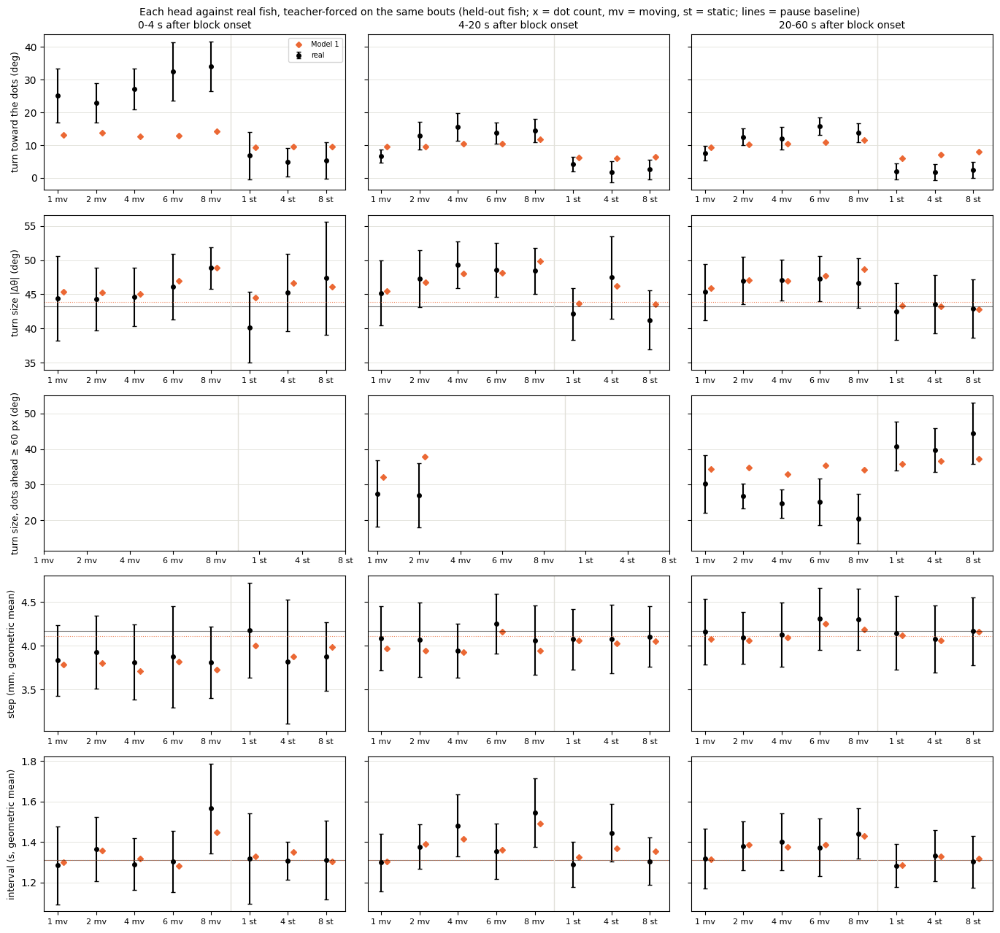

In [11]:
unit_eval.show('1')

### M1, seed 101


== held-out likelihood per head (bits per bout)
turn             7.663
displacement     4.557
interval         1.233
joint           13.453

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
arms filter ['S0_adt'] -> writing panelB_model1_S0_adt.csv / c2st_model1_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_S0_adt.csv  (15 rows) in 744s

Metric B, mean over held-out fish (lower = closer to real):
arm                      S0_adt
abs_dtheta_w1            7.3878
symbol_js                0.0077
dt_w1                    0.2380
dist_w1                  2.7152
trans_js                 0.0094
acf_l2                   0.0446
runlen_w1                0.1282
bigram_H_gap             0.0857
tuning_mse               0.0200
following_gap_h          0.0349
following_gap_static_h   0.0314
dot_dist_w1             12.

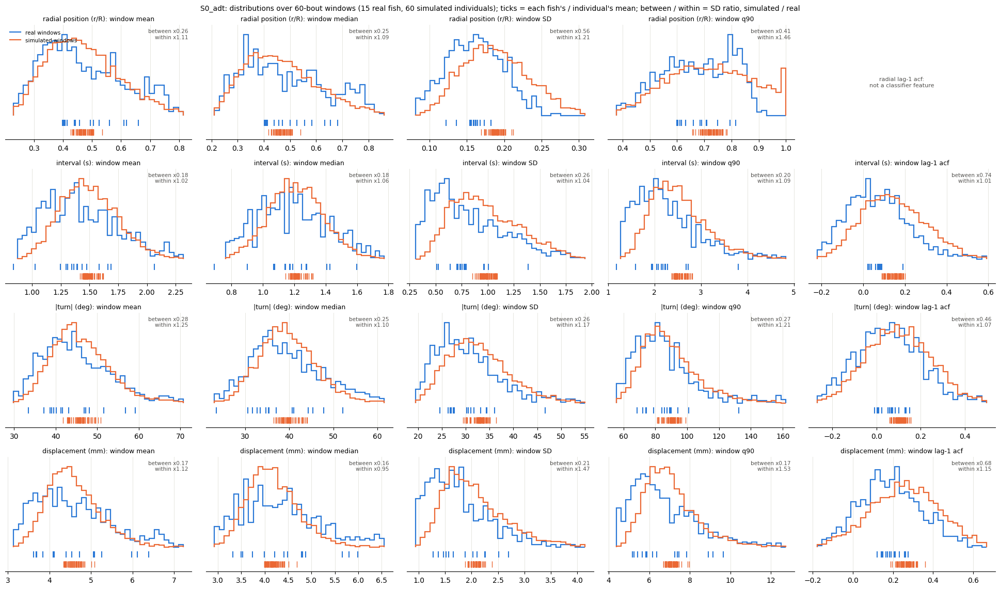


== distance to the dots across the block
  S0_adt_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.10     0.80  0.15  0.58   3.0   7.0                  22.3 +/- 0.9  21.7 +/- 0.8
d2s3.5    3.77     2.94  2.64  0.33  11.0   9.0                  17.4 +/- 0.9  21.6 +/- 0.7
d4s3.5    3.17     1.98  4.68  0.94  19.0   5.0                  18.7 +/- 1.7  21.1 +/- 0.6
d6s3.5    3.56     2.60  4.62  2.17  13.0   7.0                  16.7 +/- 1.3  20.9 +/- 0.8
d8s3.5    4.38     4.02  4.97  0.45  11.0   5.0                  16.3 +/- 1.0  20.7 +/- 0.9
d1s0      2.61     1.38           

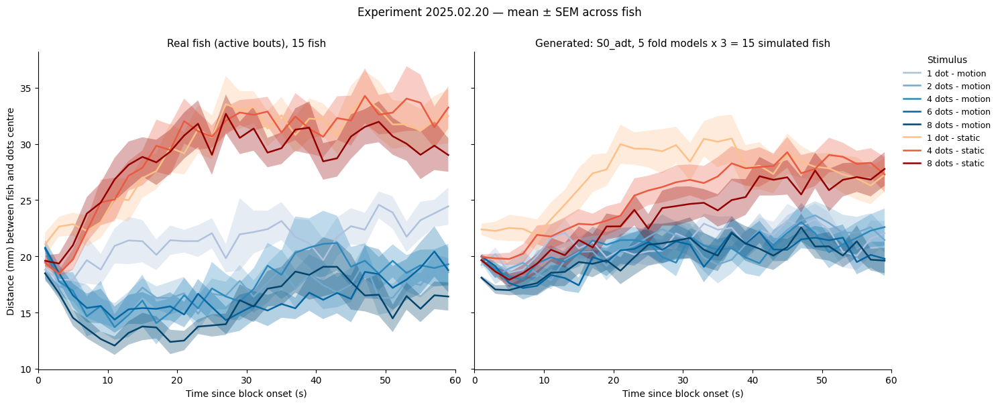


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

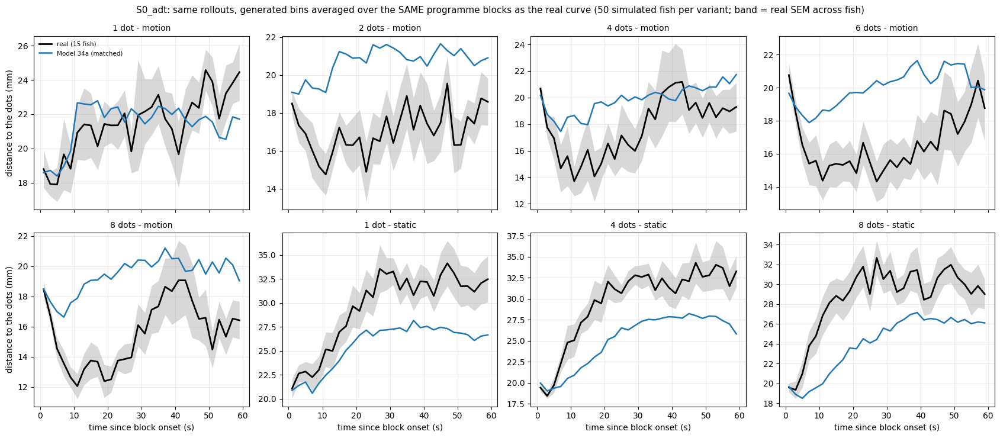


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   22.07  23.16       1.09
d2s3.5       17.39  23.58       6.19   21.77  23.12       1.35
d4s3.5       18.74  23.93       5.19   20.81  23.13       2.32
d6s3.5       16.69  23.12       6.43   21.09  23.21       2.12
d8s3.5       16.41  23.36       6.94   20.47  22.93       2.45

== turn toward the moving dots by dot count
           real  S0_adt
win    N               
0-20 s 1   9.09    9.51
       2  13.90    9.91
       4  15.73   10.99
       6  14.50   10.62
       8  16.00   12.01
4-20 s 1   6.25    8.97
       2  12.27    9.64
  

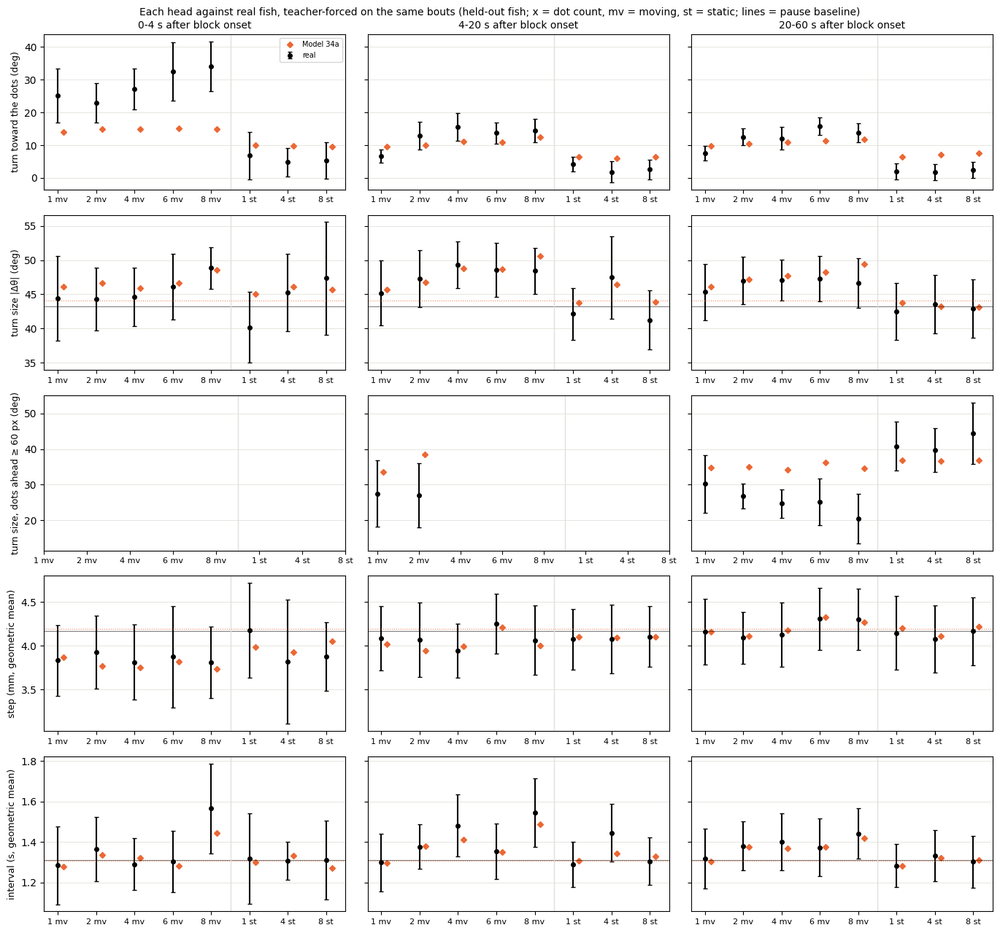

In [12]:
unit_eval.show('34a')

### M2, seed 0


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.536
interval         1.222
joint           13.419

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt'] -> writing panelB_model1_rej_S0_adt.csv / c2st_model1_rej_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt.csv  (15 rows) in 1647s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_rej
abs_dtheta_w1               6.5251
symbol_js                   0.0064
dt_w1                       0.2172
dist_w1                     2.4957
trans_js                    0.0082
acf_l2                      0.0489
runlen_w1                   0.1389
bi

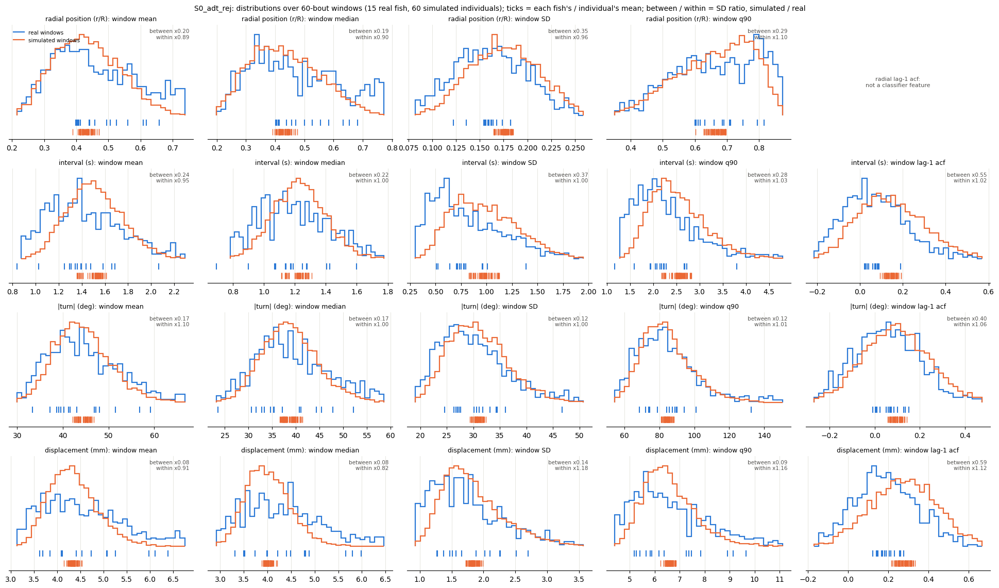


== distance to the dots across the block
  S0_adt_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.56     1.08  0.15  0.37   3.0   3.0                  22.3 +/- 0.9  23.1 +/- 1.0
d2s3.5    2.92     2.33  2.64  1.86  11.0  11.0                  17.4 +/- 0.9  20.4 +/- 0.6
d4s3.5    2.64     1.59  4.68   1.8  19.0   7.0                  18.7 +/- 1.7  21.3 +/- 0.8
d6s3.5    3.35     2.45  4.62  1.12  13.0   5.0                  16.7 +/- 1.3  20.3 +/- 0.5
d8s3.5    3.17     2.99  4.97  1.21  11.0   7.0                  16.3 +/- 1.0  19.3 +/- 1.0
d1s0      4.38     2.40            

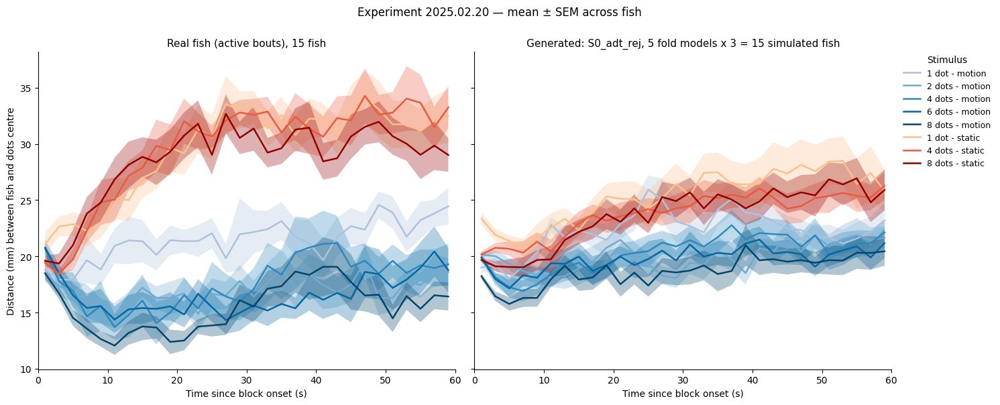


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                 

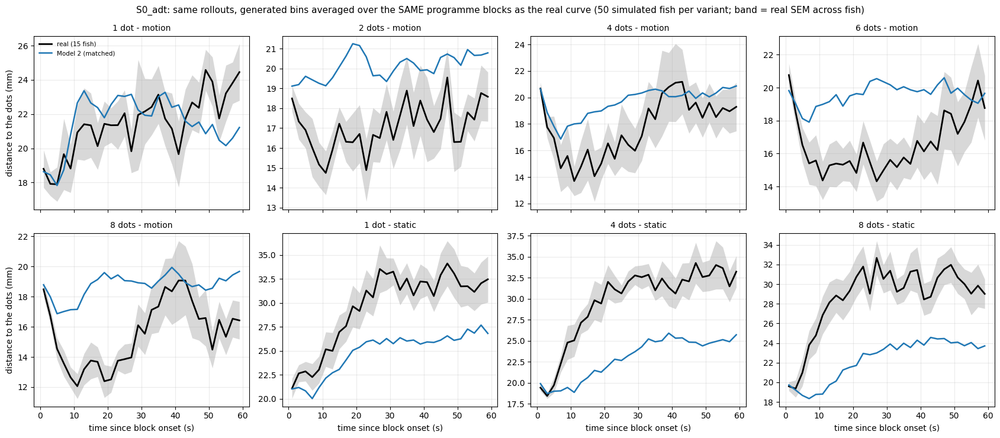


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   22.36  21.70      -0.66
d2s3.5       17.39  23.58       6.19   20.40  21.48       1.08
d4s3.5       18.74  23.93       5.19   21.22  21.61       0.39
d6s3.5       16.69  23.12       6.43   20.29  21.75       1.46
d8s3.5       16.41  23.36       6.94   19.37  21.64       2.27

== turn toward the moving dots by dot count
           real  S0_adt
win    N               
0-20 s 1   9.09    9.08
       2  13.90    9.59
       4  15.73   10.37
       6  14.50   10.33
       8  16.00   11.55
4-20 s 1   6.25    8.61
       2  12.27    9.21
  

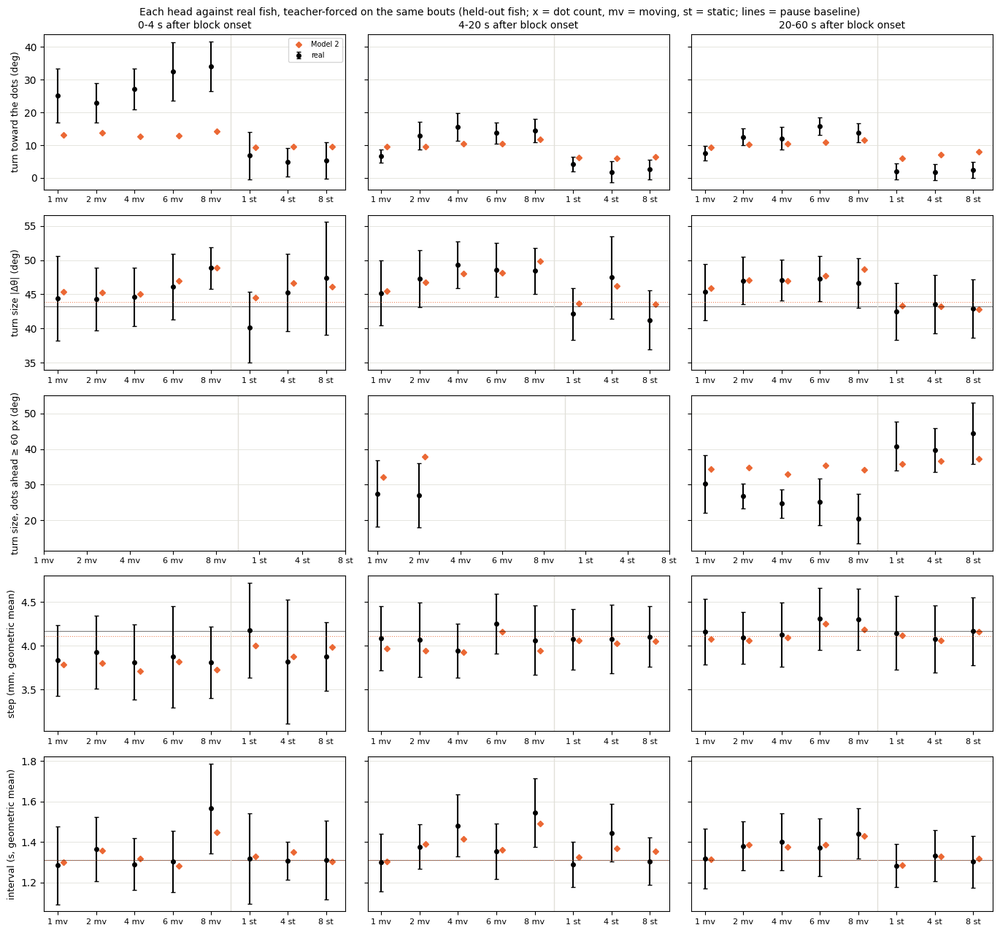

In [13]:
unit_eval.show('2')

### M2, seed 101


== held-out likelihood per head (bits per bout)
turn             7.663
displacement     4.557
interval         1.233
joint           13.453

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt'] -> writing panelB_model1_rej_S0_adt.csv / c2st_model1_rej_S0_adt.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt.csv  (15 rows) in 830s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_rej
abs_dtheta_w1               7.0409
symbol_js                   0.0077
dt_w1                       0.2342
dist_w1                     2.6824
trans_js                    0.0095
acf_l2                      0.0448
runlen_w1                   0.1296
big

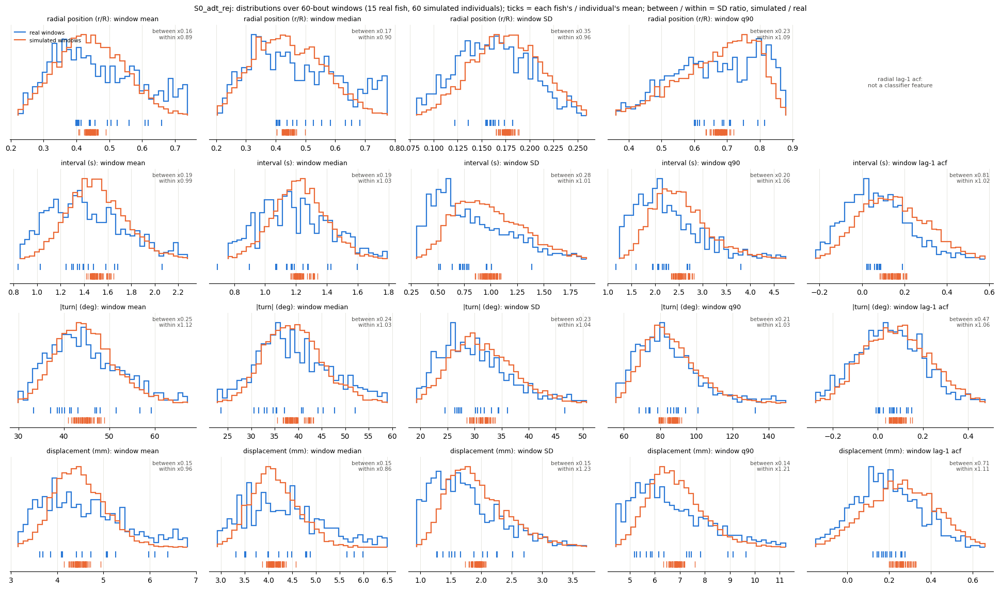


== distance to the dots across the block
  S0_adt_fold4.pt: 3 rollouts
dropped 9.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.08     0.75  0.15  0.33   3.0   5.0                  22.3 +/- 0.9  21.8 +/- 0.6
d2s3.5    3.04     2.37  2.64  0.77  11.0   5.0                  17.4 +/- 0.9  20.6 +/- 0.5
d4s3.5    3.37     2.11  4.68   0.4  19.0   5.0                  18.7 +/- 1.7  21.8 +/- 0.8
d6s3.5    3.80     2.66  4.62  0.44  13.0   5.0                  16.7 +/- 1.3  20.7 +/- 0.7
d8s3.5    4.65     4.40  4.97  0.29  11.0   9.0                  16.3 +/- 1.0  20.7 +/- 0.4
d1s0      3.07     1.68            

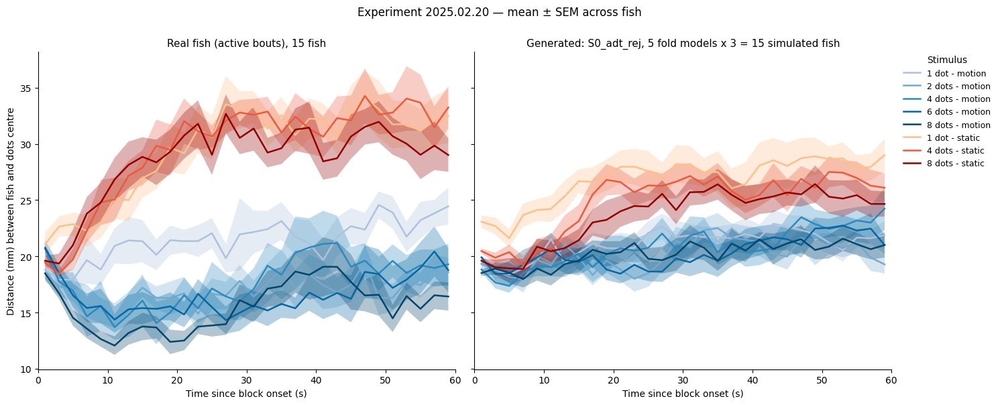


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

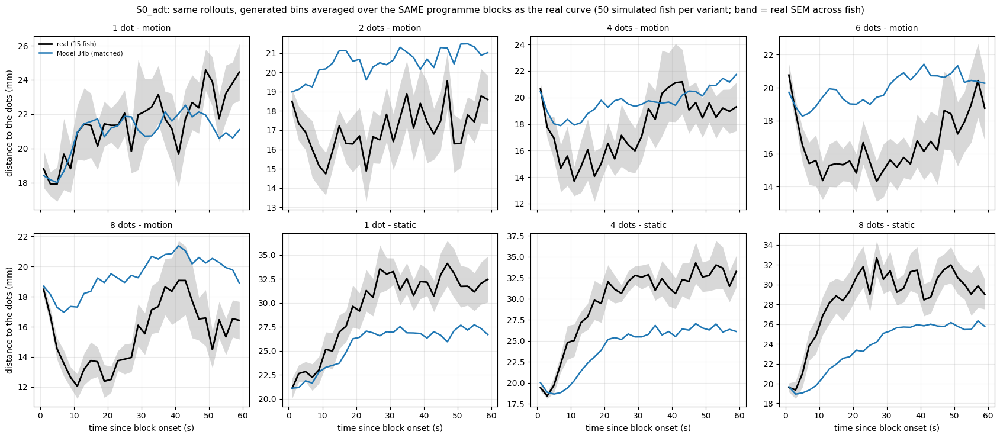


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                    S0_adt                  
           plateau   null attraction plateau   null attraction
cond_label                                                    
d1s3.5       22.41  23.57       1.16   21.82  21.93       0.11
d2s3.5       17.39  23.58       6.19   20.53  21.79       1.27
d4s3.5       18.74  23.93       5.19   21.30  21.73       0.42
d6s3.5       16.69  23.12       6.43   20.41  21.78       1.37
d8s3.5       16.41  23.36       6.94   20.79  21.92       1.12

== turn toward the moving dots by dot count
           real  S0_adt
win    N               
0-20 s 1   9.09    9.51
       2  13.90    9.91
       4  15.73   10.99
       6  14.50   10.62
       8  16.00   12.01
4-20 s 1   6.25    8.97
       2  12.27    9.64
  

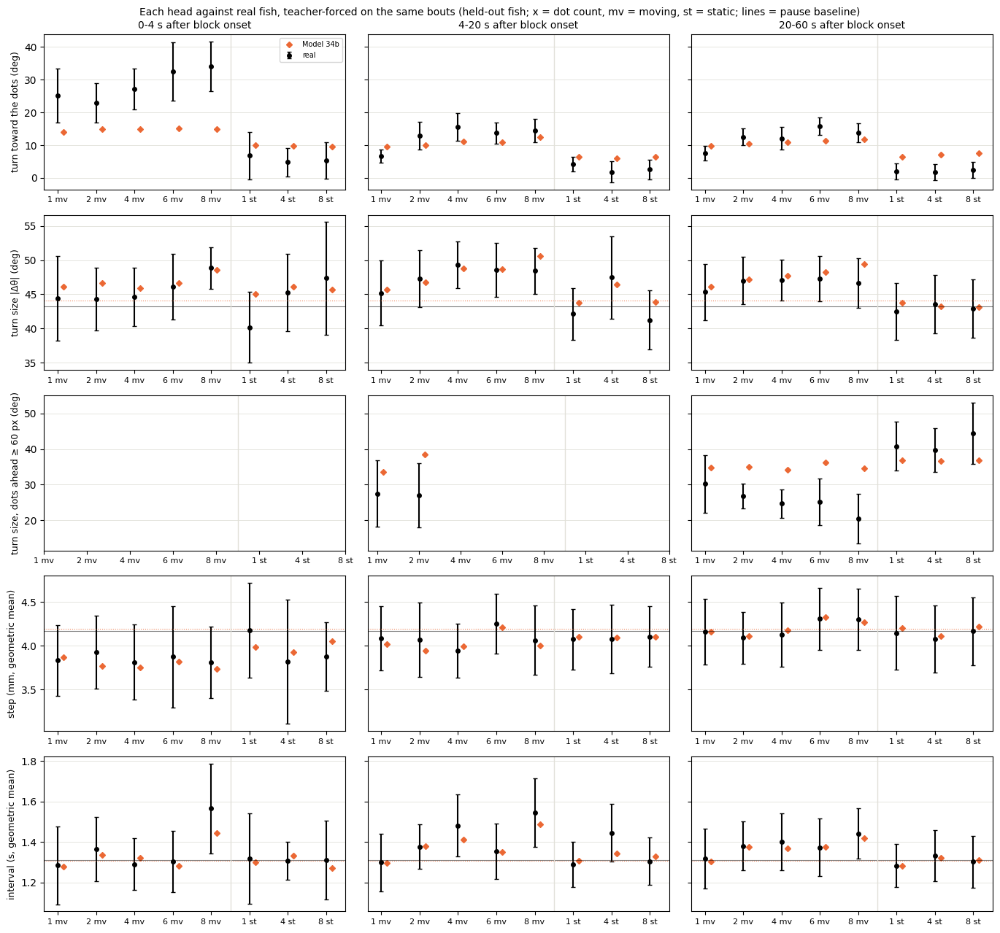

In [14]:
unit_eval.show('34b')

### M3, seed 0


== held-out likelihood per head (bits per bout)
turn             7.649
displacement     4.492
interval         1.221
joint           13.361

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt_z2'] -> writing panelB_model1_rej_S0_adt_z2.csv / c2st_model1_rej_S0_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt_z2.csv  (15 rows) in 1649s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_z2_rej
abs_dtheta_w1                  8.6045
symbol_js                      0.0124
dt_w1                          0.3506
dist_w1                        4.4595
trans_js                       0.0142
acf_l2                         0.0483
runl

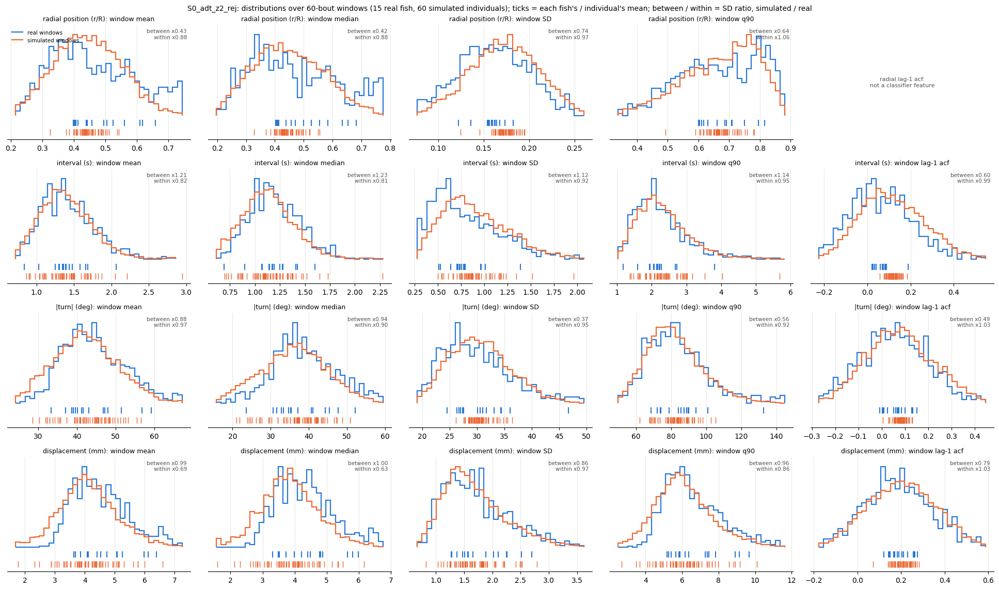


== distance to the dots across the block
  S0_adt_z2_fold4.pt: 3 rollouts
dropped 10.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.43     0.93  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.8 +/- 0.8
d2s3.5    3.95     3.12  2.64   0.0  11.0   1.0                  17.4 +/- 0.9  21.2 +/- 1.0
d4s3.5    2.60     1.63  4.68  1.17  19.0   9.0                  18.7 +/- 1.7  20.9 +/- 1.0
d6s3.5    3.00     2.18  4.62   0.8  13.0   7.0                  16.7 +/- 1.3  19.8 +/- 1.0
d8s3.5    4.46     4.12  4.97  0.76  11.0   5.0                  16.3 +/- 1.0  20.4 +/- 0.8
d1s0      3.70     2.03        

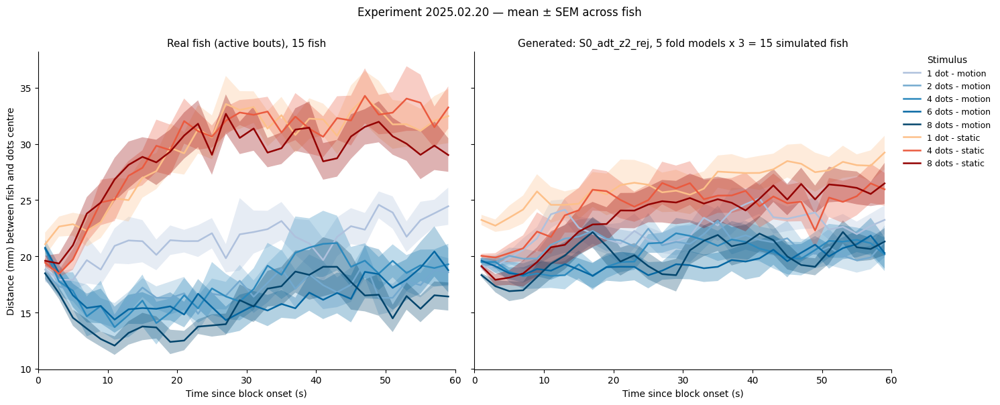


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                      mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                                 

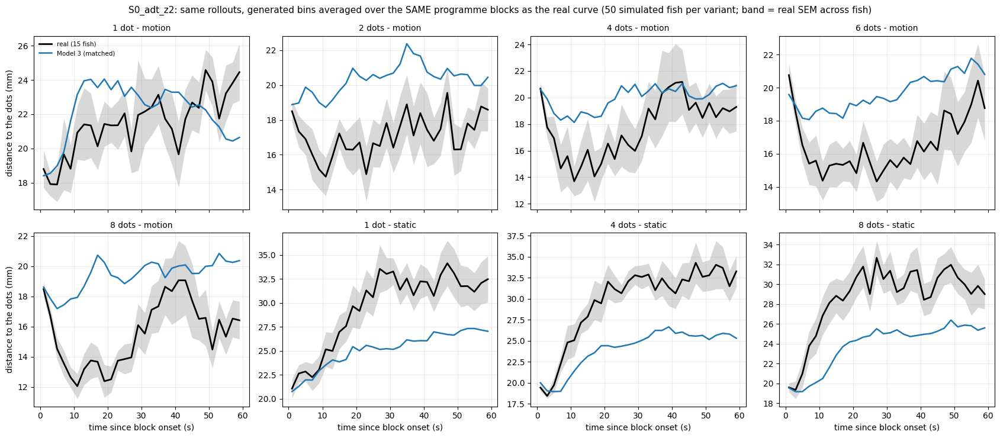


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S0_adt_z2                  
           plateau   null attraction   plateau   null attraction
cond_label                                                      
d1s3.5       22.41  23.57       1.16     22.80  22.26      -0.54
d2s3.5       17.39  23.58       6.19     21.34  22.30       0.95
d4s3.5       18.74  23.93       5.19     20.62  22.18       1.56
d6s3.5       16.69  23.12       6.43     20.30  22.15       1.85
d8s3.5       16.41  23.36       6.94     20.30  22.27       1.97

== turn toward the moving dots by dot count
           real  S0_adt_z2
win    N                  
0-20 s 1   9.09       8.24
       2  13.90       9.16
       4  15.73       9.62
       6  14.50       9.02
       8  16.00      10.52
4-20 s 1   6.

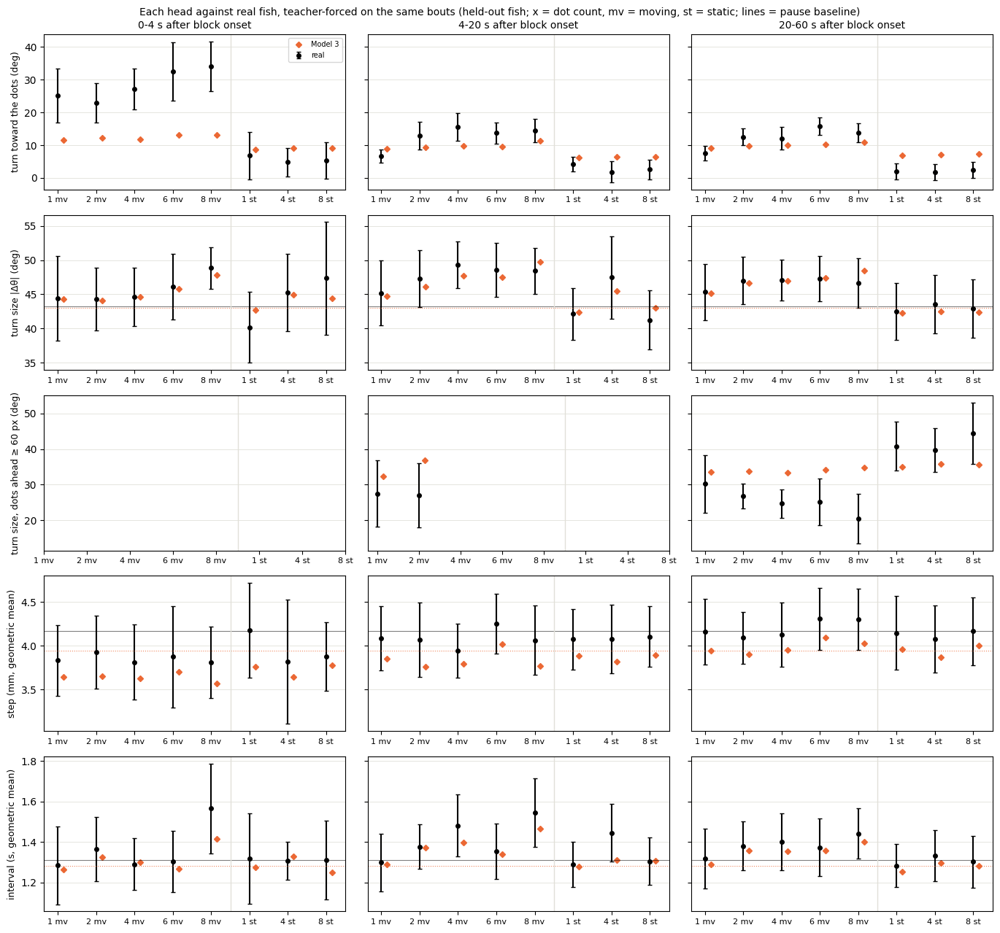

In [15]:
unit_eval.show('3')

### M3, seed 101


== held-out likelihood per head (bits per bout)
turn             7.663
displacement     4.479
interval         1.204
joint           13.346

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S0_adt_z2'] -> writing panelB_model1_rej_S0_adt_z2.csv / c2st_model1_rej_S0_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S0_adt_z2.csv  (15 rows) in 630s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S0_adt_z2_rej
abs_dtheta_w1                  9.1988
symbol_js                      0.0137
dt_w1                          0.4114
dist_w1                        4.3343
trans_js                       0.0154
acf_l2                         0.0508
runle

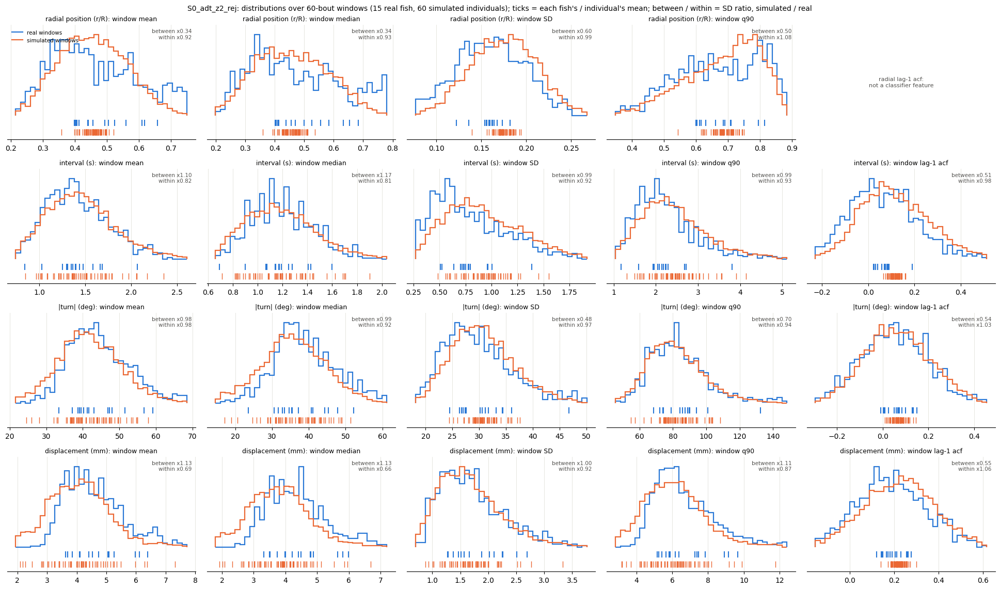


== distance to the dots across the block
  S0_adt_z2_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.50     1.05  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.1 +/- 0.5
d2s3.5    2.74     2.16  2.64  1.24  11.0  11.0                  17.4 +/- 0.9  20.4 +/- 0.6
d4s3.5    2.63     1.63  4.68  1.83  19.0   9.0                  18.7 +/- 1.7  20.8 +/- 0.5
d6s3.5    3.37     2.46  4.62  1.03  13.0   5.0                  16.7 +/- 1.3  20.3 +/- 0.9
d8s3.5    4.69     4.28  4.97  0.12  11.0   3.0                  16.3 +/- 1.0  20.9 +/- 1.1
d1s0      3.27     1.75        

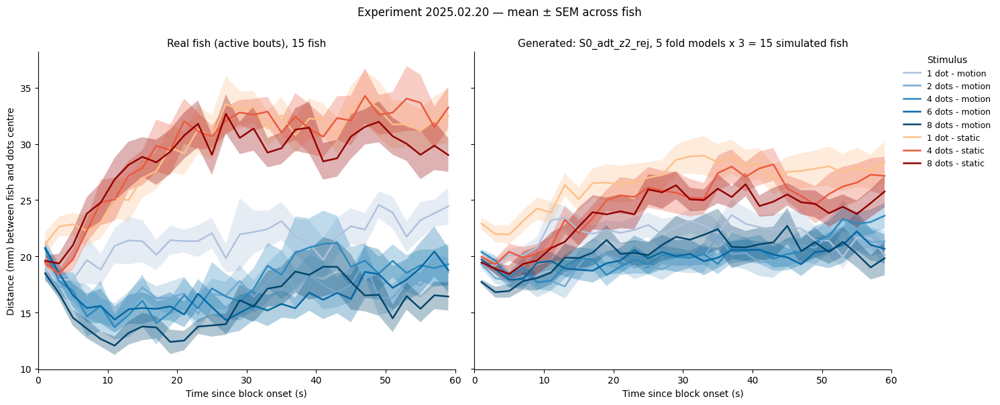


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

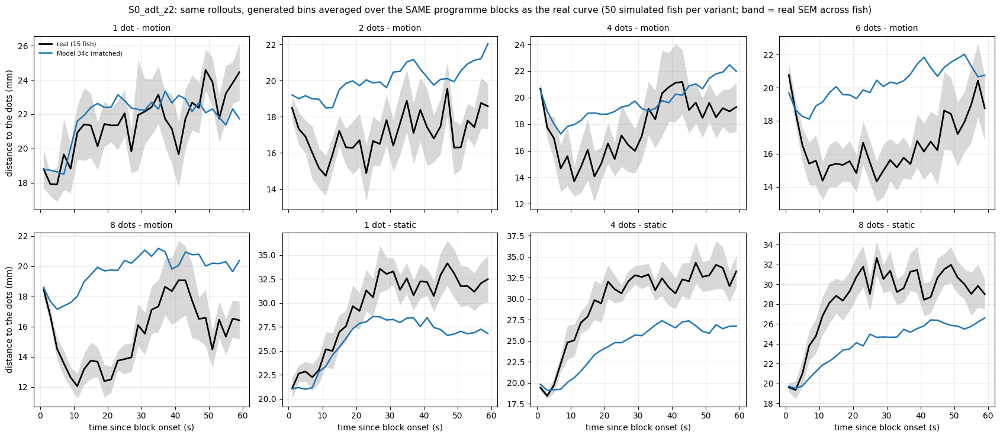


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S0_adt_z2                  
           plateau   null attraction   plateau   null attraction
cond_label                                                      
d1s3.5       22.41  23.57       1.16     22.43  22.71       0.28
d2s3.5       17.39  23.58       6.19     21.04  22.59       1.55
d4s3.5       18.74  23.93       5.19     21.18  22.69       1.51
d6s3.5       16.69  23.12       6.43     20.36  22.65       2.29
d8s3.5       16.41  23.36       6.94     20.85  22.30       1.44

== turn toward the moving dots by dot count
           real  S0_adt_z2
win    N                  
0-20 s 1   9.09       8.74
       2  13.90       9.22
       4  15.73      10.13
       6  14.50       9.74
       8  16.00      11.16
4-20 s 1   6.

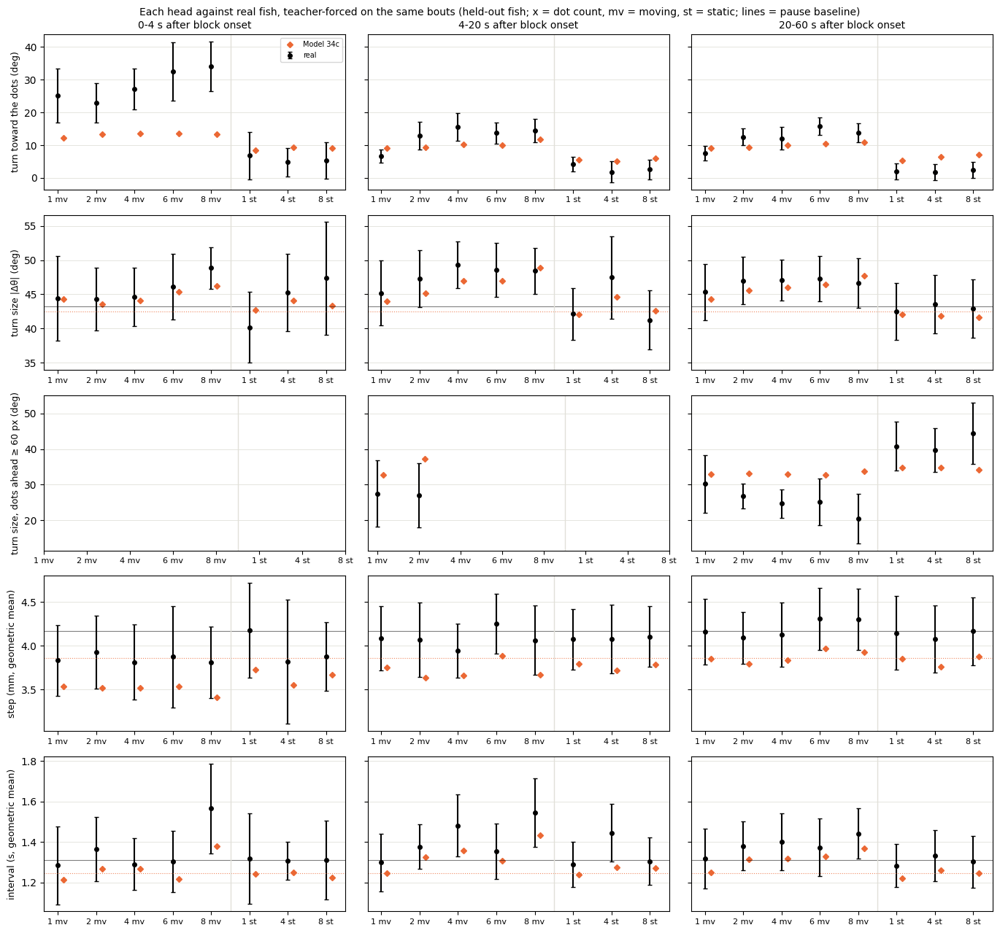

In [16]:
unit_eval.show('34c')

### M4, seed 0


== held-out likelihood per head (bits per bout)
turn             7.652
displacement     4.496
interval         1.217
joint           13.366

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2'] -> writing panelB_model1_rej_S4i_adt_z2.csv / c2st_model1_rej_S4i_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2.csv  (15 rows) in 592s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_rej
abs_dtheta_w1                   8.7680
symbol_js                       0.0125
dt_w1                           0.3823
dist_w1                         3.8186
trans_js                        0.0144
acf_l2                          0

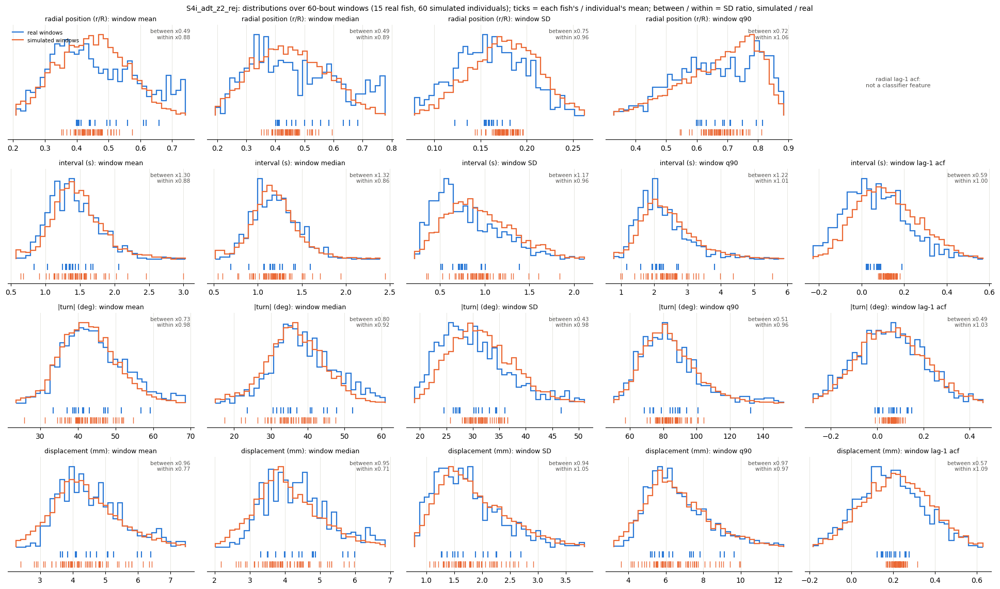


== distance to the dots across the block
  S4i_adt_z2_fold4.pt: 3 rollouts
dropped 8.4% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.98     1.38  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  20.9 +/- 0.7
d2s3.5    2.06     1.66  2.64   1.9  11.0  13.0                  17.4 +/- 0.9  18.9 +/- 1.0
d4s3.5    1.49     0.98  4.68   2.1  19.0   7.0                  18.7 +/- 1.7  19.4 +/- 0.8
d6s3.5    1.70     1.24  4.62  2.64  13.0   9.0                  16.7 +/- 1.3  17.9 +/- 0.7
d8s3.5    2.52     2.49  4.97  1.48  11.0   7.0                  16.3 +/- 1.0  17.8 +/- 0.9
d1s0      1.48     0.87        

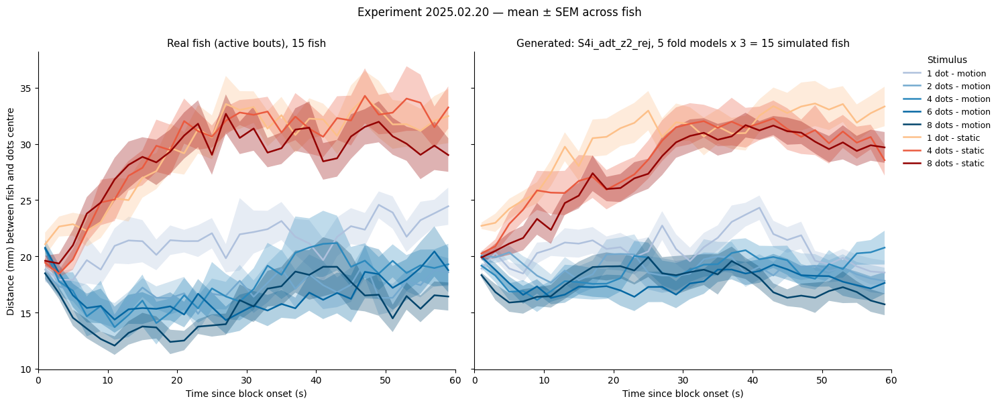


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

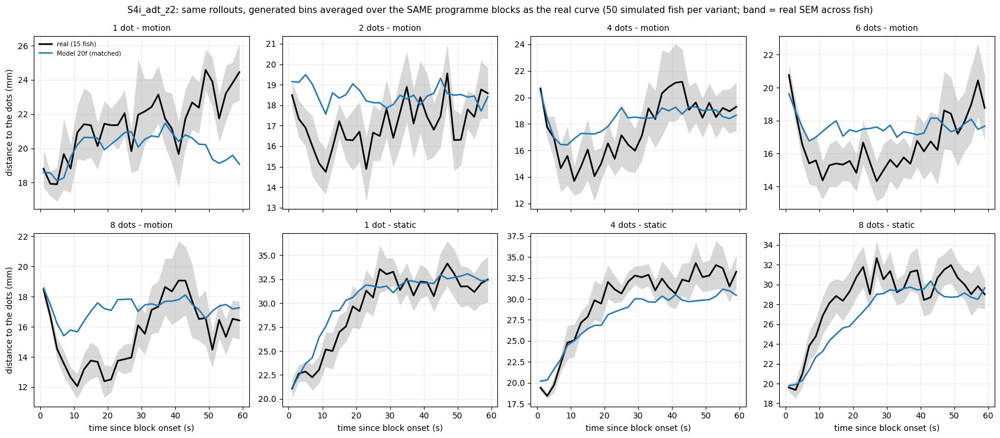


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2                  
           plateau   null attraction    plateau   null attraction
cond_label                                                       
d1s3.5       22.41  23.57       1.16      21.18  22.22       1.04
d2s3.5       17.39  23.58       6.19      18.95  22.23       3.28
d4s3.5       18.74  23.93       5.19      19.71  22.34       2.63
d6s3.5       16.69  23.12       6.43      18.33  22.09       3.76
d8s3.5       16.41  23.36       6.94      18.08  22.17       4.10

== turn toward the moving dots by dot count
           real  S4i_adt_z2
win    N                   
0-20 s 1   9.09       10.09
       2  13.90       10.92
       4  15.73       12.43
       6  14.50       12.57
       8  16.00       14.0

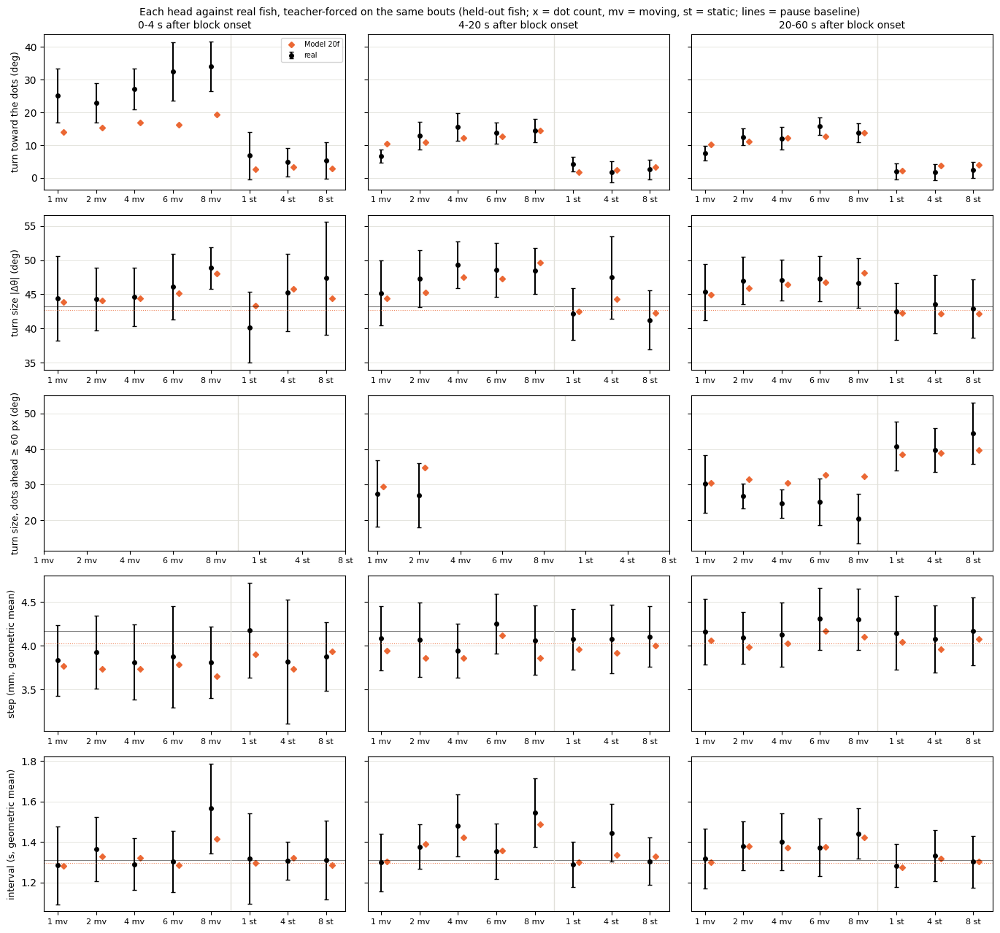

In [17]:
unit_eval.show('20f')

### M4, seed 101


== held-out likelihood per head (bits per bout)
turn             7.653
displacement     4.492
interval         1.211
joint           13.356

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2'] -> writing panelB_model1_rej_S4i_adt_z2.csv / c2st_model1_rej_S4i_adt_z2.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2.csv  (15 rows) in 661s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_rej
abs_dtheta_w1                   9.1707
symbol_js                       0.0147
dt_w1                           0.3560
dist_w1                         4.0135
trans_js                        0.0159
acf_l2                          0

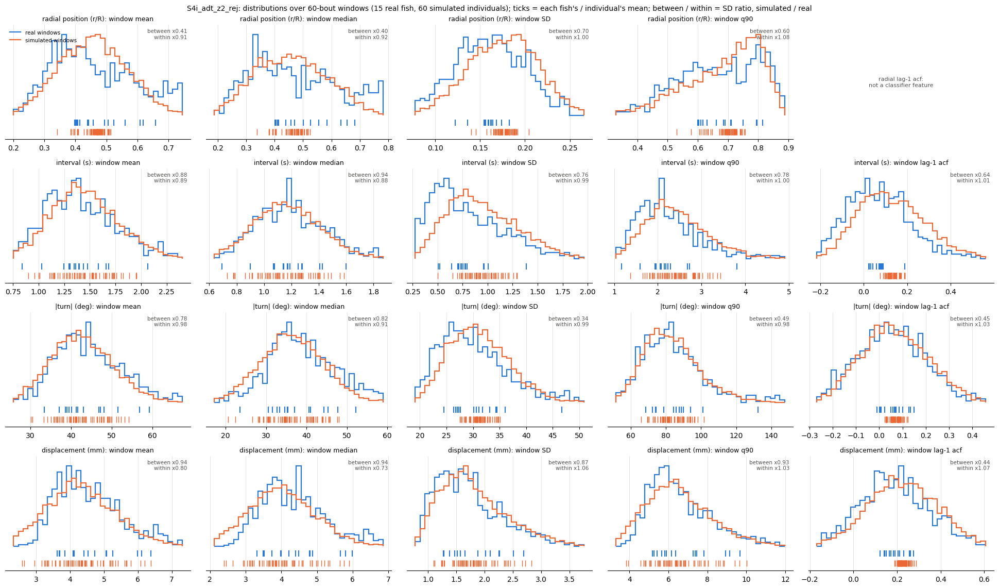


== distance to the dots across the block
  S4i_adt_z2_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.21     1.51  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  20.1 +/- 1.0
d2s3.5    1.71     1.37  2.64  1.96  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 0.8
d4s3.5    1.87     1.07  4.68  2.92  19.0   9.0                  18.7 +/- 1.7  18.8 +/- 1.1
d6s3.5    1.60     1.16  4.62  3.15  13.0  11.0                  16.7 +/- 1.3  17.8 +/- 0.9
d8s3.5    2.18     2.19  4.97  1.17  11.0  13.0                  16.3 +/- 1.0  17.7 +/- 0.9
d1s0      2.29     1.40       

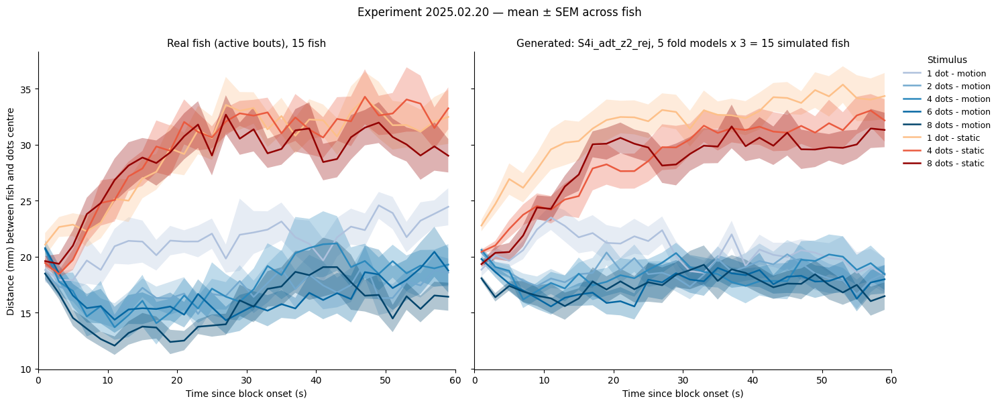


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

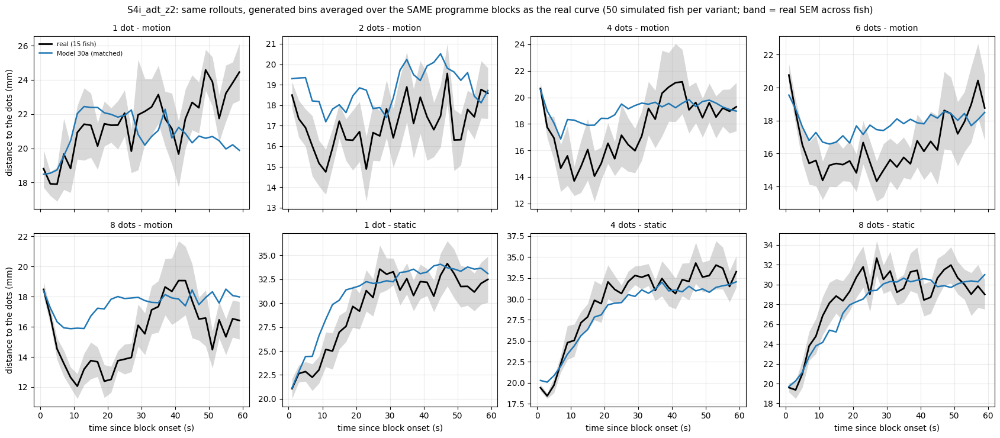


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2                  
           plateau   null attraction    plateau   null attraction
cond_label                                                       
d1s3.5       22.41  23.57       1.16      20.39  22.77       2.38
d2s3.5       17.39  23.58       6.19      18.62  22.31       3.69
d4s3.5       18.74  23.93       5.19      19.04  22.36       3.32
d6s3.5       16.69  23.12       6.43      18.19  22.25       4.06
d8s3.5       16.41  23.36       6.94      17.70  22.35       4.65

== turn toward the moving dots by dot count
           real  S4i_adt_z2
win    N                   
0-20 s 1   9.09        9.51
       2  13.90       10.46
       4  15.73       11.97
       6  14.50       12.01
       8  16.00       13.8

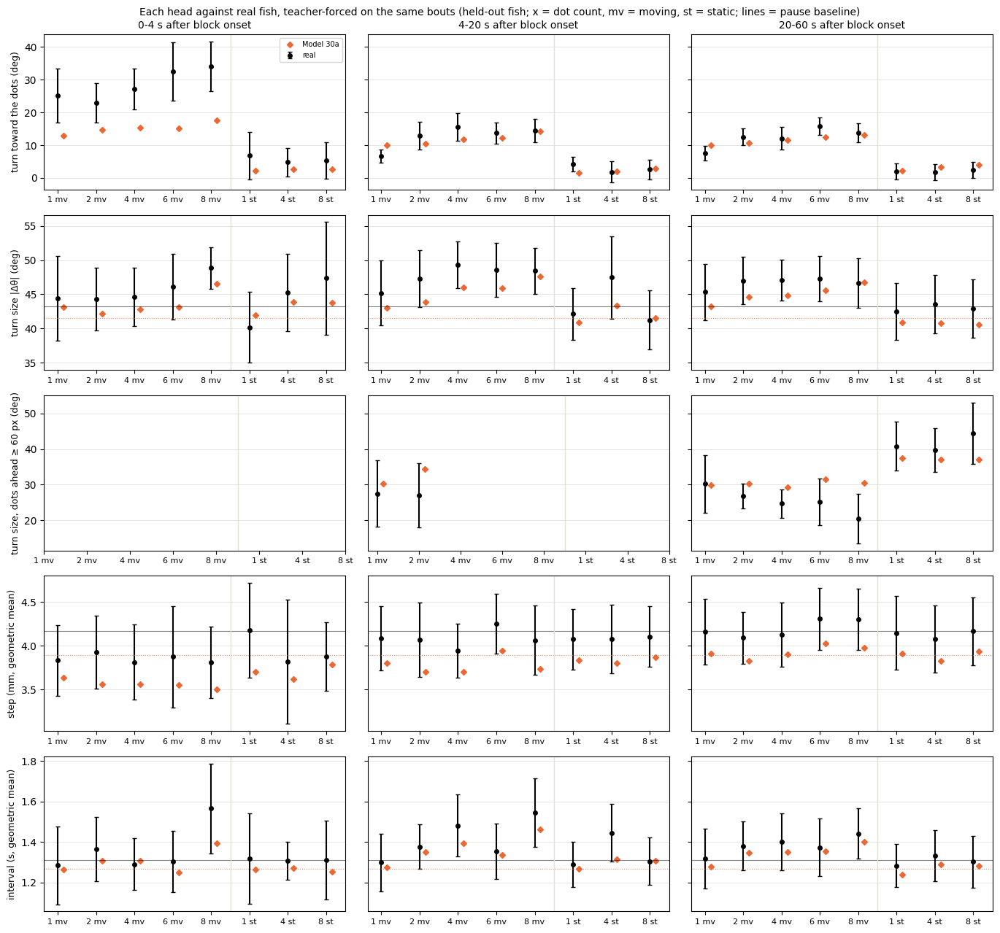

In [18]:
unit_eval.show('30a')

### M5, seed 0


== held-out likelihood per head (bits per bout)
turn             7.649
displacement     4.493
interval         1.196
joint           13.338

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_w3ft.csv / c2st_model1_rej_S4i_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_w3ft.csv  (15 rows) in 2081s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_w3ft_rej
abs_dtheta_w1                        8.5662
symbol_js                            0.0113
dt_w1                                0.4009
dist_w1                              3.8659
trans_js                  

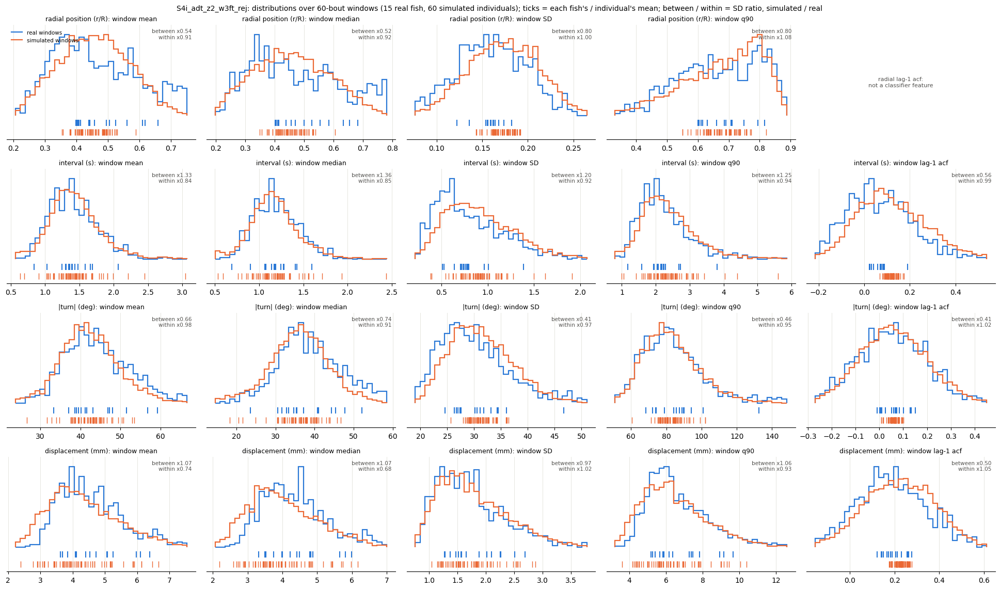


== distance to the dots across the block
  S4i_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 10.2% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    2.11     1.46  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  20.5 +/- 1.0
d2s3.5    2.20     1.83  2.64  1.39  11.0  19.0                  17.4 +/- 0.9  18.9 +/- 0.6
d4s3.5    1.38     0.80  4.68  3.37  19.0  15.0                  18.7 +/- 1.7  17.6 +/- 1.0
d6s3.5    1.69     1.18  4.62  3.03  13.0  19.0                  16.7 +/- 1.3  18.3 +/- 0.9
d8s3.5    1.45     1.21  4.97  2.79  11.0   9.0                  16.3 +/- 1.0  15.8 +/- 0.9
d1s0      2.65     1.61  

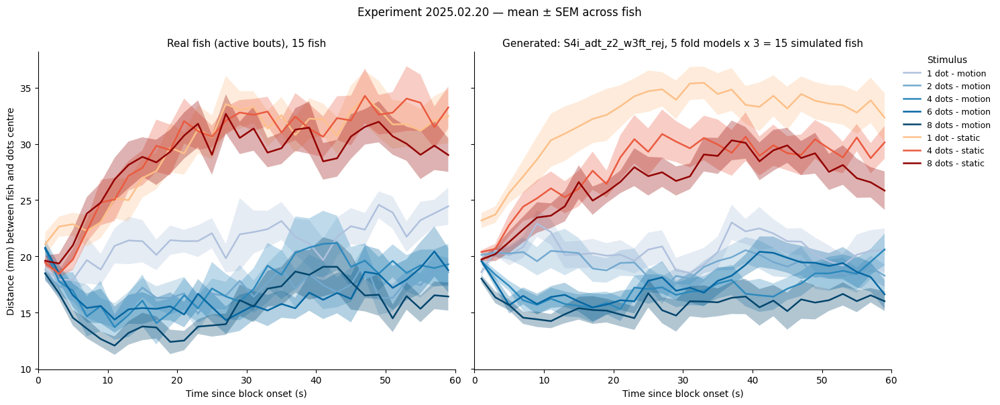


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

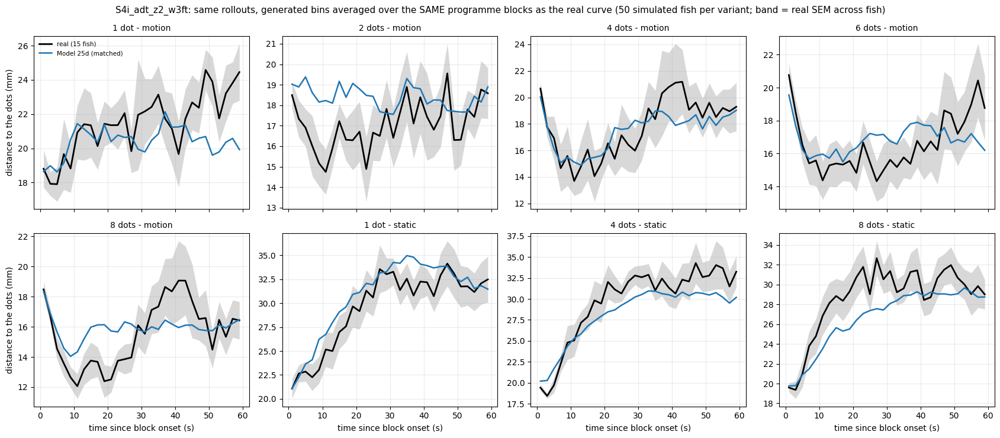


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           21.22  22.41       1.19
d2s3.5       17.39  23.58       6.19           18.97  22.33       3.36
d4s3.5       18.74  23.93       5.19           18.40  22.67       4.27
d6s3.5       16.69  23.12       6.43           17.94  22.35       4.41
d8s3.5       16.41  23.36       6.94           17.00  22.60       5.60

== turn toward the moving dots by dot count
           real  S4i_adt_z2_w3ft
win    N                        
0-20 s 1   9.09            10.34
       2  13.90            12.48
       4  15.73       

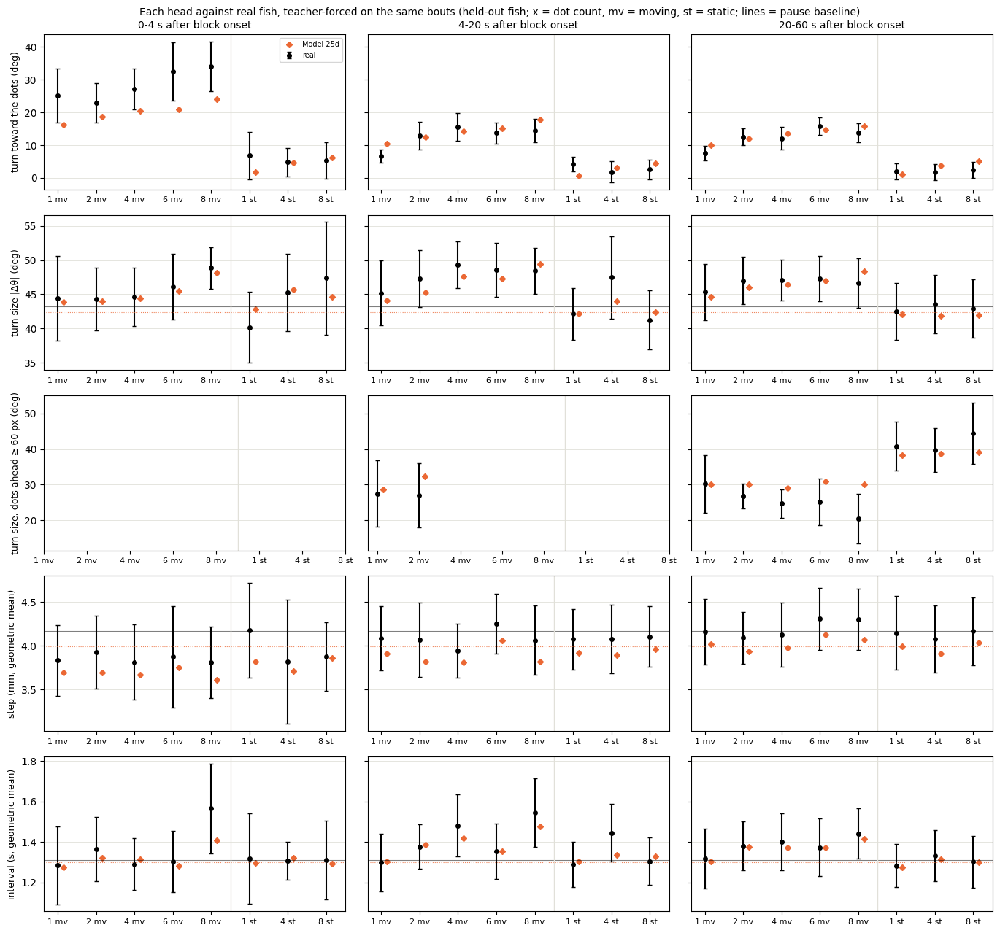

In [19]:
unit_eval.show('25d')

### M5, seed 101


== held-out likelihood per head (bits per bout)
turn             7.675
displacement     4.496
interval         1.219
joint           13.390

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_w3ft.csv / c2st_model1_rej_S4i_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_w3ft.csv  (15 rows) in 600s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_w3ft_rej
abs_dtheta_w1                        9.2541
symbol_js                            0.0161
dt_w1                                0.3684
dist_w1                              4.3677
trans_js                   

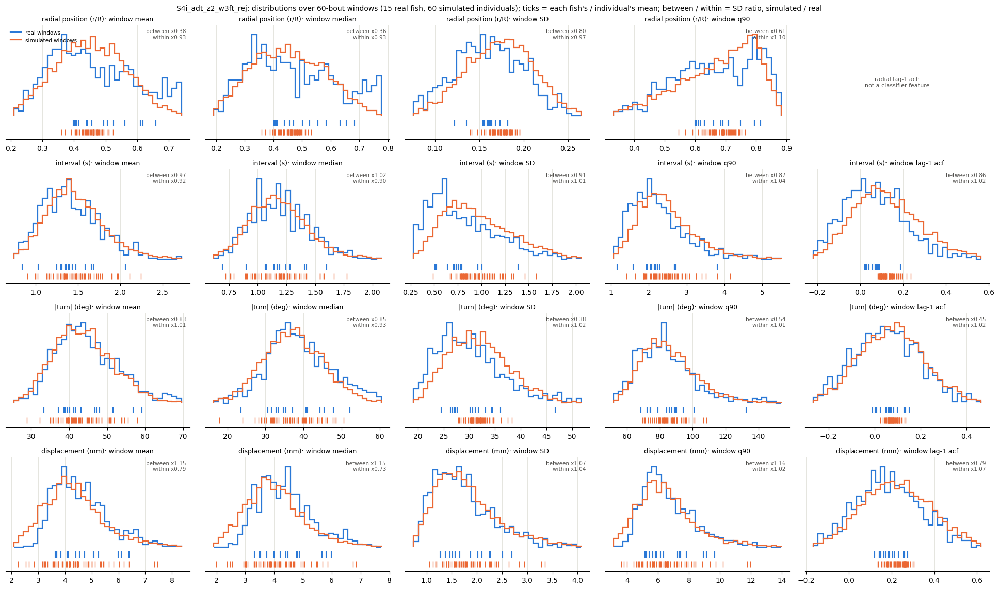


== distance to the dots across the block
  S4i_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.91     1.34  0.15  0.11   3.0   3.0                  22.3 +/- 0.9  21.2 +/- 0.8
d2s3.5    2.08     1.62  2.64  1.95  11.0  11.0                  17.4 +/- 0.9  19.5 +/- 1.1
d4s3.5    1.32     0.82  4.68  2.98  19.0  11.0                  18.7 +/- 1.7  17.8 +/- 0.9
d6s3.5    1.45     1.05  4.62  3.62  13.0  11.0                  16.7 +/- 1.3  18.2 +/- 1.0
d8s3.5    1.45     1.30  4.97  3.62  11.0  13.0                  16.3 +/- 1.0  17.0 +/- 1.0
d1s0      2.59     1.62  

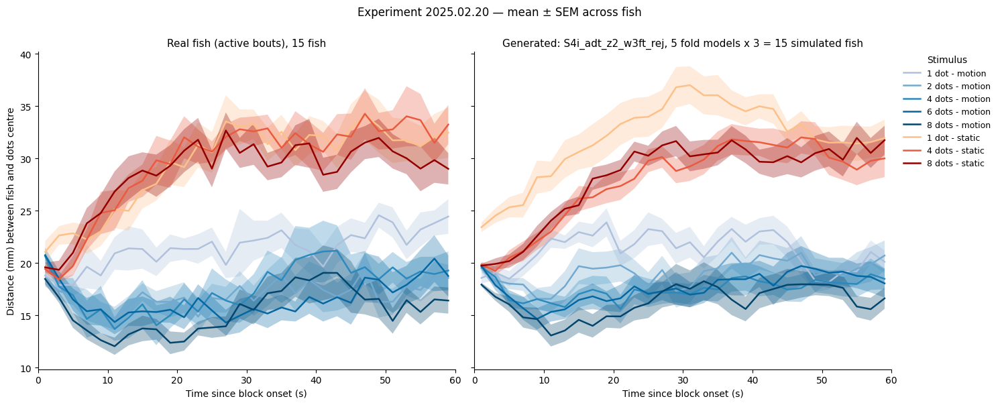


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

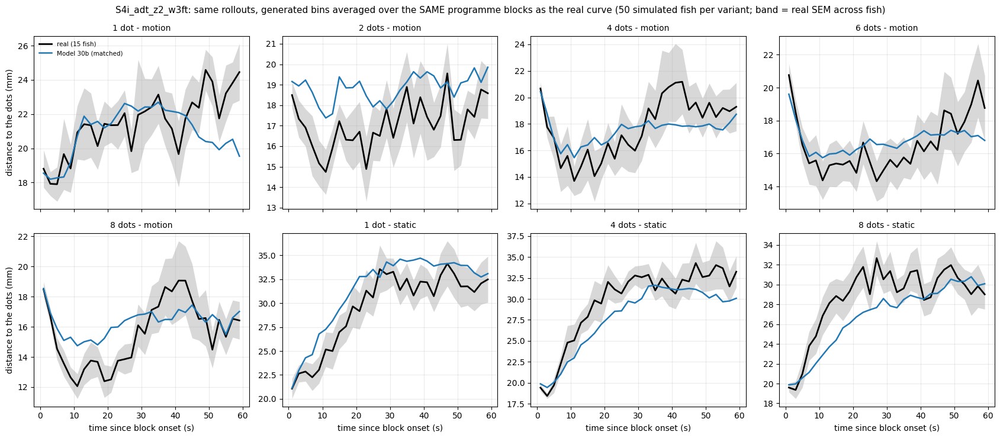


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           21.83  22.52       0.68
d2s3.5       17.39  23.58       6.19           19.71  22.38       2.67
d4s3.5       18.74  23.93       5.19           17.89  22.42       4.53
d6s3.5       16.69  23.12       6.43           17.37  22.10       4.74
d8s3.5       16.41  23.36       6.94           16.28  22.12       5.84

== turn toward the moving dots by dot count
           real  S4i_adt_z2_w3ft
win    N                        
0-20 s 1   9.09             9.01
       2  13.90            11.22
       4  15.73       

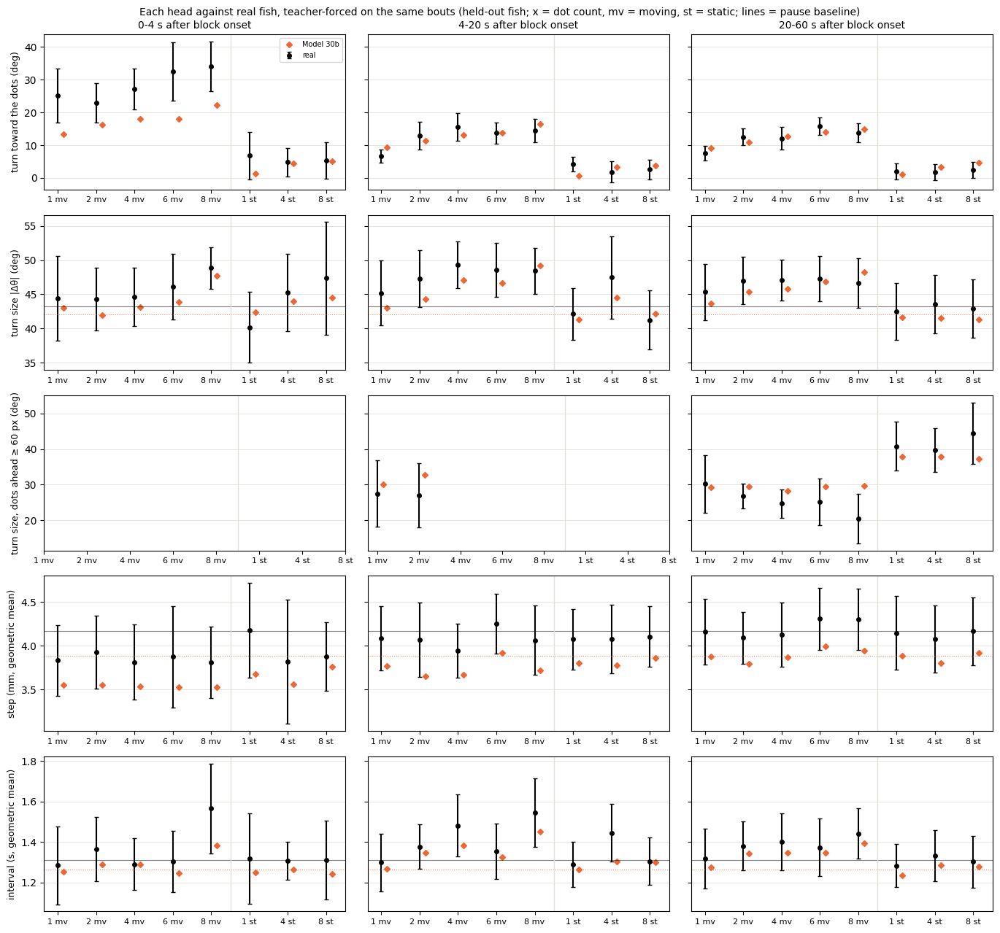

In [20]:
unit_eval.show('30b')

### M5+R, seed 0


== held-out likelihood per head (bits per bout)
turn             7.653
displacement     4.488
interval         1.218
joint           13.360

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_w3ft.csv / c2st_model1_rej_S4x_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_w3ft.csv  (15 rows) in 602s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_w3ft_rej
abs_dtheta_w1                        8.2307
symbol_js                            0.0113
dt_w1                                0.4132
dist_w1                              3.6892
trans_js                   

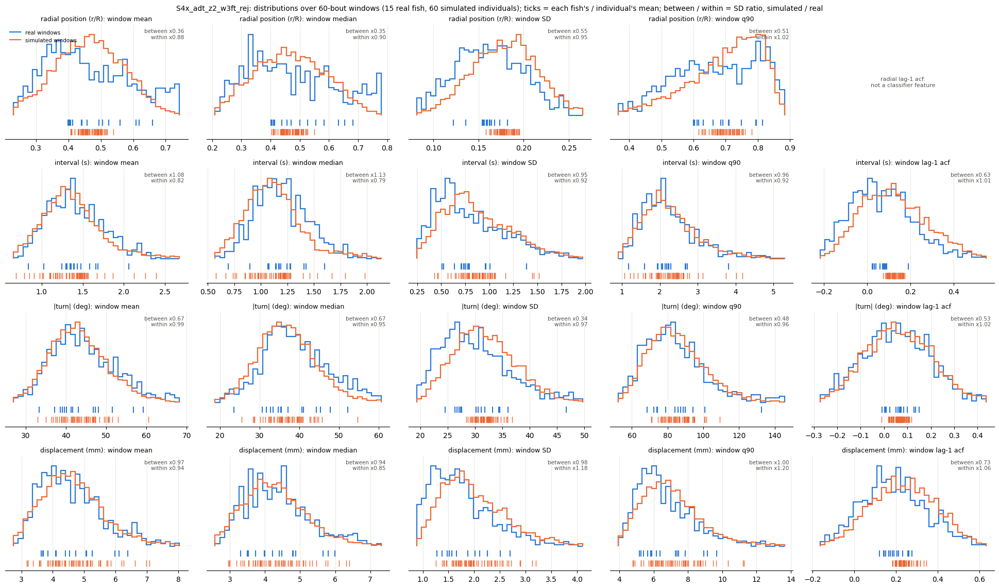


== distance to the dots across the block
  S4x_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.39     0.90  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  22.7 +/- 0.7
d2s3.5    2.94     2.26  2.64  1.18  11.0   9.0                  17.4 +/- 0.9  20.8 +/- 0.5
d4s3.5    2.08     1.30  4.68  2.47  19.0   7.0                  18.7 +/- 1.7  19.1 +/- 0.8
d6s3.5    2.27     1.72  4.62  2.16  13.0   7.0                  16.7 +/- 1.3  19.0 +/- 0.8
d8s3.5    2.53     2.50  4.97  1.39  11.0   5.0                  16.3 +/- 1.0  17.7 +/- 0.6
d1s0      3.83     2.28  

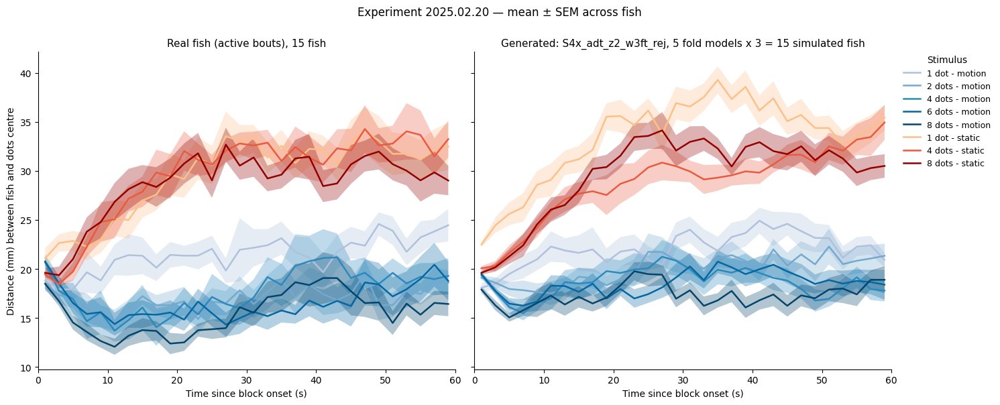


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

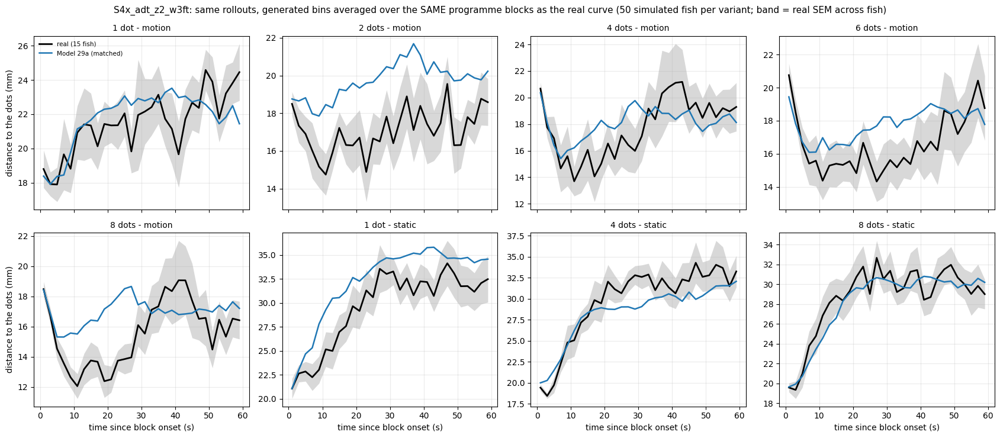


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           22.72  23.06       0.34
d2s3.5       17.39  23.58       6.19           19.63  22.82       3.19
d4s3.5       18.74  23.93       5.19           19.02  23.00       3.98
d6s3.5       16.69  23.12       6.43           18.38  23.03       4.65
d8s3.5       16.41  23.36       6.94           17.33  22.86       5.53

== turn toward the moving dots by dot count
           real  S4x_adt_z2_w3ft
win    N                        
0-20 s 1   9.09            10.24
       2  13.90            12.22
       4  15.73       

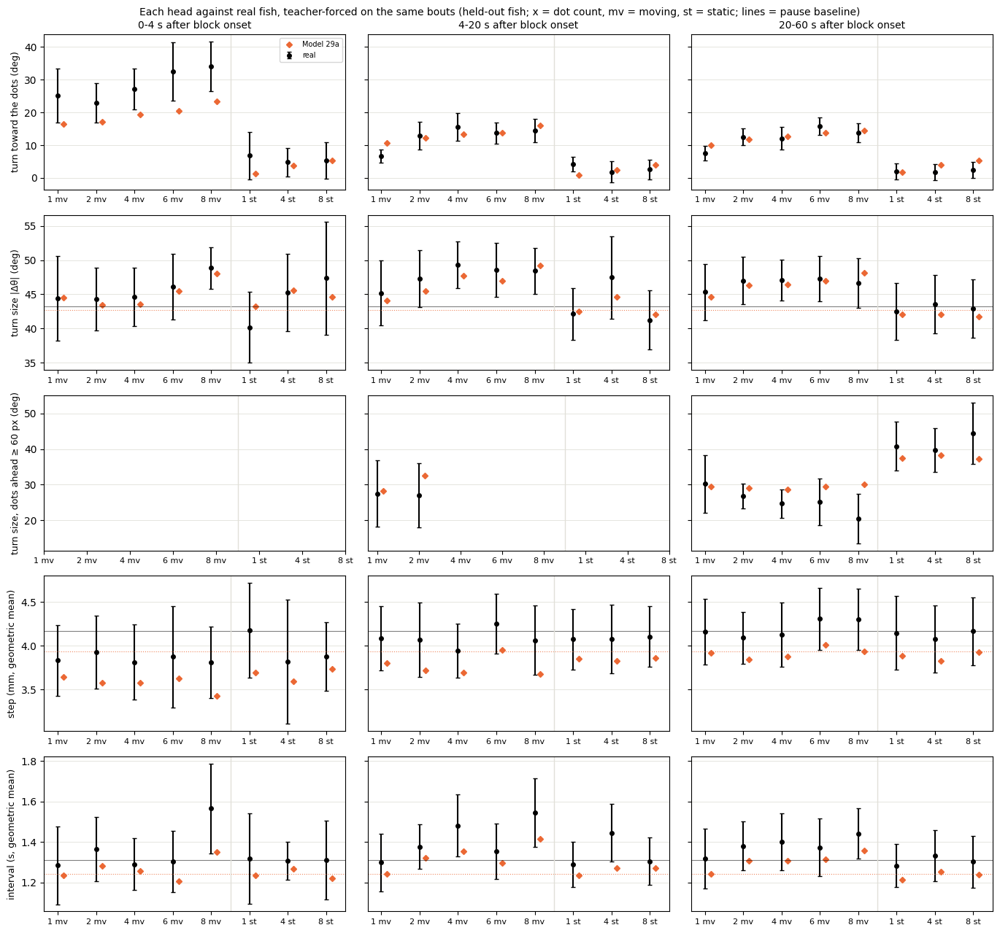

In [21]:
unit_eval.show('29a')

### M5+R, seed 101


== held-out likelihood per head (bits per bout)
turn             7.657
displacement     4.542
interval         1.214
joint           13.413

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_w3ft.csv / c2st_model1_rej_S4x_adt_z2_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_w3ft.csv  (15 rows) in 621s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_w3ft_rej
abs_dtheta_w1                        8.7299
symbol_js                            0.0128
dt_w1                                0.3872
dist_w1                              5.6549
trans_js                   

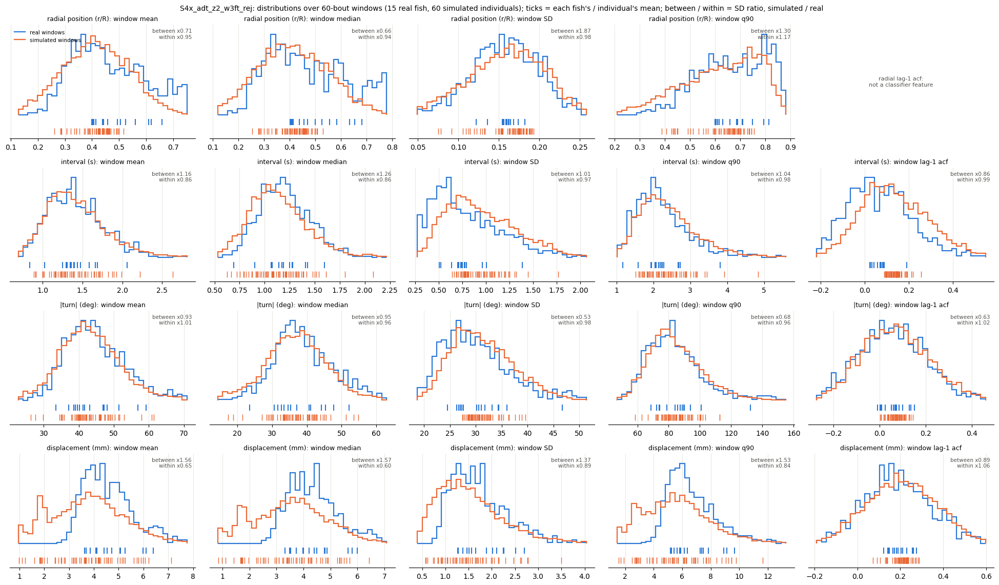


== distance to the dots across the block
  S4x_adt_z2_w3ft_fold4.pt: 3 rollouts
dropped 11.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.34     0.93  0.15  0.37   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 0.9
d2s3.5    1.72     1.41  2.64  1.64  11.0  11.0                  17.4 +/- 0.9  18.7 +/- 0.8
d4s3.5    1.51     0.84  4.68  3.84  19.0   9.0                  18.7 +/- 1.7  16.8 +/- 0.8
d6s3.5    1.06     0.77  4.62  3.77  13.0   9.0                  16.7 +/- 1.3  17.1 +/- 0.8
d8s3.5    1.53     1.50  4.97  2.28  11.0  17.0                  16.3 +/- 1.0  16.8 +/- 0.7
d1s0      3.25     1.91  

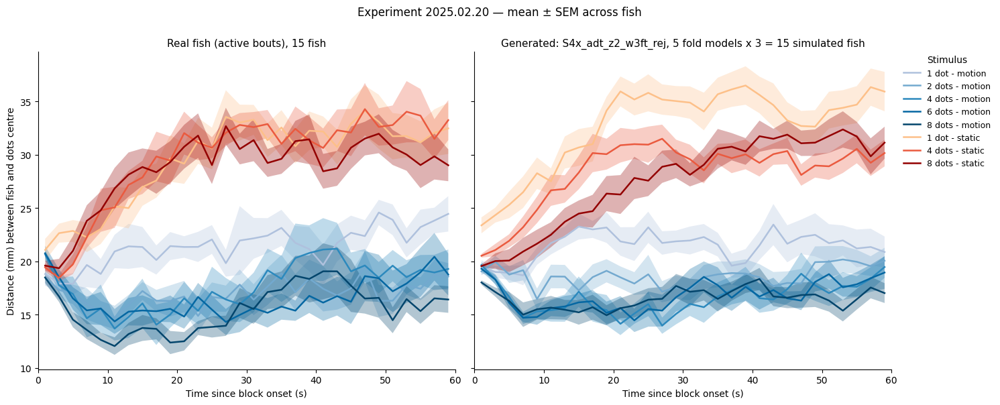


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

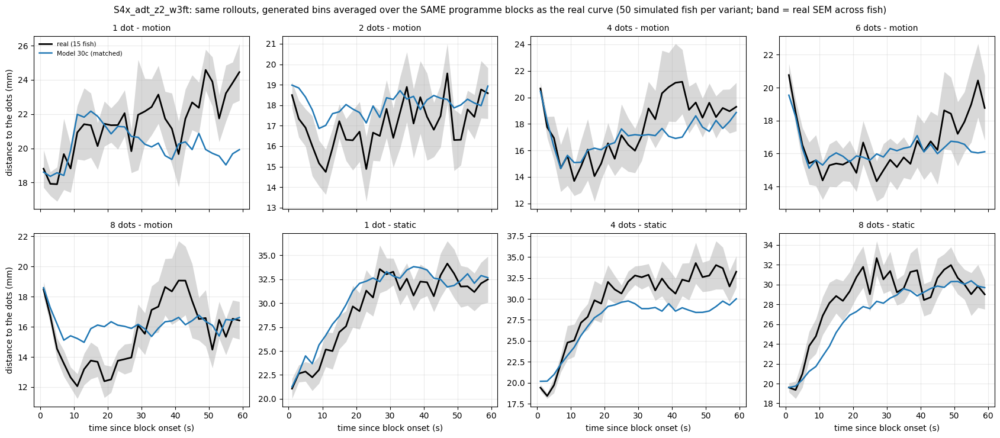


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_w3ft                  
           plateau   null attraction         plateau   null attraction
cond_label                                                            
d1s3.5       22.41  23.57       1.16           20.76  21.76       1.00
d2s3.5       17.39  23.58       6.19           18.35  21.14       2.79
d4s3.5       18.74  23.93       5.19           17.04  21.33       4.30
d6s3.5       16.69  23.12       6.43           16.47  21.22       4.76
d8s3.5       16.41  23.36       6.94           16.12  21.28       5.16

== turn toward the moving dots by dot count
           real  S4x_adt_z2_w3ft
win    N                        
0-20 s 1   9.09             9.59
       2  13.90            11.83
       4  15.73       

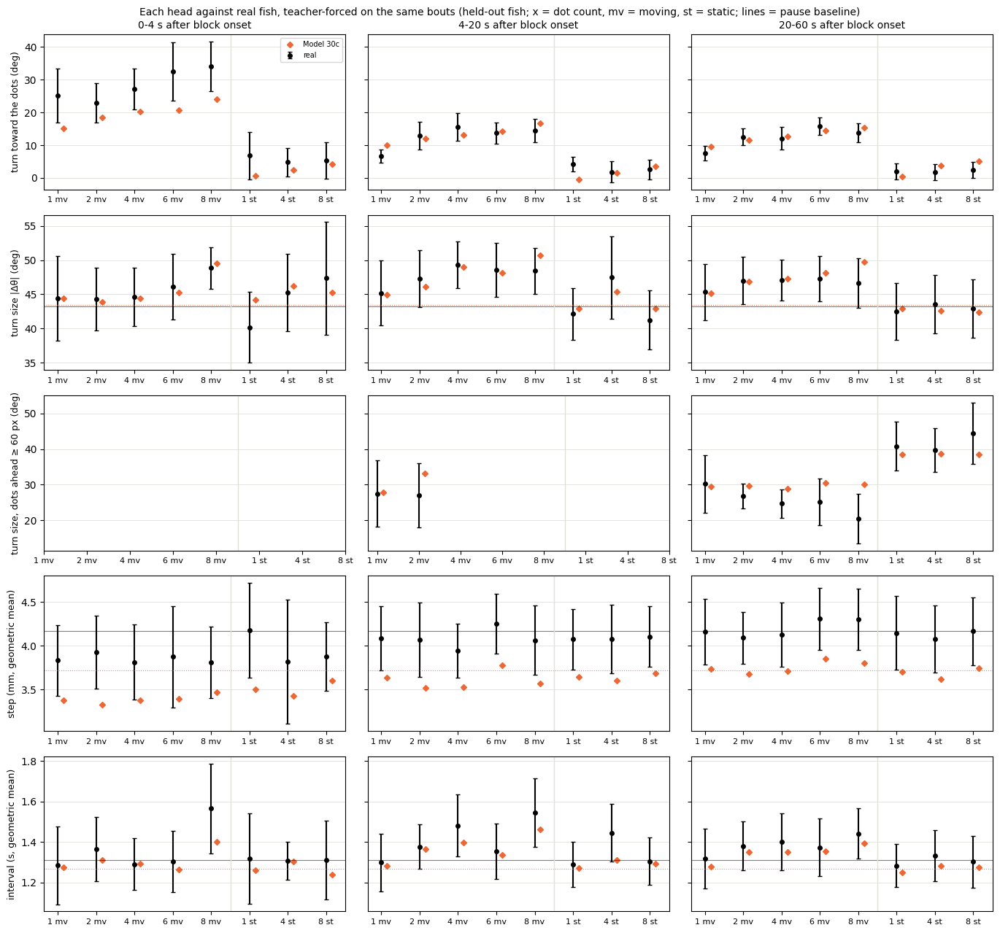

In [22]:
unit_eval.show('30c')

### M5+T, seed 0


== held-out likelihood per head (bits per bout)
turn             7.661
displacement     4.500
interval         1.231
joint           13.391

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 677s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     7.3962
symbol_js                                         0.0095
dt_w1                   

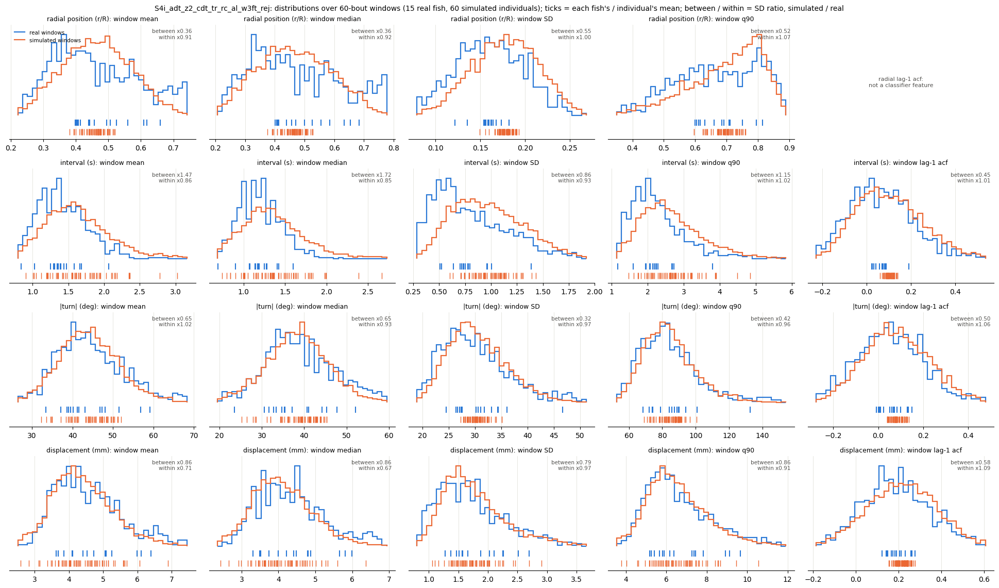


== distance to the dots across the block
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 10.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.40     0.95  0.15  0.68   3.0   5.0                  22.3 +/- 0.9  21.2 +/- 1.0
d2s3.5    1.85     1.48  2.64  2.55  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 0.9
d4s3.5    1.05     0.61  4.68  5.68  19.0  15.0                  18.7 +/- 1.7  18.3 +/- 0.8
d6s3.5    1.31     0.88  4.62  3.04  13.0   7.0                  16.7 +/- 1.3  16.4 +/- 0.7
d8s3.5    1.69     1.46  4.97  3.48  11.0   9.0                  16.3 +/- 1.0  16.2 +/- 0.7
d1s0      2.

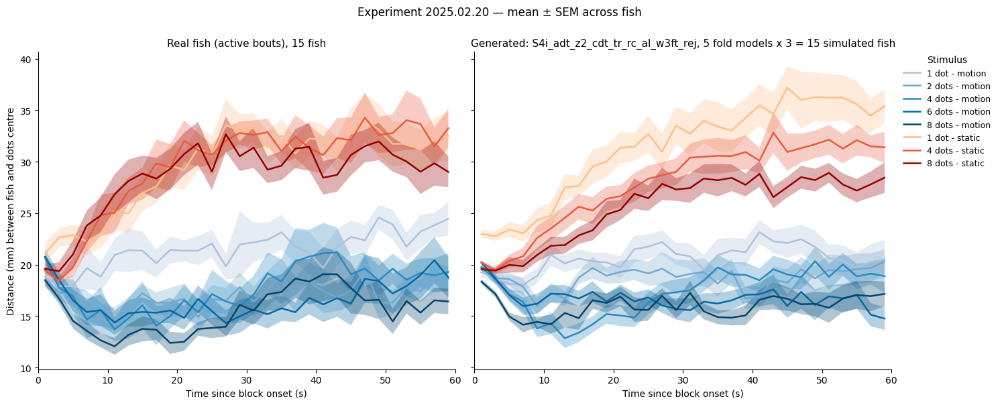


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

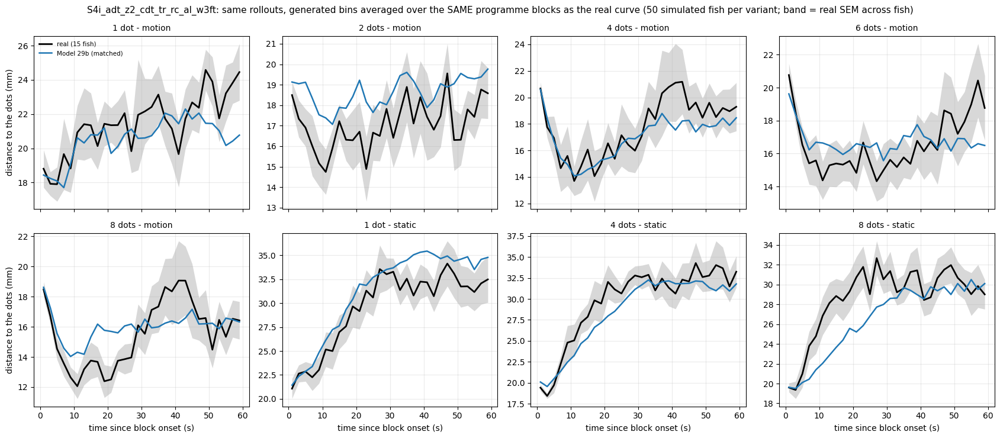


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.36  22.59       1.23
d2s3.5       17.39  23.58       6.19                        18.75  22.61       3.86
d4s3.5       18.74  23.93       5.19                        17.91  22.29       4.38
d6s3.5       16.69  23.12       6.43                        16.69  22.59       5.90
d8s3.5       16.41  23.36       6.94                        16.55  22.25       5.70

== turn toward the moving dots by dot count
           real  S4i_adt_z2_cdt_tr_rc_al_w3ft
win 

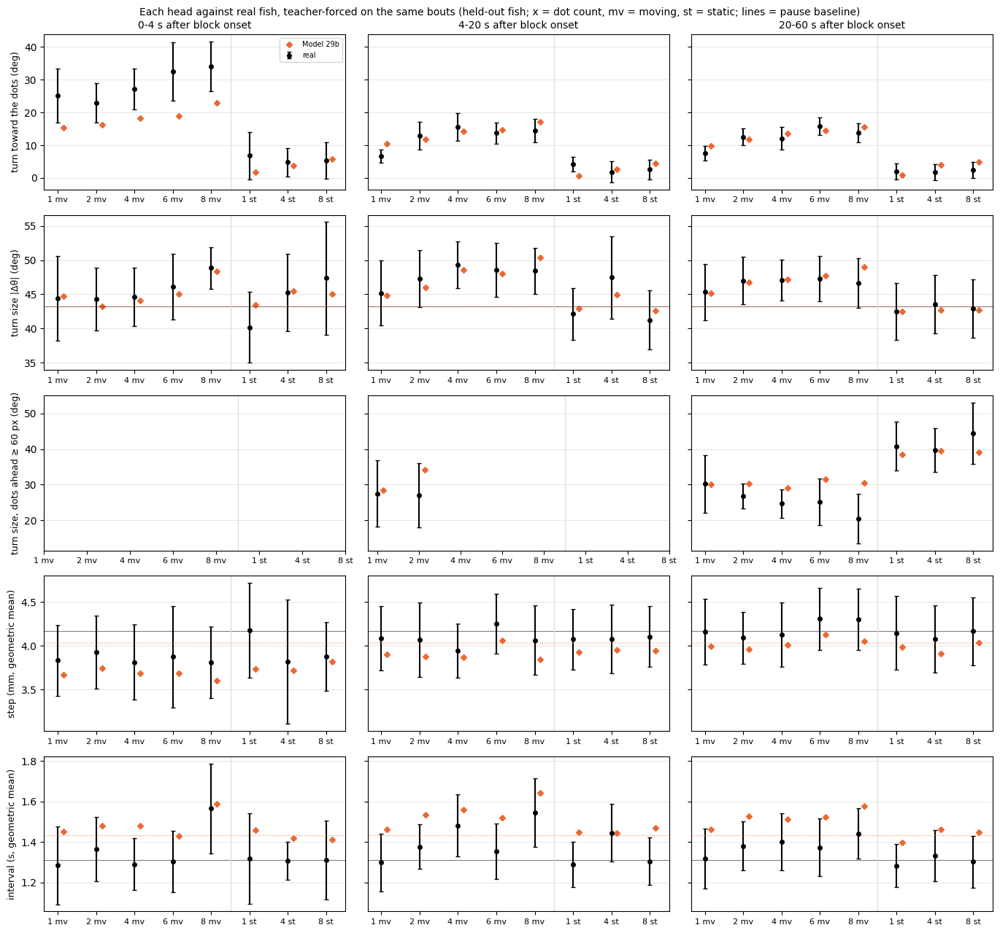

In [23]:
unit_eval.show('29b')

### M5+T, seed 101


== held-out likelihood per head (bits per bout)
turn             7.656
displacement     4.507
interval         1.229
joint           13.391

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4i_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4i_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 896s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4i_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     7.6061
symbol_js                                         0.0104
dt_w1                   

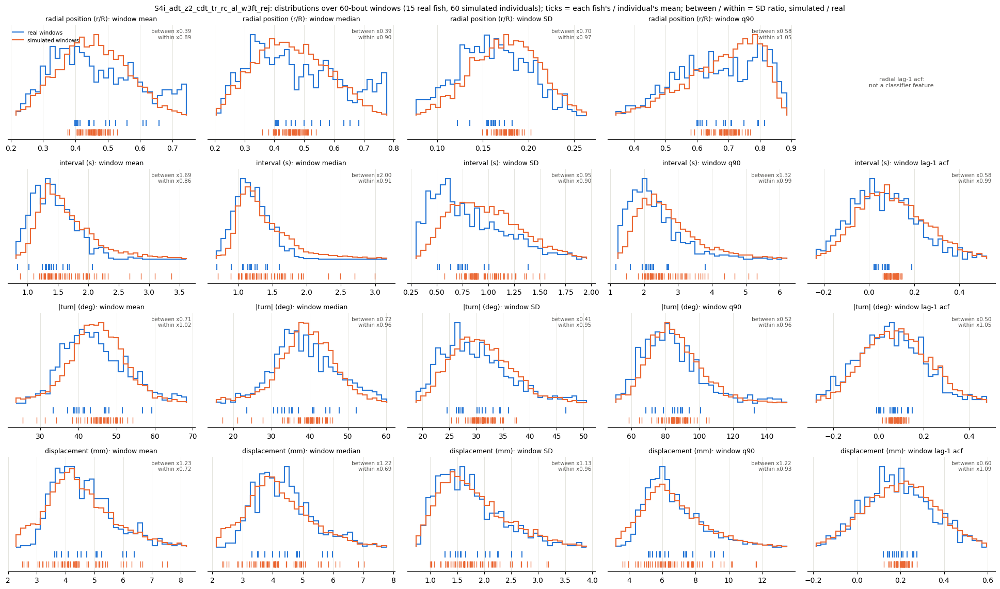


== distance to the dots across the block
  S4i_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 11.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.57     1.08  0.15  0.65   3.0   7.0                  22.3 +/- 0.9  23.6 +/- 0.8
d2s3.5    2.61     2.00  2.64  2.56  11.0   9.0                  17.4 +/- 0.9  20.3 +/- 0.8
d4s3.5    1.10     0.68  4.68   3.9  19.0  13.0                  18.7 +/- 1.7  18.1 +/- 0.7
d6s3.5    1.41     1.04  4.62  3.42  13.0   9.0                  16.7 +/- 1.3  17.8 +/- 0.9
d8s3.5    1.69     1.41  4.97  3.95  11.0  11.0                  16.3 +/- 1.0  16.3 +/- 0.8
d1s0      3.

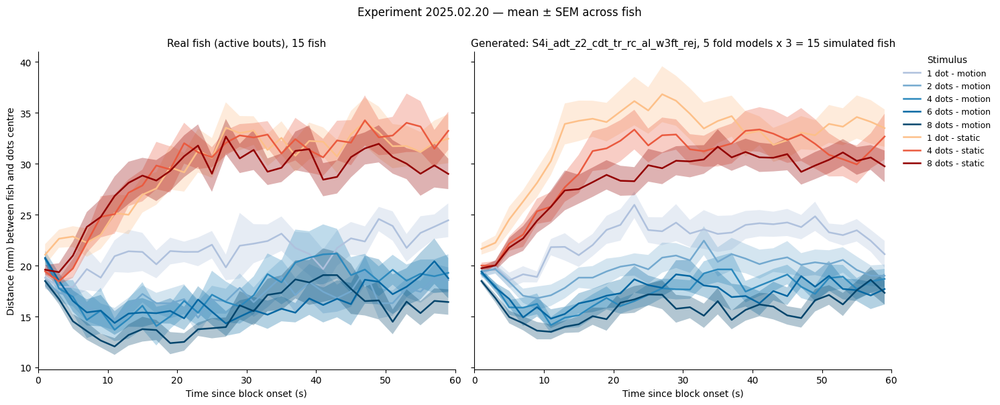


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

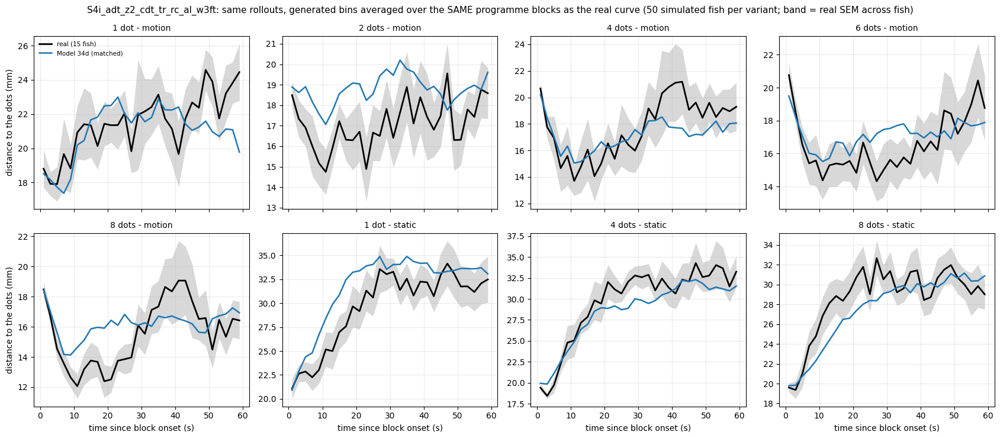


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4i_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        22.53  22.80       0.27
d2s3.5       17.39  23.58       6.19                        18.85  22.69       3.84
d4s3.5       18.74  23.93       5.19                        17.82  22.62       4.80
d6s3.5       16.69  23.12       6.43                        17.43  22.54       5.11
d8s3.5       16.41  23.36       6.94                        15.91  22.61       6.70

== turn toward the moving dots by dot count
           real  S4i_adt_z2_cdt_tr_rc_al_w3ft
win 

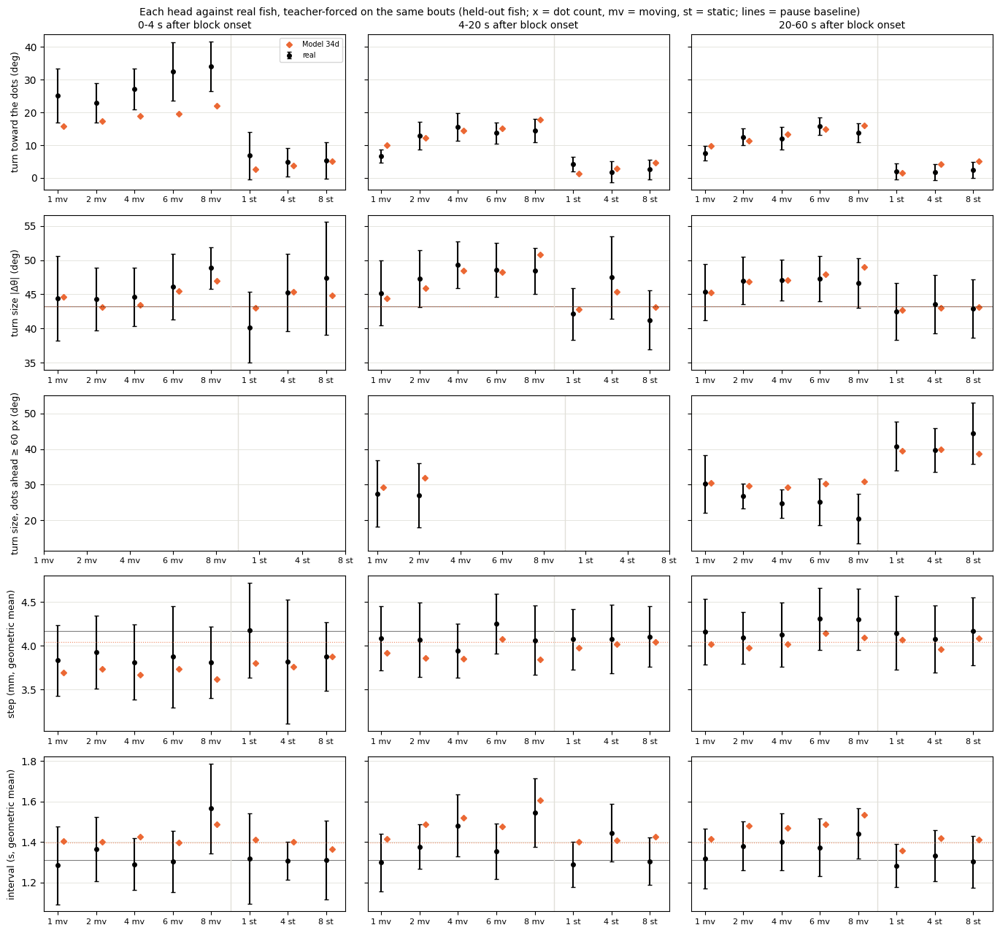

In [24]:
unit_eval.show('34d')

### M6, seed 0


== held-out likelihood per head (bits per bout)
turn             7.665
displacement     4.505
interval         1.215
joint           13.385

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 772s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     8.5212
symbol_js                                         0.0117
dt_w1                   

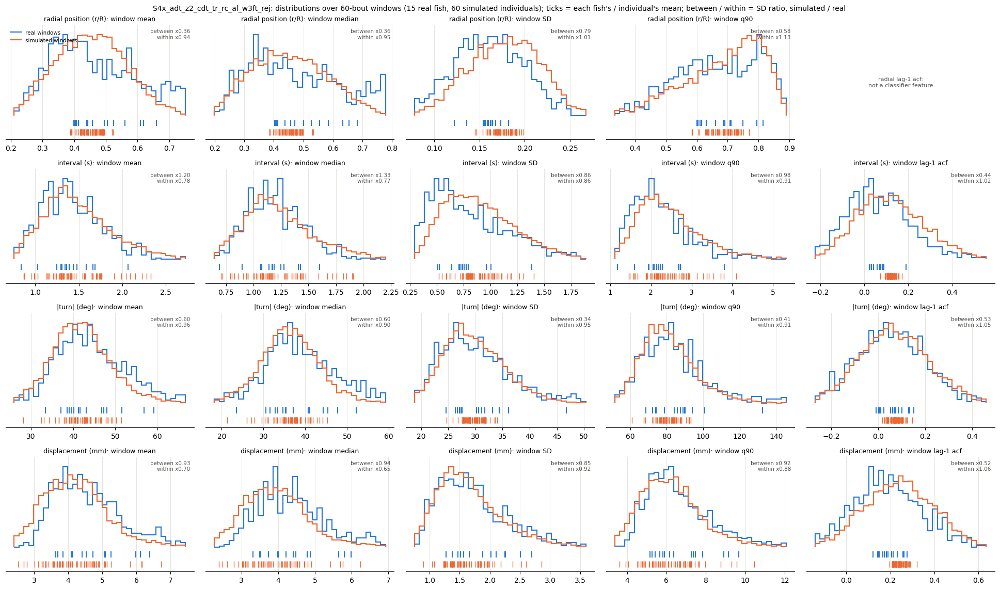


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 11.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.60     1.04  0.15  0.97   3.0   7.0                  22.3 +/- 0.9  22.2 +/- 0.7
d2s3.5    1.55     1.20  2.64  3.15  11.0  11.0                  17.4 +/- 0.9  19.0 +/- 0.6
d4s3.5    1.10     0.66  4.68  3.92  19.0  15.0                  18.7 +/- 1.7  17.9 +/- 0.7
d6s3.5    1.63     1.15  4.62  5.17  13.0  11.0                  16.7 +/- 1.3  17.8 +/- 0.8
d8s3.5    1.30     1.24  4.97  3.52  11.0   7.0                  16.3 +/- 1.0  17.1 +/- 0.9
d1s0      1.

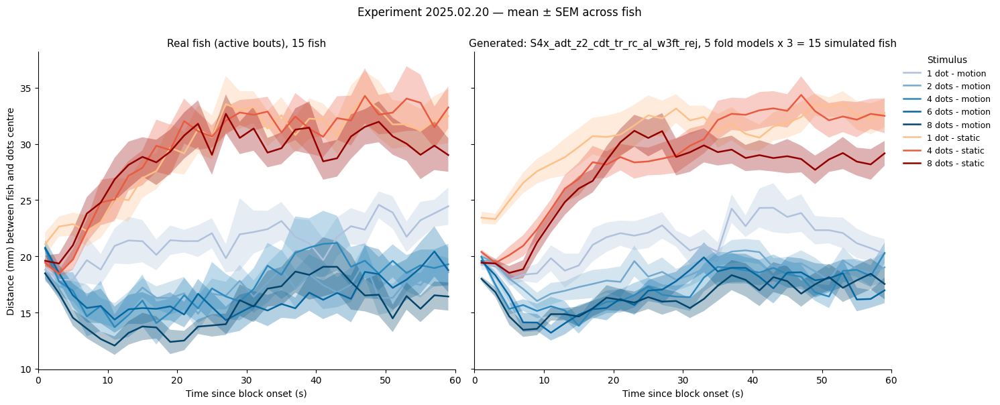


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

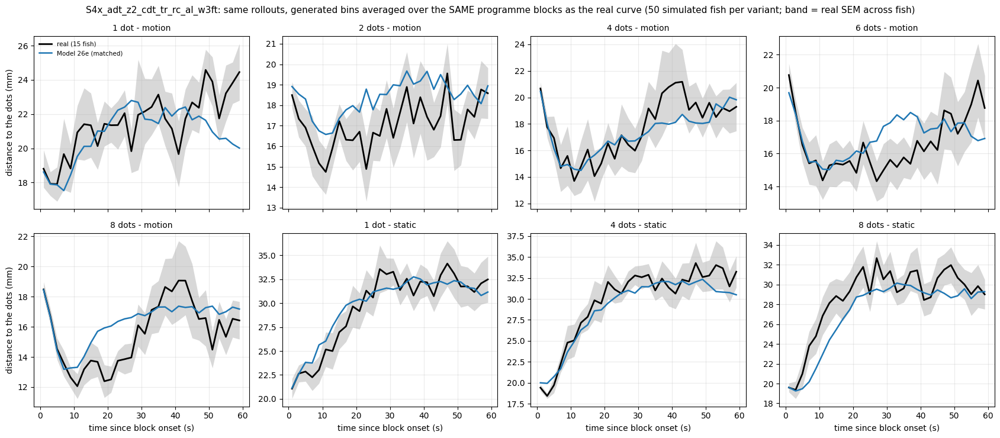


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.49  22.79       1.30
d2s3.5       17.39  23.58       6.19                        18.99  22.36       3.37
d4s3.5       18.74  23.93       5.19                        17.58  22.28       4.70
d6s3.5       16.69  23.12       6.43                        17.40  22.29       4.89
d8s3.5       16.41  23.36       6.94                        16.79  22.23       5.43

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_rc_al_w3ft
win 

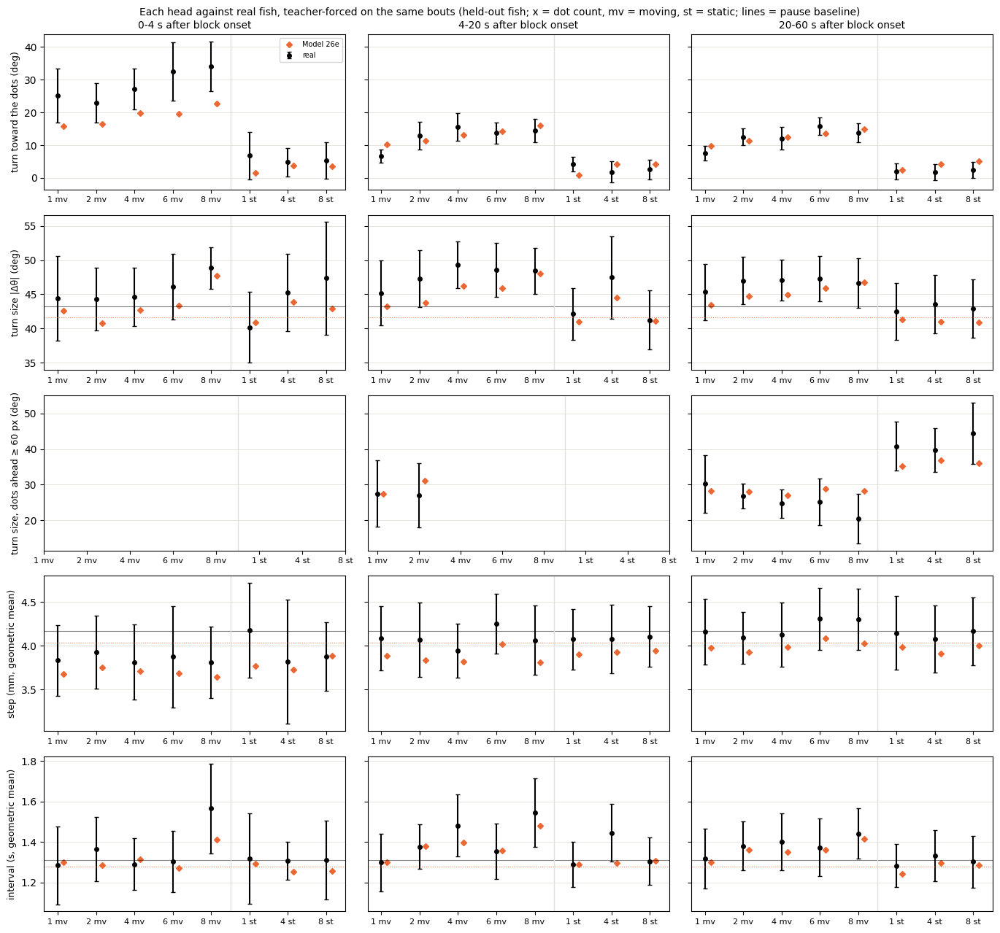

In [25]:
unit_eval.show('26e')

### M6, seed 101


== held-out likelihood per head (bits per bout)
turn             7.668
displacement     4.497
interval         1.222
joint           13.387

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft.csv  (15 rows) in 734s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_rej
abs_dtheta_w1                                     8.1119
symbol_js                                         0.0123
dt_w1                   

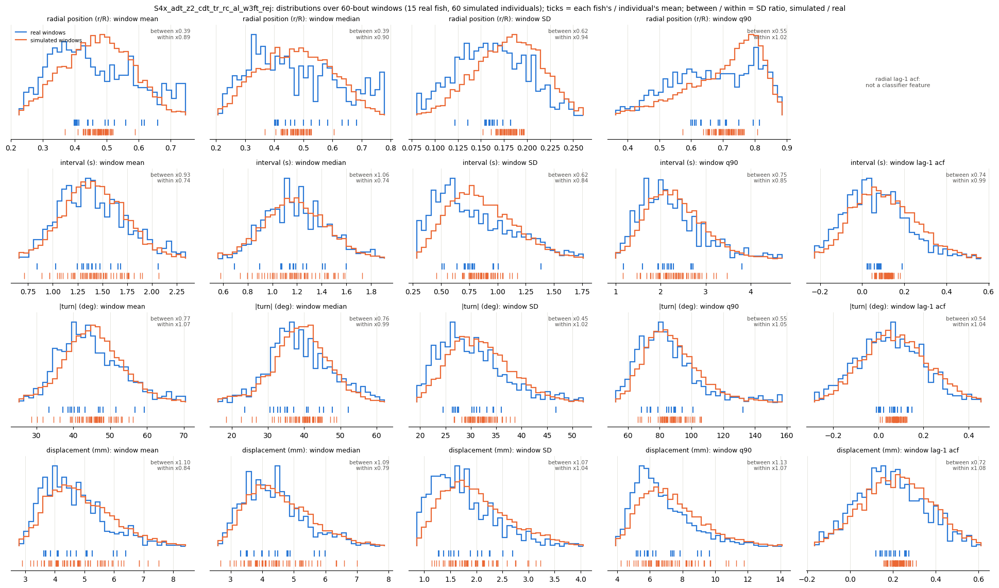


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_fold4.pt: 3 rollouts
dropped 11.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.05  0.15  0.83   3.0   5.0                  22.3 +/- 0.9  21.5 +/- 0.6
d2s3.5    1.33     1.10  2.64   3.0  11.0   9.0                  17.4 +/- 0.9  18.5 +/- 0.9
d4s3.5    1.27     0.76  4.68  3.84  19.0  13.0                  18.7 +/- 1.7  18.1 +/- 0.9
d6s3.5    1.46     0.95  4.62  3.85  13.0   9.0                  16.7 +/- 1.3  15.6 +/- 0.6
d8s3.5    1.64     1.62  4.97  2.25  11.0   9.0                  16.3 +/- 1.0  17.2 +/- 0.7
d1s0      3.

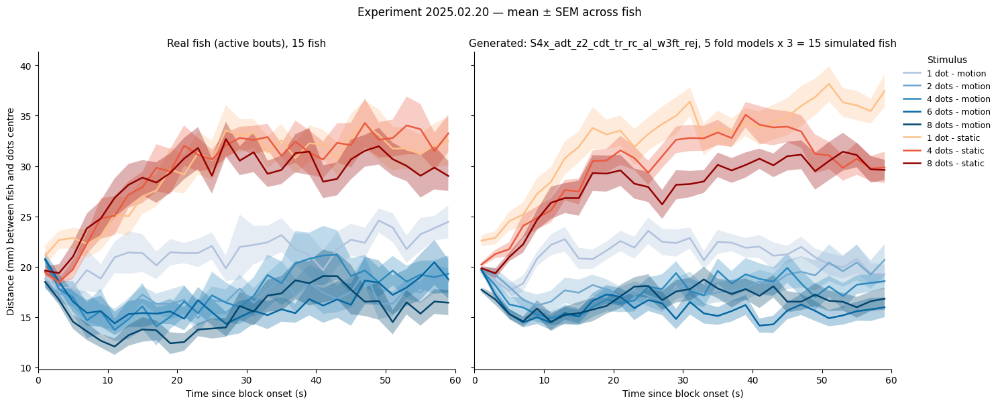


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

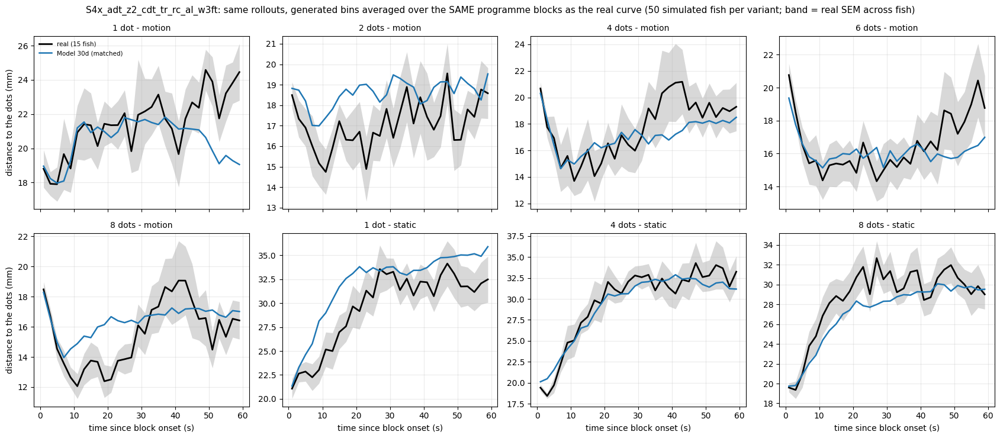


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft                  
           plateau   null attraction                      plateau   null attraction
cond_label                                                                         
d1s3.5       22.41  23.57       1.16                        21.53  22.84       1.31
d2s3.5       17.39  23.58       6.19                        18.80  22.43       3.63
d4s3.5       18.74  23.93       5.19                        17.85  22.76       4.91
d6s3.5       16.69  23.12       6.43                        16.21  22.62       6.41
d8s3.5       16.41  23.36       6.94                        17.12  22.89       5.77

== turn toward the moving dots by dot count
           real  S4x_adt_z2_cdt_tr_rc_al_w3ft
win 

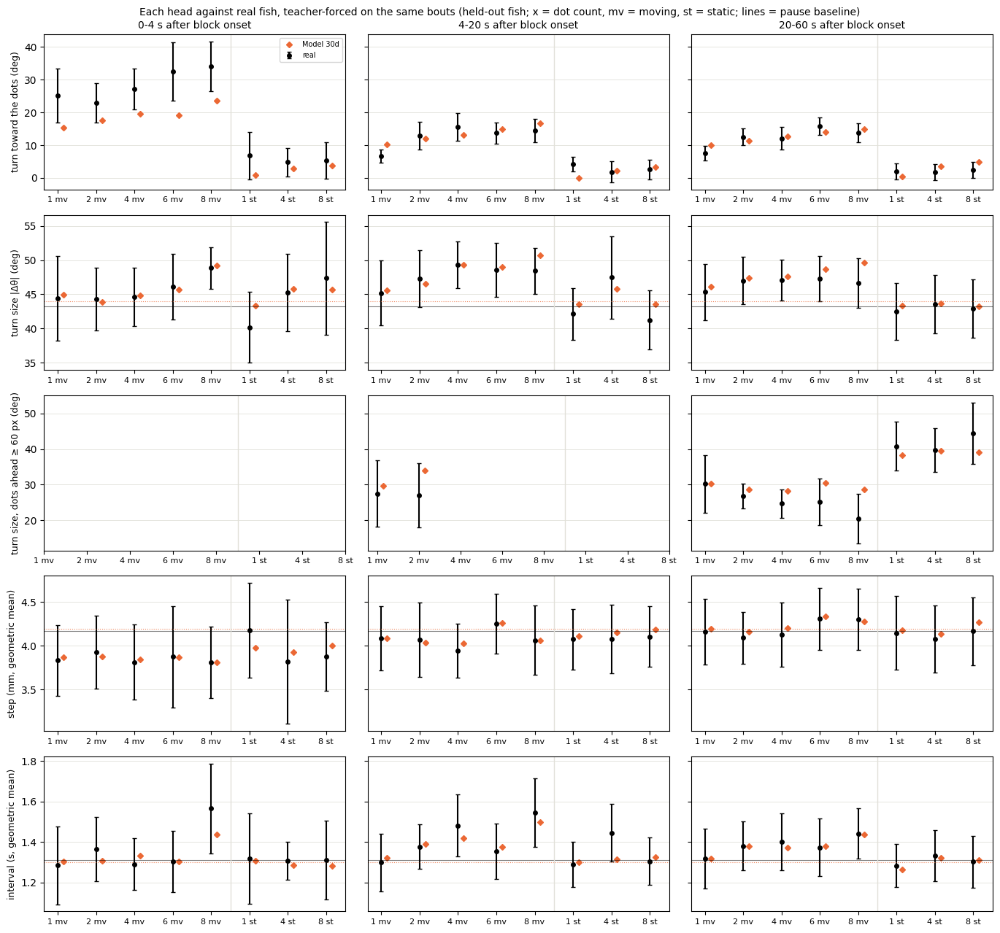

In [26]:
unit_eval.show('30d')

### D1, seed 0


== held-out likelihood per head (bits per bout)
turn             7.667
displacement     4.508
interval         1.218
joint           13.393

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 878s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                        8.6091
symbol_js                                            0.0130
dt_

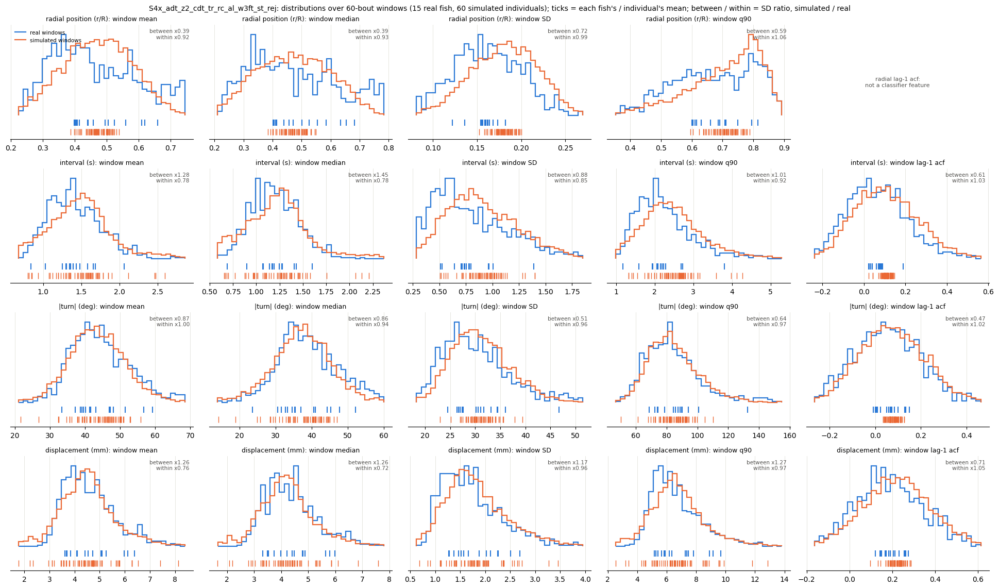


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.50     1.04  0.15  0.04   3.0   5.0                  22.3 +/- 0.9  21.8 +/- 0.8
d2s3.5    2.48     1.94  2.64   2.2  11.0  15.0                  17.4 +/- 0.9  20.0 +/- 0.7
d4s3.5    1.41     0.84  4.68  3.63  19.0   9.0                  18.7 +/- 1.7  18.7 +/- 0.6
d6s3.5    1.97     1.40  4.62  2.73  13.0   9.0                  16.7 +/- 1.3  17.8 +/- 0.8
d8s3.5    1.55     1.42  4.97  2.72  11.0   9.0                  16.3 +/- 1.0  16.2 +/- 0.6
d1s0     

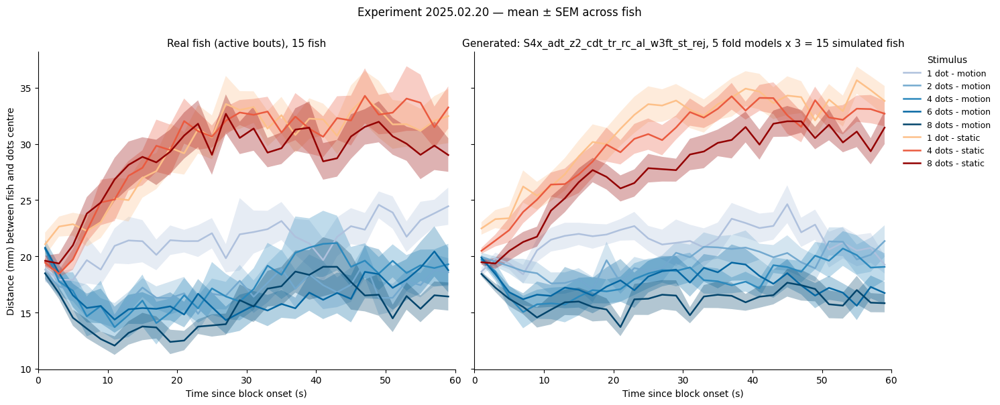


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

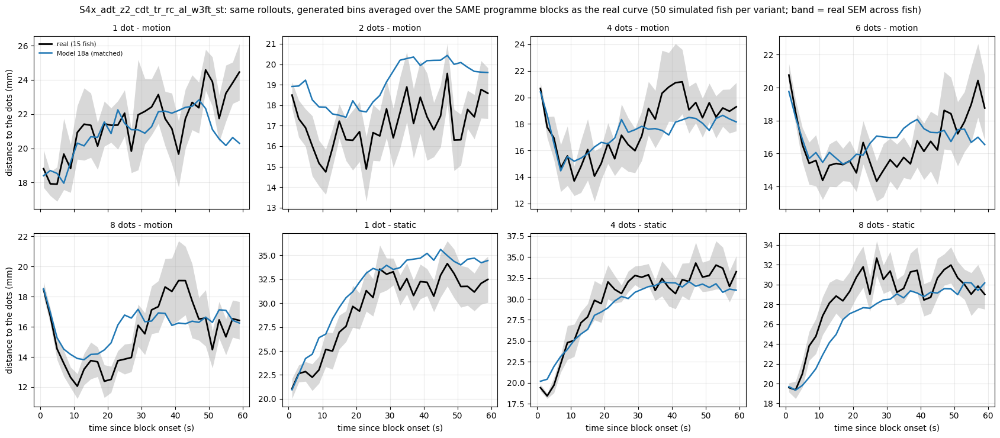


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.27  23.32       1.05
d2s3.5       17.39  23.58       6.19                           19.54  22.69       3.15
d4s3.5       18.74  23.93       5.19                           18.33  22.74       4.42
d6s3.5       16.69  23.12       6.43                           17.29  22.77       5.48
d8s3.5       16.41  23.36       6.94                           16.91  22.77       5.86

== turn toward the moving dots by dot count
           real  S4x_adt_z

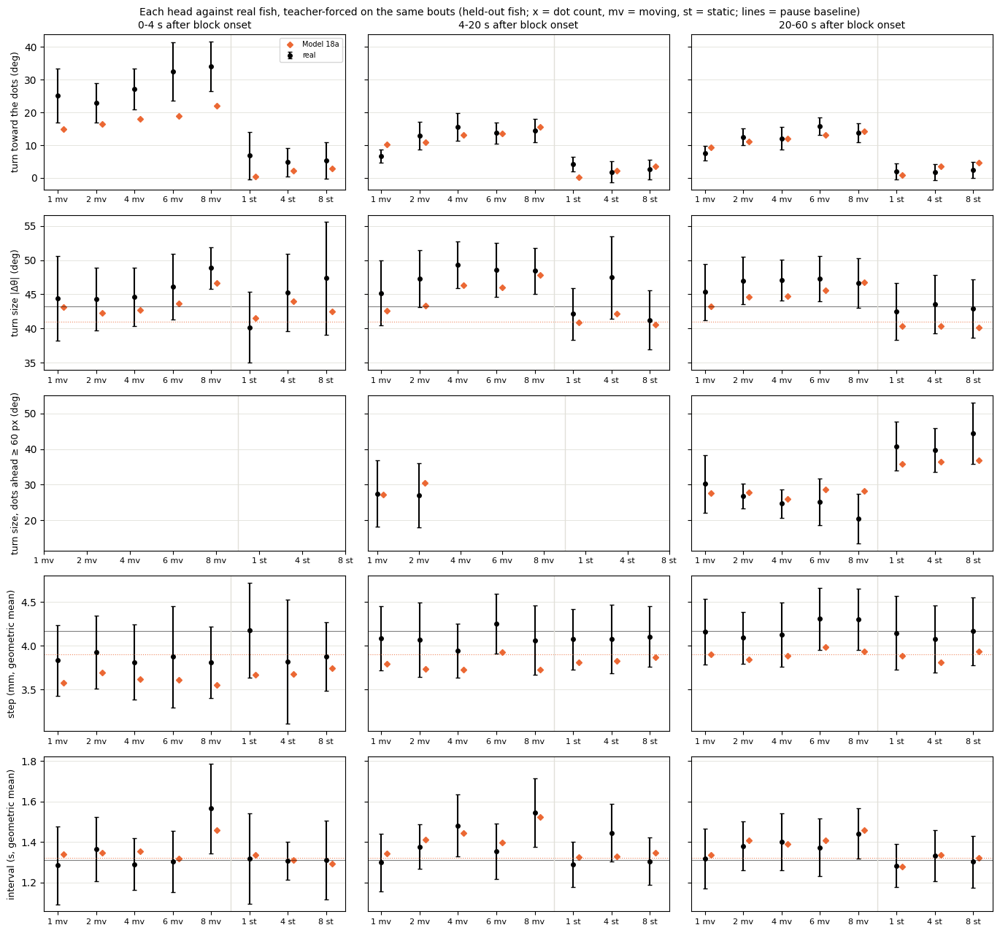

In [27]:
unit_eval.show('18a')

### D1, seed 101


== held-out likelihood per head (bits per bout)


turn             7.667
displacement     4.503
interval         1.226
joint           13.395

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 708s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                        7.7735
symbol_js                                            0.0111
dt_w1                                              

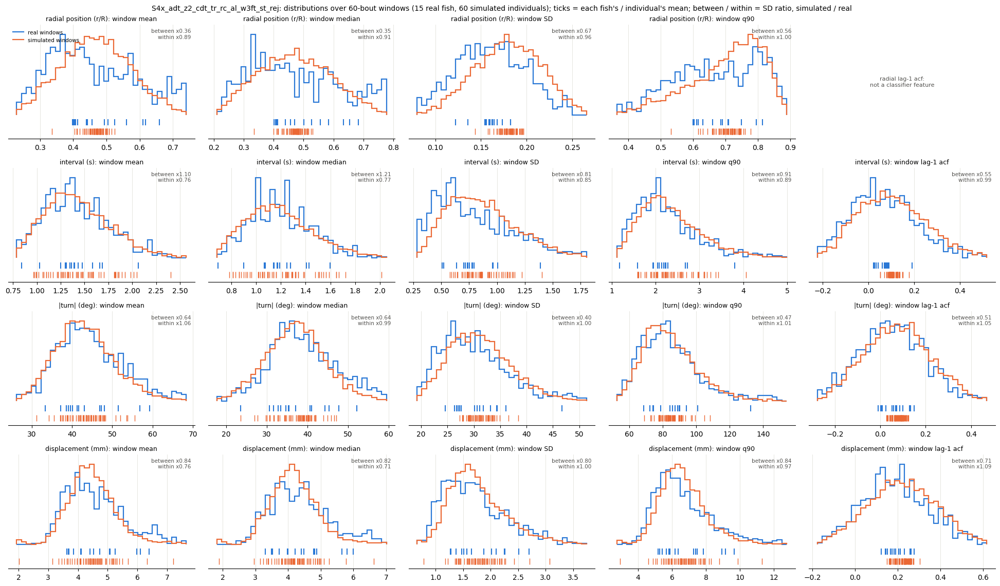


== distance to the dots across the block
  S4x_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 12.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.54     1.09  0.15  0.04   3.0   3.0                  22.3 +/- 0.9  22.7 +/- 0.8
d2s3.5    1.75     1.37  2.64  1.75  11.0   9.0                  17.4 +/- 0.9  19.1 +/- 0.9
d4s3.5    1.29     0.72  4.68  3.62  19.0   9.0                  18.7 +/- 1.7  17.4 +/- 0.7
d6s3.5    1.58     1.22  4.62  3.52  13.0   9.0                  16.7 +/- 1.3  18.4 +/- 0.9
d8s3.5    1.89     1.87  4.97  2.71  11.0   9.0                  16.3 +/- 1.0  18.0 +/- 0.9
d1s0     

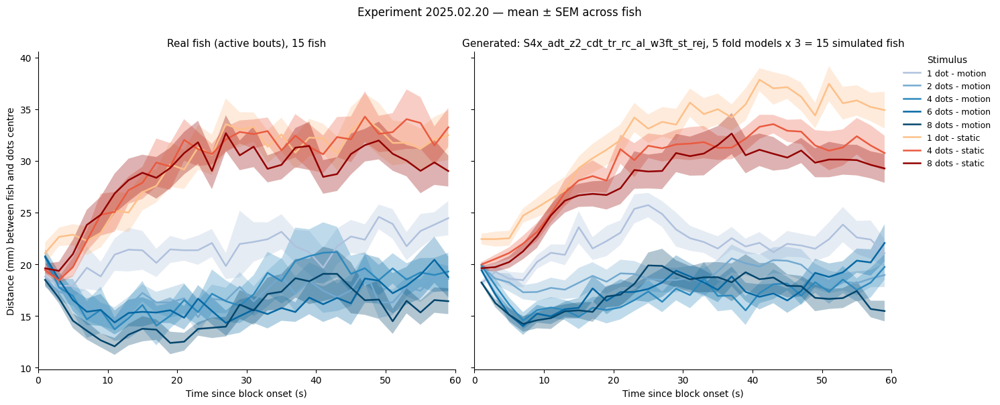


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

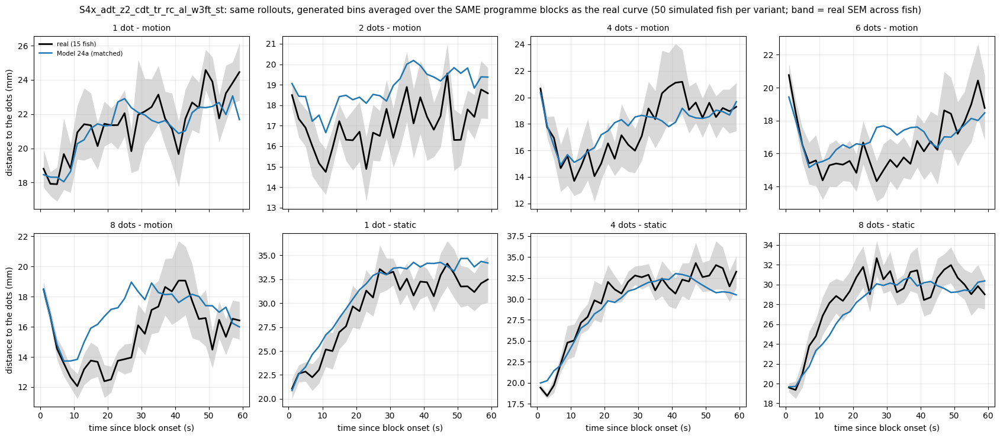


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                         plateau   null attraction
cond_label                                                                            
d1s3.5       22.41  23.57       1.16                           22.40  23.68       1.28
d2s3.5       17.39  23.58       6.19                           19.28  23.26       3.99
d4s3.5       18.74  23.93       5.19                           17.85  23.59       5.74
d6s3.5       16.69  23.12       6.43                           17.80  23.35       5.56
d8s3.5       16.41  23.36       6.94                           18.13  23.79       5.66

== turn toward the moving dots by dot count
           real  S4x_adt_z

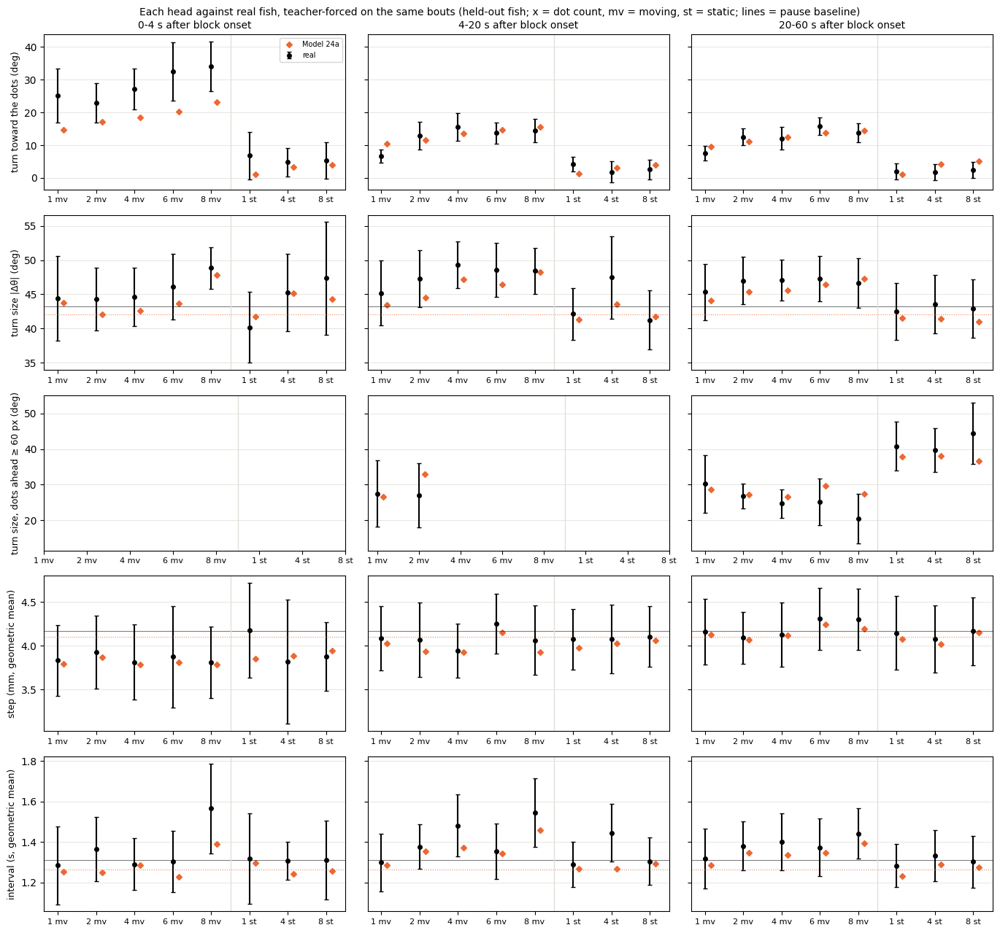

In [28]:
unit_eval.show('24a')

### D2, seed 0


== held-out likelihood per head (bits per bout)
turn             7.622
displacement     4.517
interval         1.190
joint           13.329

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 724s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                              8.0316
symbol_js                  

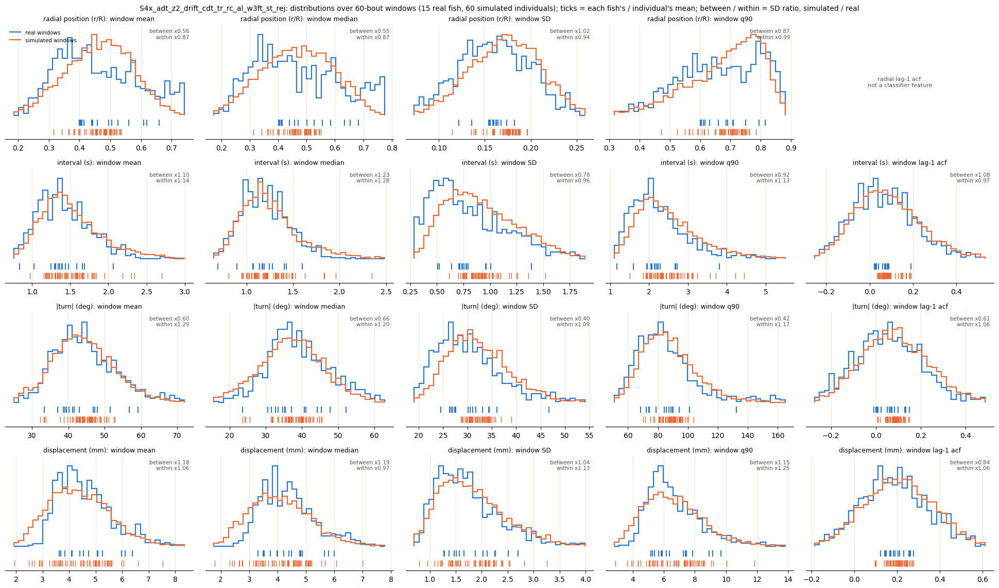


== distance to the dots across the block
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.5% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.41     0.94  0.15  0.88   3.0   5.0                  22.3 +/- 0.9  21.7 +/- 1.0
d2s3.5    2.67     2.08  2.64  1.55  11.0   7.0                  17.4 +/- 0.9  20.2 +/- 0.8
d4s3.5    1.03     0.70  4.68  3.06  19.0   7.0                  18.7 +/- 1.7  18.6 +/- 1.3
d6s3.5    1.34     0.96  4.62  3.75  13.0   9.0                  16.7 +/- 1.3  17.0 +/- 1.1
d8s3.5    1.88     1.79  4.97  0.98  11.0   7.0                  16.3 +/- 1.0  16.6 +/- 0.7
d1s

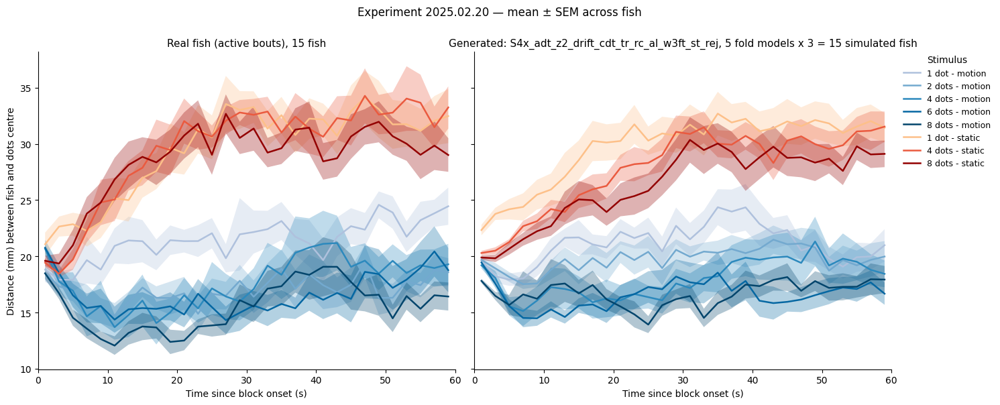


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

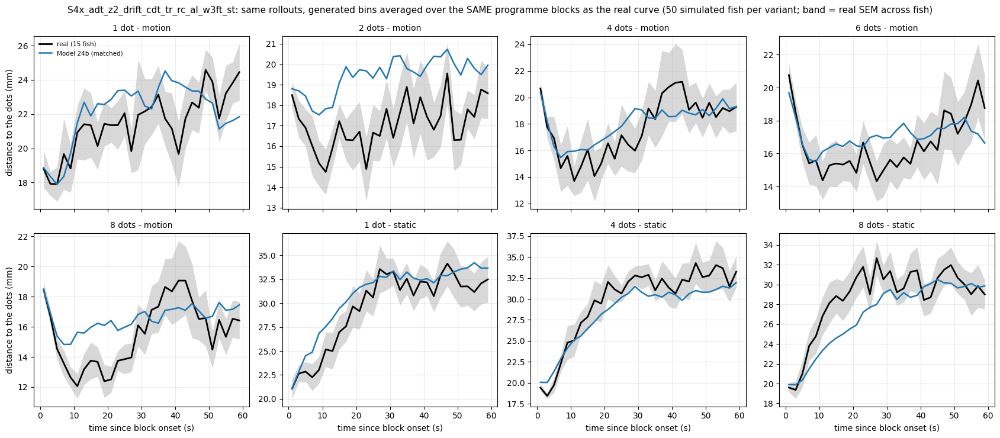


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                               plateau   null attraction
cond_label                                                                                  
d1s3.5       22.41  23.57       1.16                                 22.63  22.67       0.04
d2s3.5       17.39  23.58       6.19                                 20.13  22.72       2.59
d4s3.5       18.74  23.93       5.19                                 18.92  22.62       3.70
d6s3.5       16.69  23.12       6.43                                 17.67  22.76       5.09
d8s3.5       16.41  23.36       6.94                                 16.85  22.72       5.86

== turn toward the mov

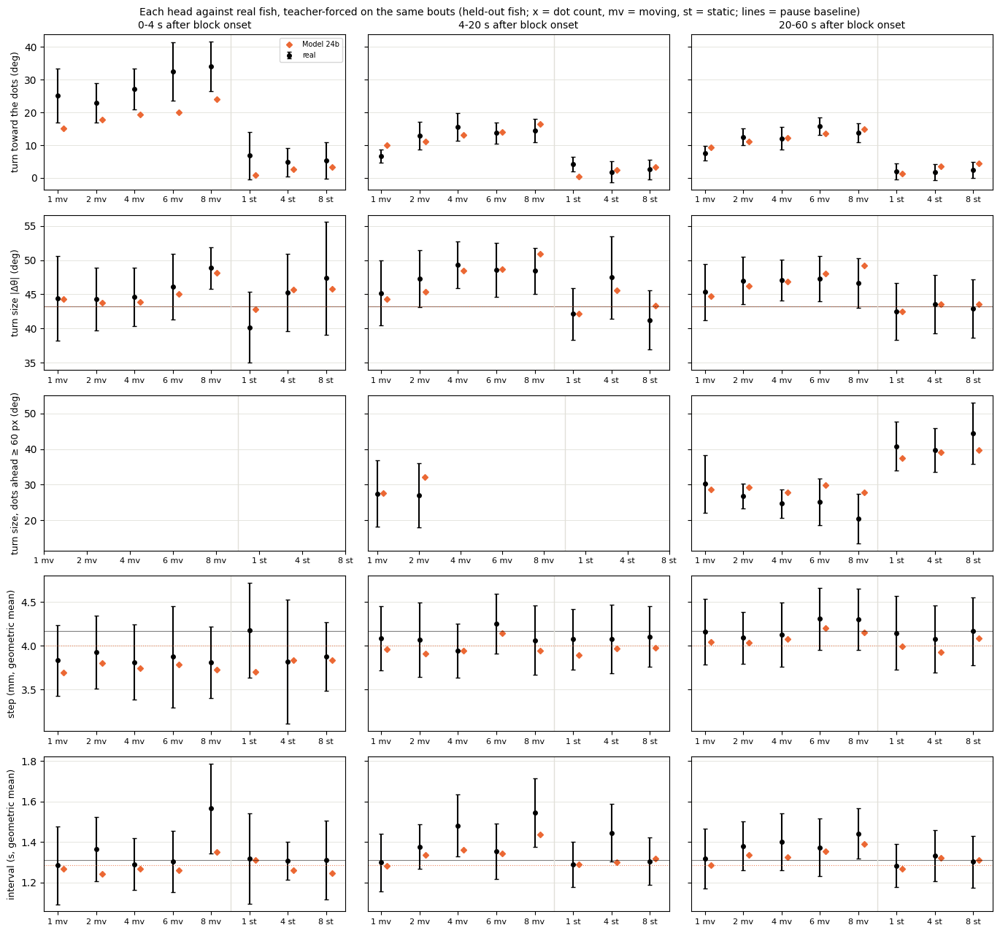

In [29]:
unit_eval.show('24b')

### D2, seed 101


== held-out likelihood per head (bits per bout)
turn             7.629
displacement     4.502
interval         1.217
joint           13.348

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 711s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                              8.7466
symbol_js                  

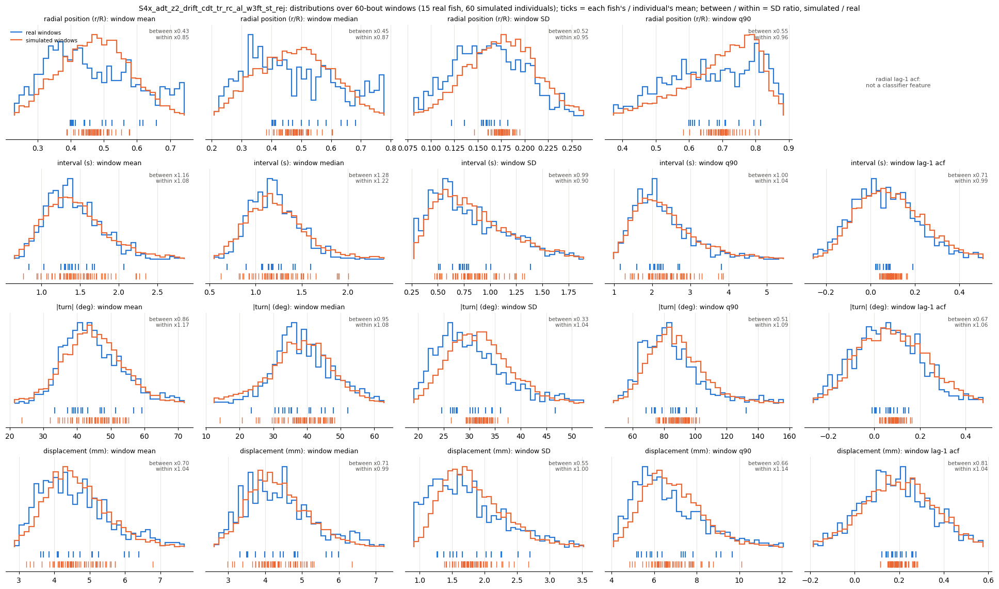


== distance to the dots across the block
  S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 13.3% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.90     1.27  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  23.3 +/- 1.4
d2s3.5    3.34     2.54  2.64  2.25  11.0   9.0                  17.4 +/- 0.9  21.3 +/- 1.5
d4s3.5    1.82     1.18  4.68  2.52  19.0   7.0                  18.7 +/- 1.7  19.9 +/- 1.4
d6s3.5    1.32     1.00  4.62   3.6  13.0  11.0                  16.7 +/- 1.3  17.5 +/- 0.9
d8s3.5    1.81     1.76  4.97  2.56  11.0   7.0                  16.3 +/- 1.0  17.6 +/- 1.1
d1s

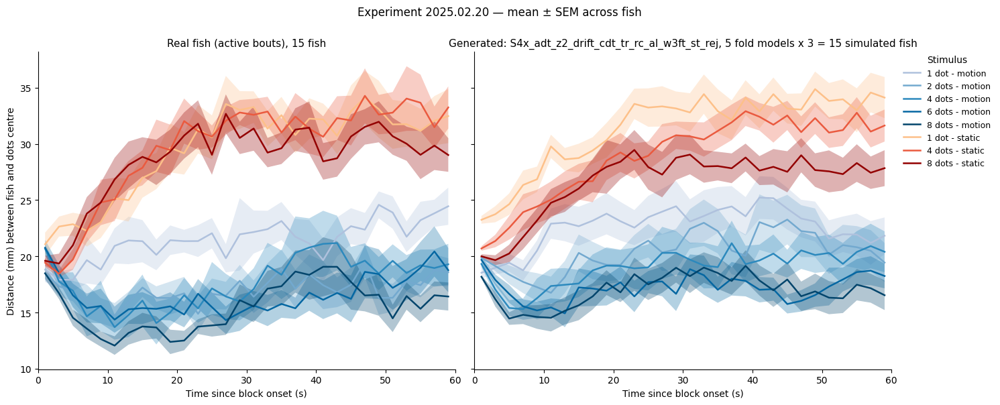


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

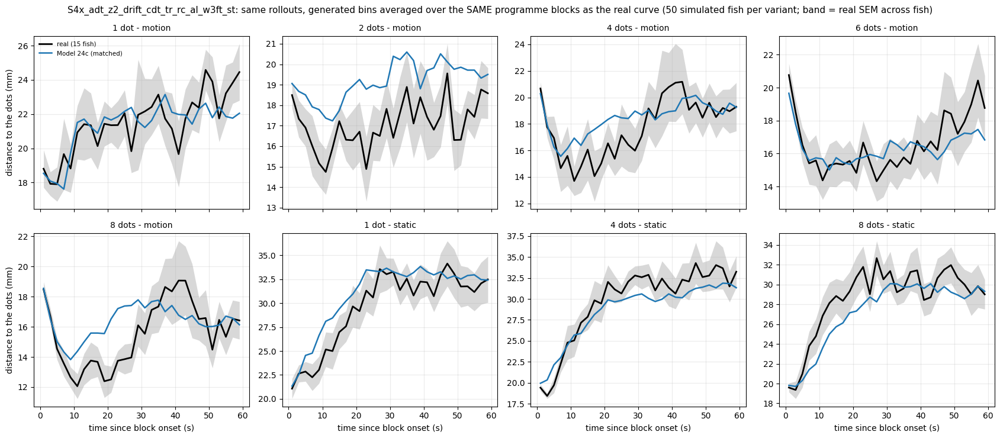


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4x_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                               plateau   null attraction
cond_label                                                                                  
d1s3.5       22.41  23.57       1.16                                 22.48  23.26       0.78
d2s3.5       17.39  23.58       6.19                                 20.88  22.95       2.06
d4s3.5       18.74  23.93       5.19                                 19.10  23.25       4.15
d6s3.5       16.69  23.12       6.43                                 16.76  23.18       6.42
d8s3.5       16.41  23.36       6.94                                 16.89  22.97       6.08

== turn toward the mov

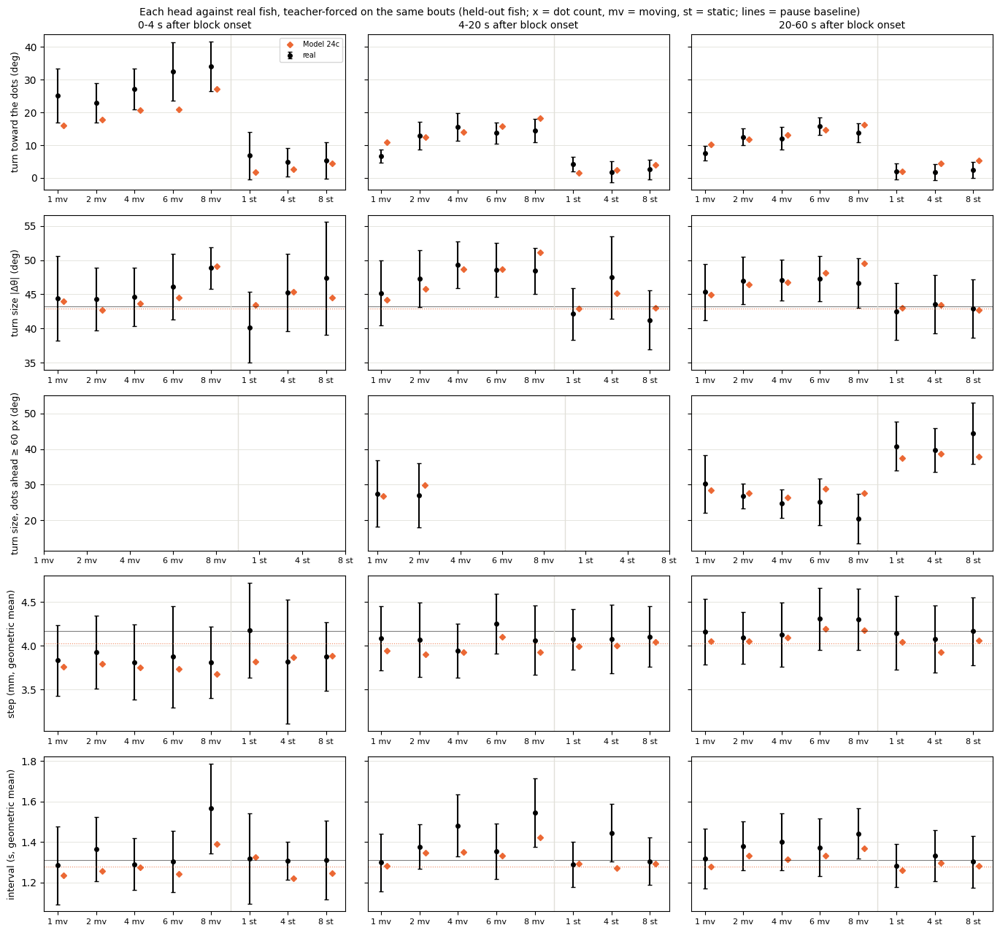

In [30]:
unit_eval.show('24c')

### D3, seed 0


== held-out likelihood per head (bits per bout)
turn             7.658
displacement     4.513
interval         1.236
joint           13.406

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 719s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                       7.1648
symbol_js                                           0.0094
dt_w1     

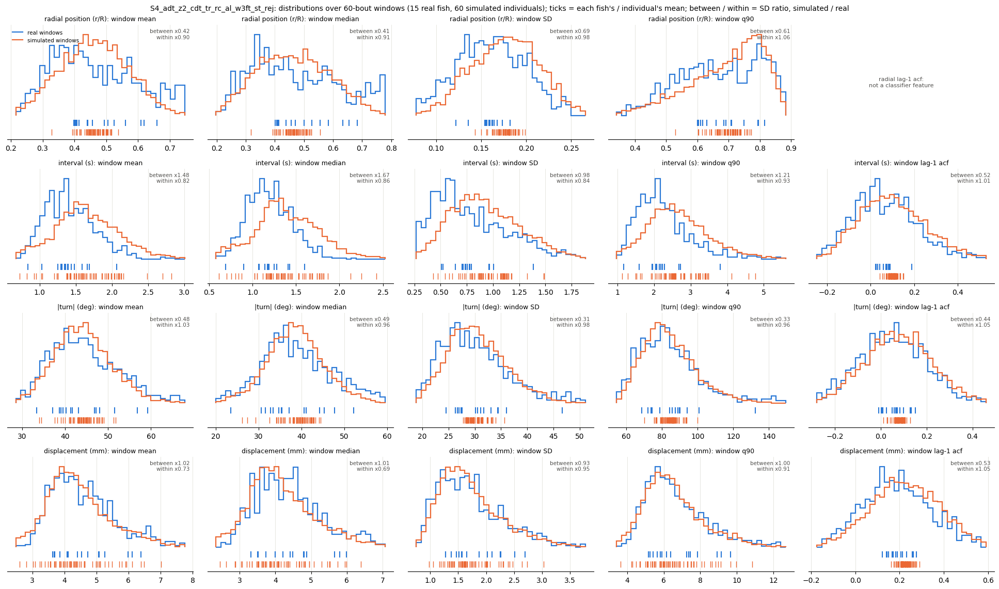


== distance to the dots across the block
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 10.9% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.30     0.87  0.15  0.81   3.0   7.0                  22.3 +/- 0.9  21.8 +/- 0.8
d2s3.5    1.42     1.17  2.64   2.8  11.0  17.0                  17.4 +/- 0.9  18.3 +/- 1.0
d4s3.5    1.72     0.90  4.68  4.58  19.0  13.0                  18.7 +/- 1.7  16.5 +/- 0.7
d6s3.5    0.98     0.67  4.62  4.51  13.0  13.0                  16.7 +/- 1.3  16.8 +/- 0.9
d8s3.5    1.64     1.42  4.97   3.2  11.0   9.0                  16.3 +/- 1.0  15.9 +/- 1.0
d1s0      

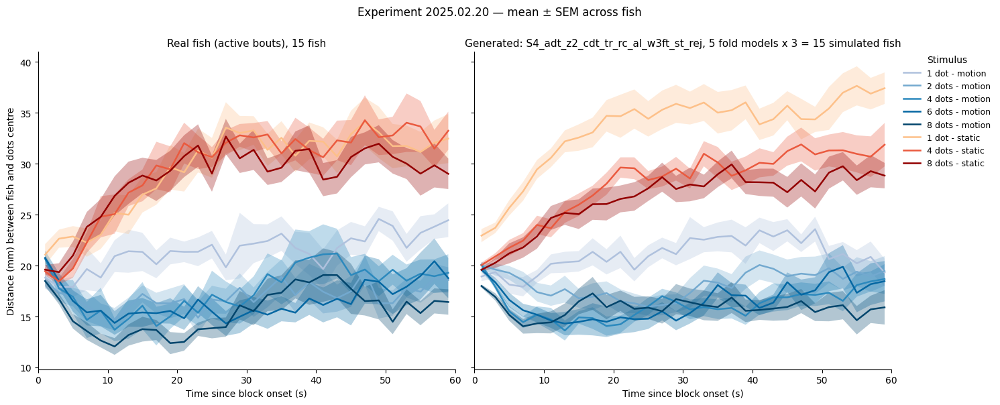


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

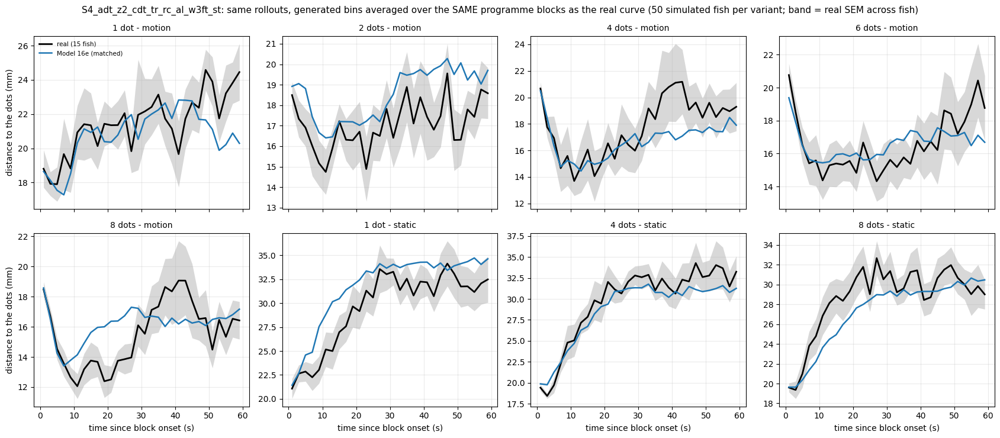


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          21.97  22.10       0.13
d2s3.5       17.39  23.58       6.19                          18.28  22.34       4.06
d4s3.5       18.74  23.93       5.19                          17.13  22.09       4.96
d6s3.5       16.69  23.12       6.43                          17.34  22.10       4.76
d8s3.5       16.41  23.36       6.94                          16.39  22.63       6.24

== turn toward the moving dots by dot count
           real  S4_adt_z2_cdt_tr_

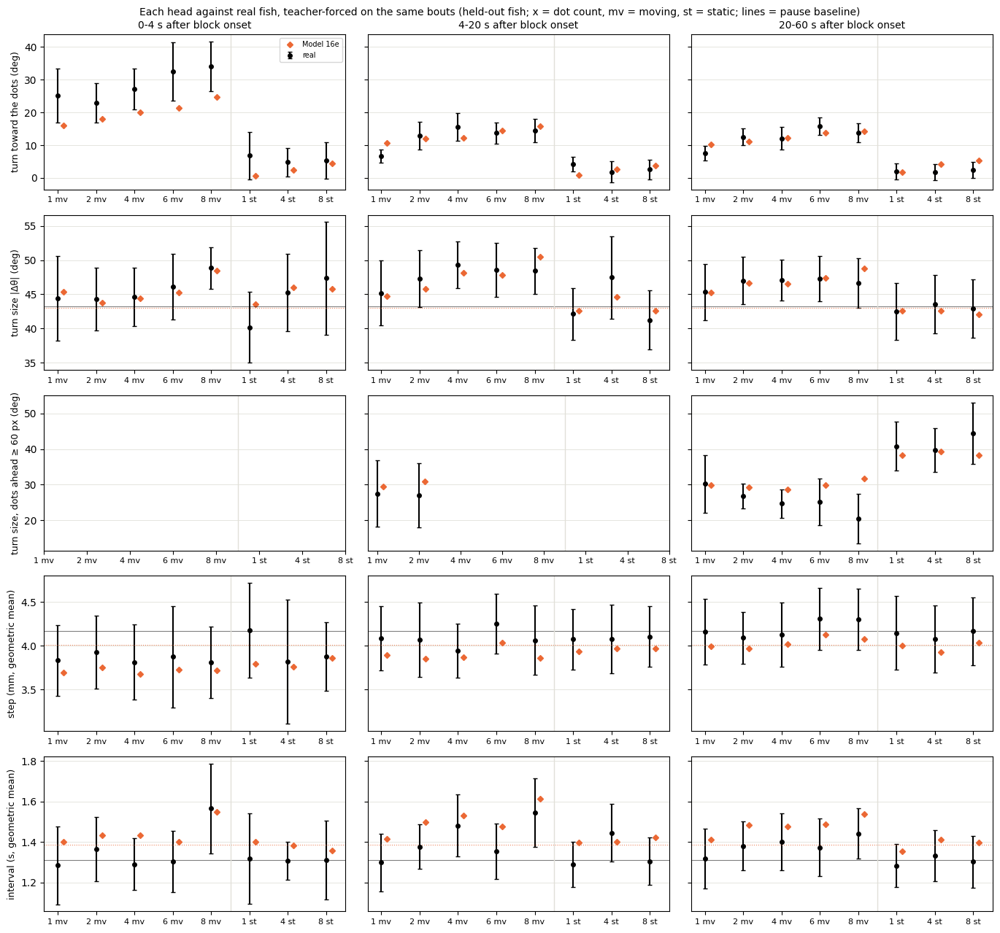

In [31]:
unit_eval.show('16e')

### D3, seed 101


== held-out likelihood per head (bits per bout)
turn             7.658
displacement     4.501
interval         1.243
joint           13.402

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 779s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                       8.6466
symbol_js                                           0.0123
dt_w1     

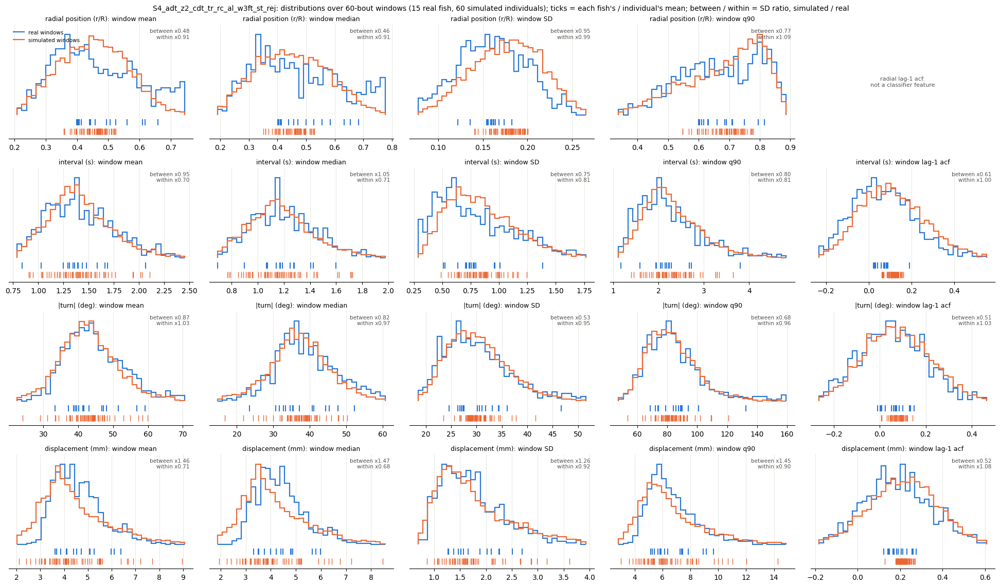


== distance to the dots across the block
  S4_adt_z2_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.7% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.42     1.01  0.15  0.53   3.0   5.0                  22.3 +/- 0.9  21.4 +/- 1.1
d2s3.5    2.22     1.70  2.64  2.28  11.0  13.0                  17.4 +/- 0.9  19.7 +/- 0.9
d4s3.5    1.36     0.72  4.68  4.12  19.0  11.0                  18.7 +/- 1.7  17.4 +/- 0.9
d6s3.5    1.31     0.95  4.62   4.3  13.0   9.0                  16.7 +/- 1.3  17.8 +/- 0.9
d8s3.5    1.33     1.18  4.97  3.79  11.0  13.0                  16.3 +/- 1.0  16.4 +/- 0.7
d1s0      2

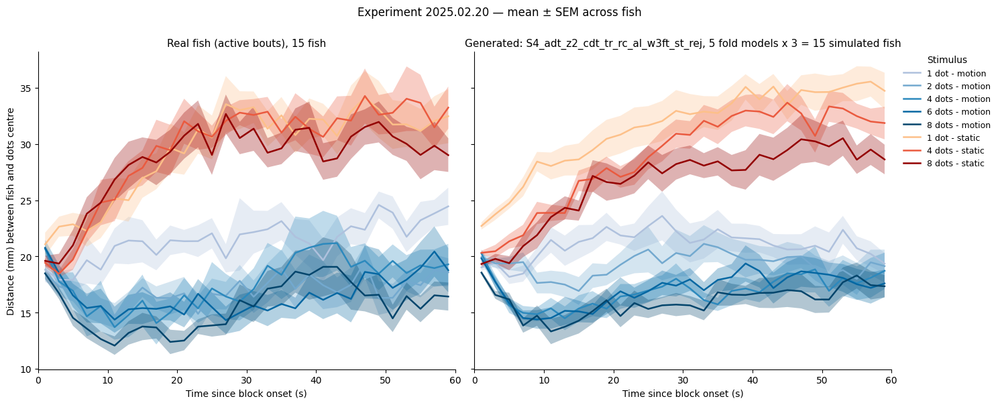


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

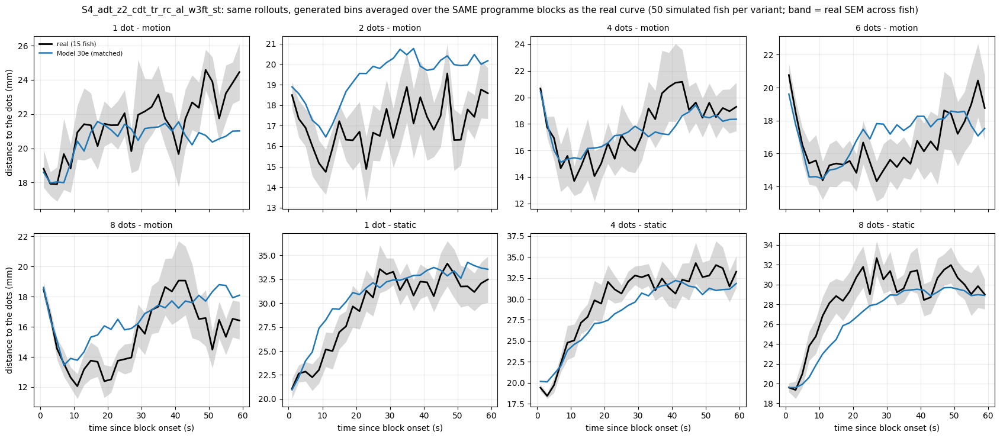


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                        plateau   null attraction
cond_label                                                                           
d1s3.5       22.41  23.57       1.16                          20.81  21.98       1.17
d2s3.5       17.39  23.58       6.19                          19.58  21.69       2.11
d4s3.5       18.74  23.93       5.19                          17.42  22.08       4.66
d6s3.5       16.69  23.12       6.43                          18.35  21.75       3.40
d8s3.5       16.41  23.36       6.94                          17.03  21.64       4.61

== turn toward the moving dots by dot count
           real  S4_adt_z2_cdt_tr_

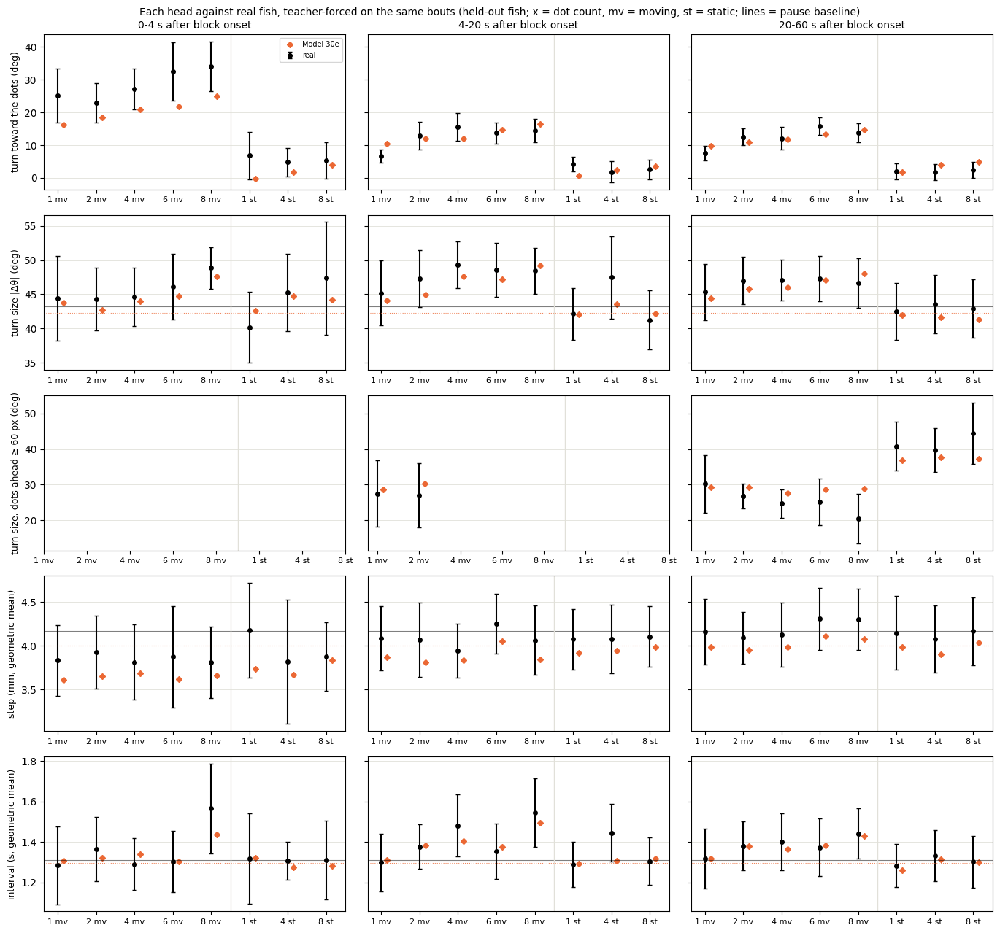

In [32]:
unit_eval.show('30e')

### D4, seed 0


== held-out likelihood per head (bits per bout)
turn             7.627
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 805s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.7966
symbol_js                        

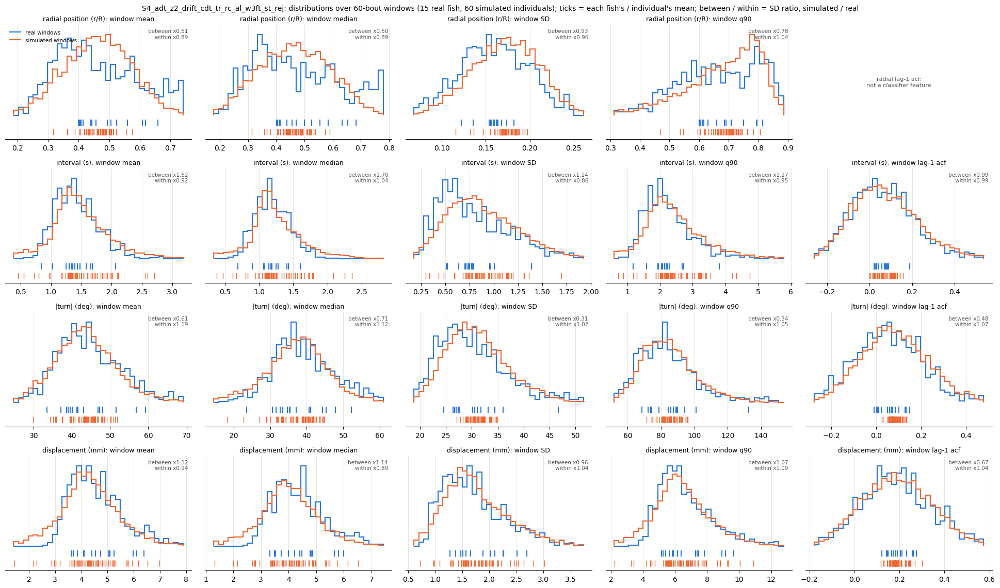


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 9.6% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.52     1.02  0.15  0.94   3.0   5.0                  22.3 +/- 0.9  20.6 +/- 1.1
d2s3.5    1.65     1.33  2.64  2.48  11.0  11.0                  17.4 +/- 0.9  18.2 +/- 0.9
d4s3.5    1.26     0.70  4.68  4.16  19.0   9.0                  18.7 +/- 1.7  17.4 +/- 1.1
d6s3.5    1.38     0.88  4.62  4.71  13.0  11.0                  16.7 +/- 1.3  16.2 +/- 0.9
d8s3.5    1.51     1.44  4.97  2.19  11.0   7.0                  16.3 +/- 1.0  16.8 +/- 0.9
d1s0 

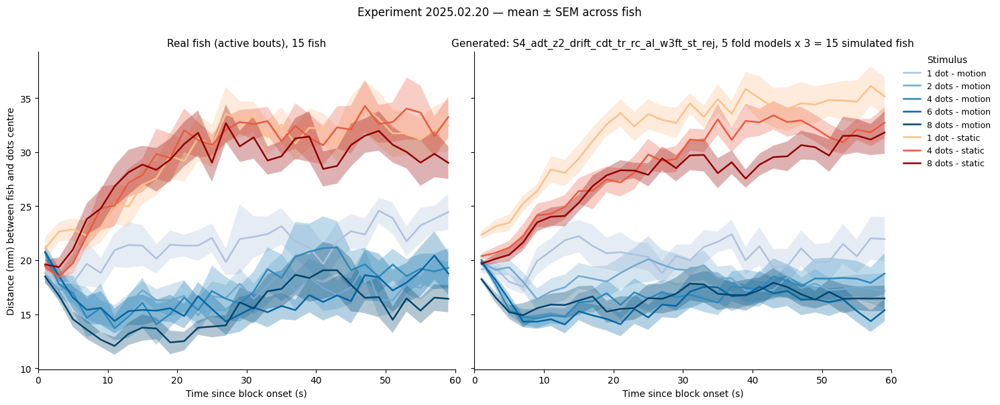


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

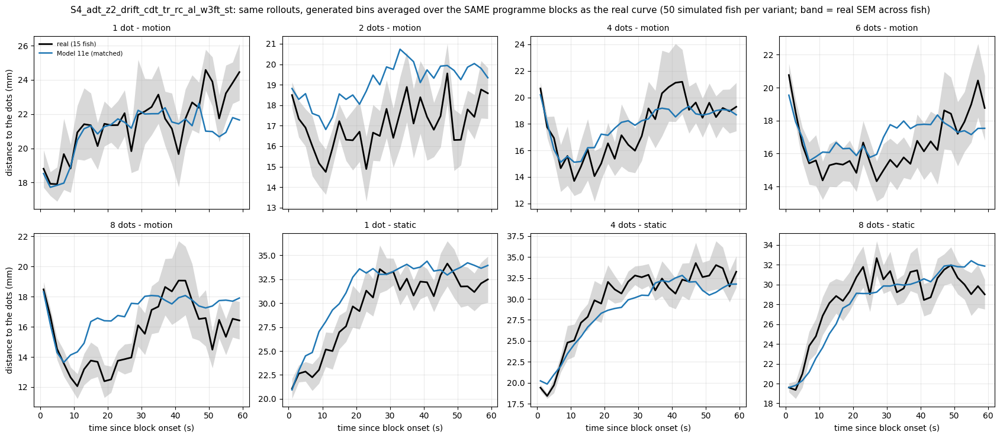


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                22.03  22.58       0.55
d2s3.5       17.39  23.58       6.19                                18.62  22.48       3.86
d4s3.5       18.74  23.93       5.19                                18.67  22.32       3.65
d6s3.5       16.69  23.12       6.43                                17.25  22.52       5.28
d8s3.5       16.41  23.36       6.94                                17.29  22.24       4.96

== turn toward the moving dots

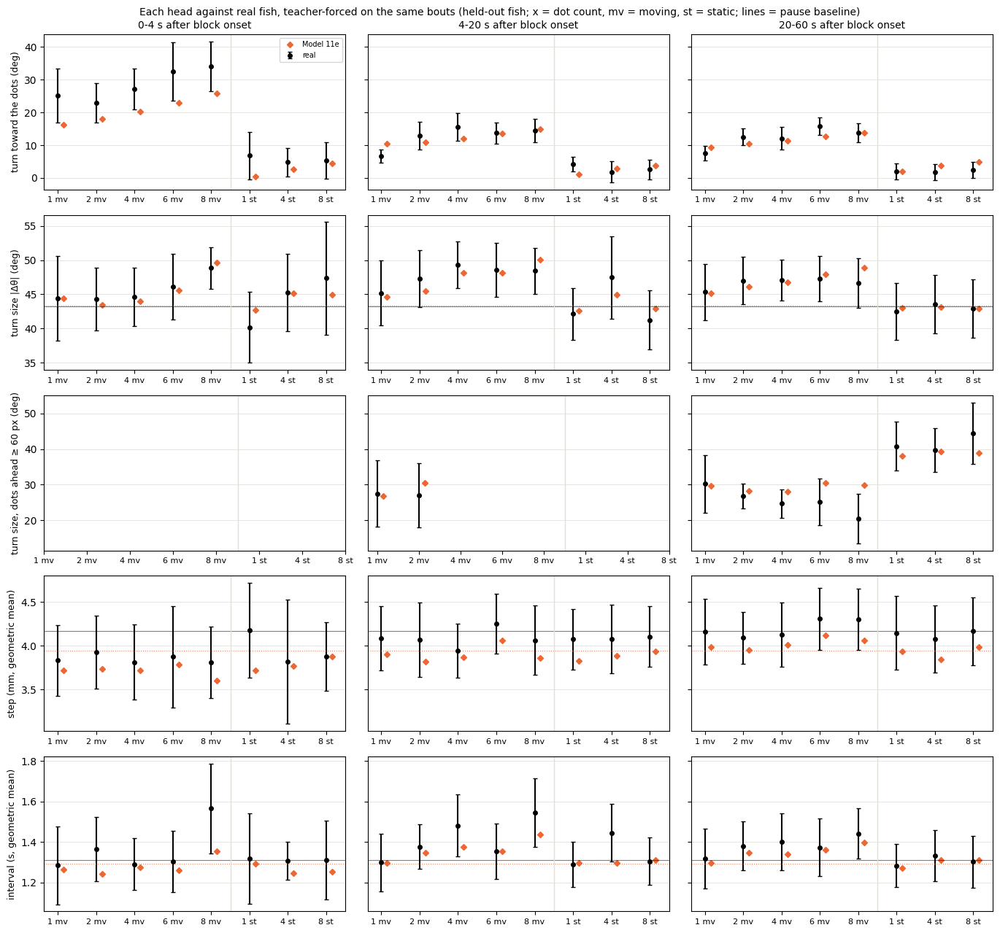

In [33]:
unit_eval.show('11e')

### D4, seed 101


== held-out likelihood per head (bits per bout)
turn             7.630
displacement     4.520
interval         1.207
joint           13.356

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st.csv  (15 rows) in 486s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_rej
abs_dtheta_w1                                             8.2571
symbol_js                        

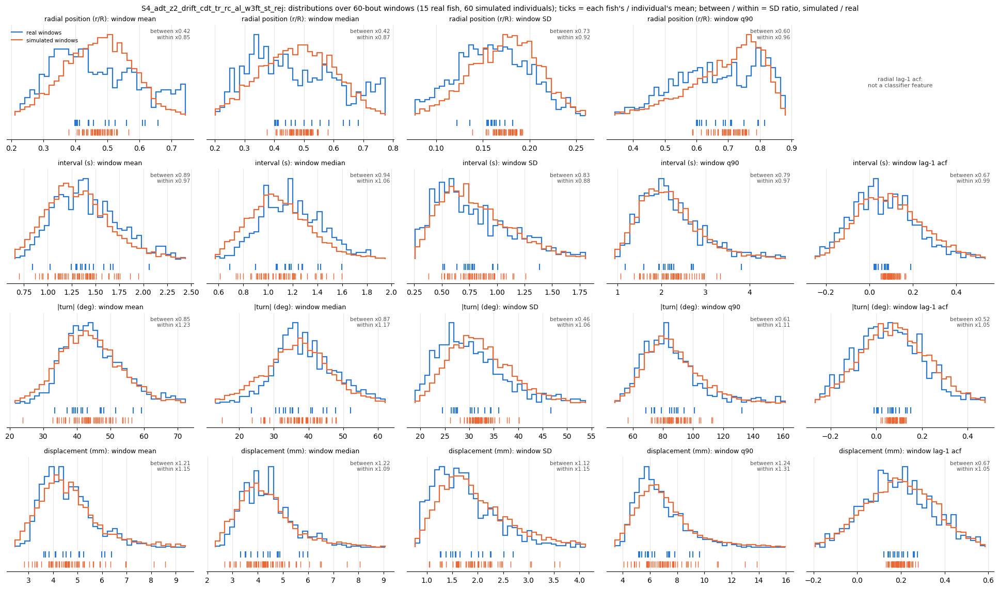


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_fold4.pt: 3 rollouts
dropped 11.1% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.61     1.14  0.15   0.0   3.0   1.0                  22.3 +/- 0.9  21.5 +/- 0.9
d2s3.5    1.86     1.40  2.64  1.97  11.0  11.0                  17.4 +/- 0.9  19.4 +/- 1.0
d4s3.5    1.65     1.03  4.68  3.06  19.0   7.0                  18.7 +/- 1.7  19.7 +/- 1.3
d6s3.5    0.84     0.60  4.62  3.54  13.0   9.0                  16.7 +/- 1.3  16.6 +/- 1.0
d8s3.5    2.03     1.83  4.97  3.16  11.0   9.0                  16.3 +/- 1.0  18.1 +/- 1.0
d1s0

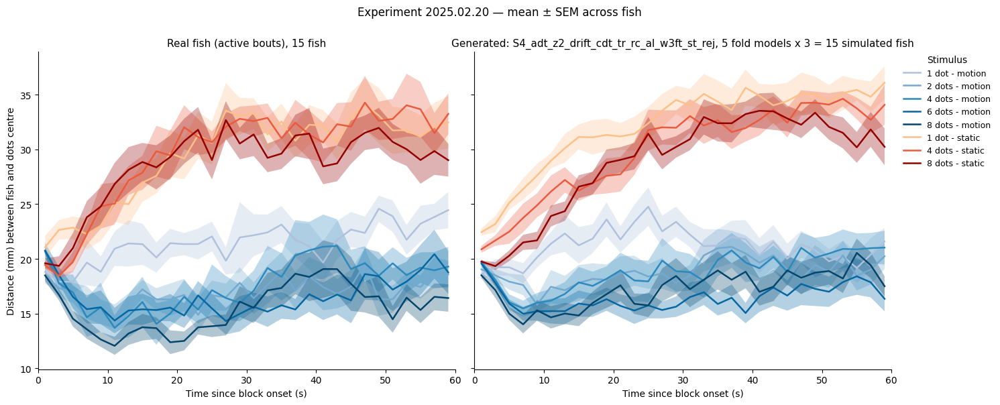


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

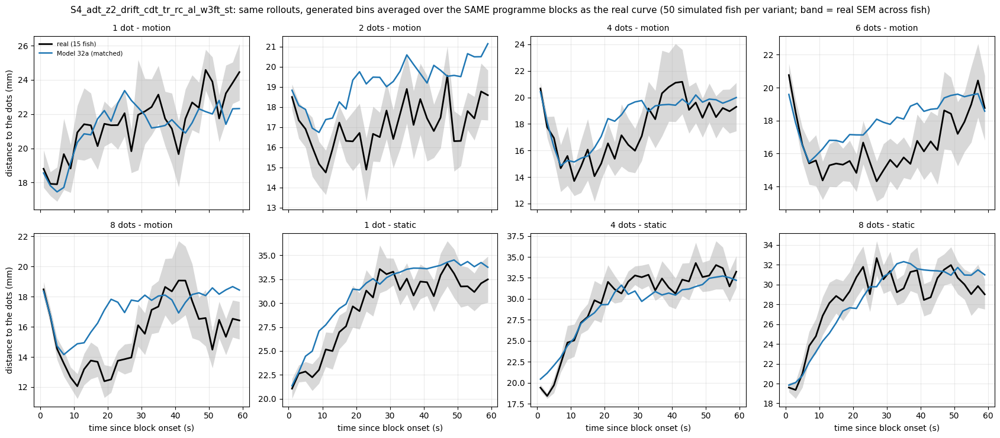


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st                  
           plateau   null attraction                              plateau   null attraction
cond_label                                                                                 
d1s3.5       22.41  23.57       1.16                                21.89  22.70       0.81
d2s3.5       17.39  23.58       6.19                                19.63  22.65       3.01
d4s3.5       18.74  23.93       5.19                                19.62  22.57       2.94
d6s3.5       16.69  23.12       6.43                                18.87  22.55       3.68
d8s3.5       16.41  23.36       6.94                                17.77  22.76       4.99

== turn toward the moving dots

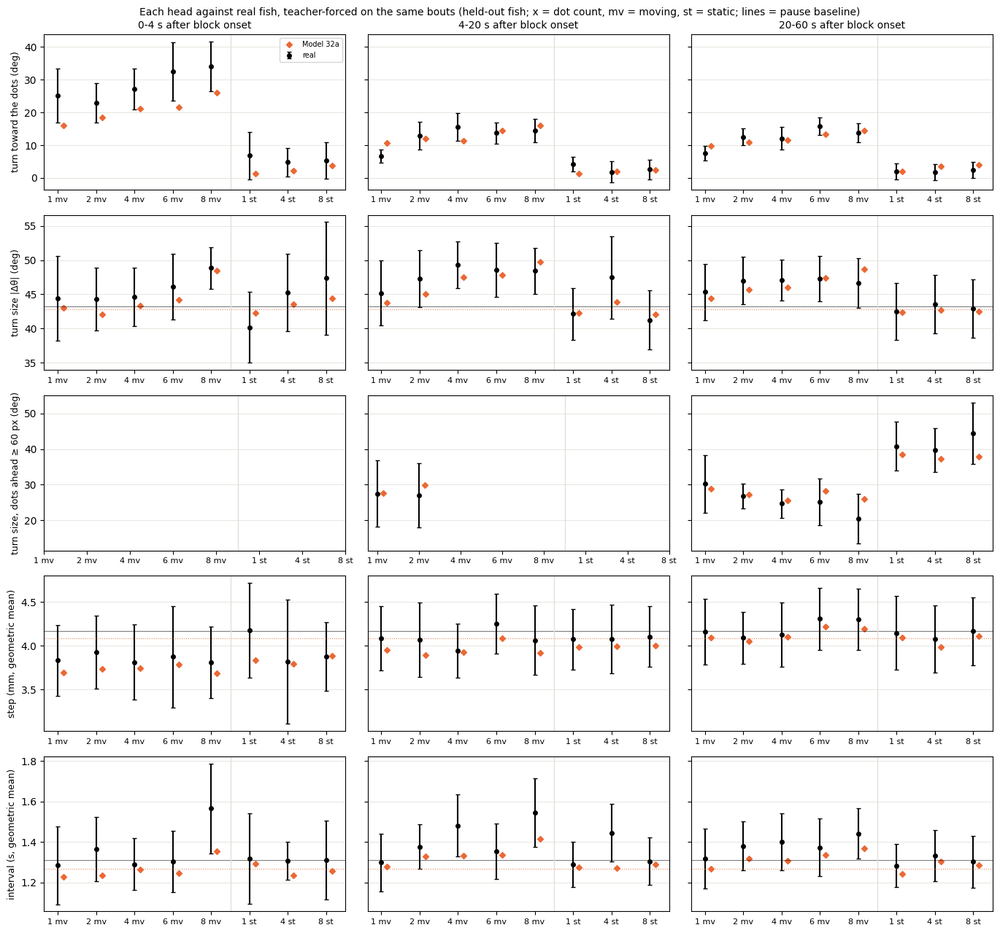

In [34]:
unit_eval.show('32a')

### F, seed 0


== held-out likelihood per head (bits per bout)
turn             7.628
displacement     4.513
interval         1.203
joint           13.344

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 1141s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                        

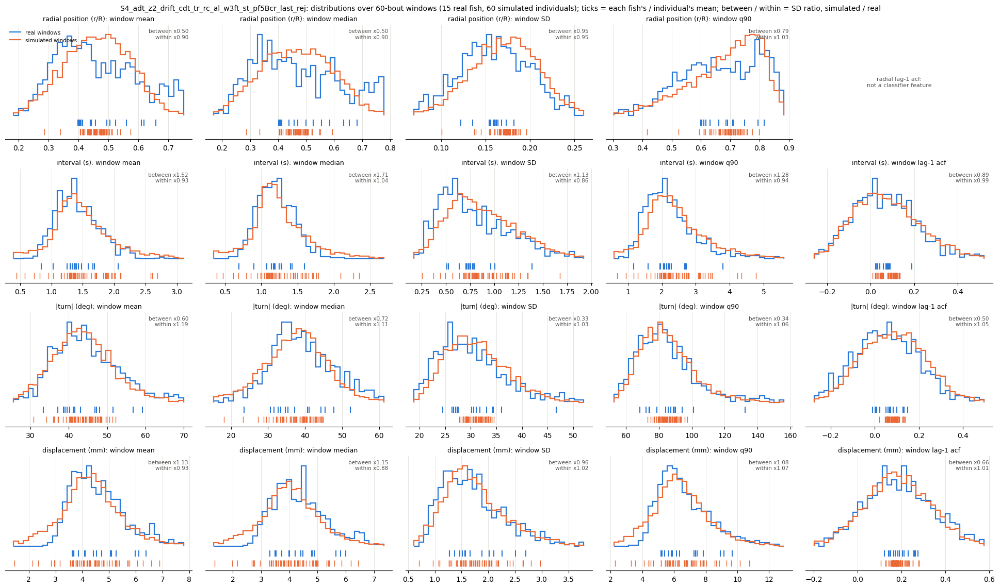


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 8.8% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.24     0.83  0.15  0.23   3.0   3.0                  22.3 +/- 0.9  21.2 +/- 0.9
d2s3.5    1.09     0.88  2.64  3.01  11.0  15.0                  17.4 +/- 0.9  18.2 +/- 1.2
d4s3.5    1.33     0.72  4.68  4.74  19.0   9.0                  18.7 +/- 1.7  17.4 +/- 0.7
d6s3.5    1.48     1.02  4.62  5.31  13.0  11.0                  16.7 +/- 1.3  16.2 +/- 0.8
d8s3.5    0.91     0.72  4.97  4.86  11.0   9.0                  16.3 +/- 1.0  15.8 +

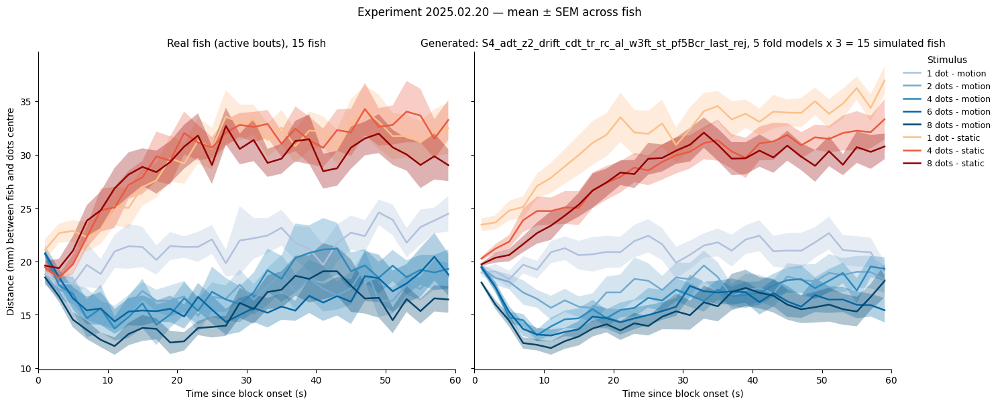


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

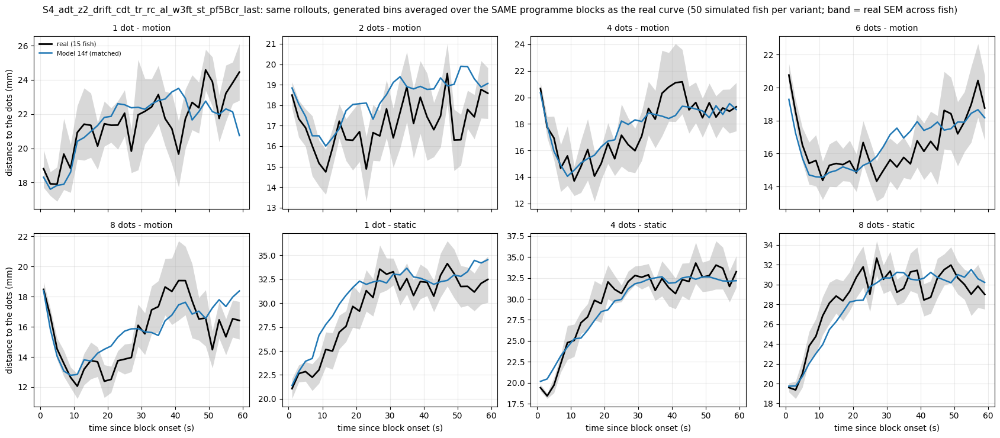


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            22.10  22.48       0.38
d2s3.5       17.39  23.58       6.19                                            18.70  22.57       3.87
d4s3.5       18.74  23.93       5.19                                            18.12  22.72       4.60
d6s3.5       16.69  23.12       6.43                                            17.01  22.61       5.60
d8s3.5       16.41  23.36       6.94   

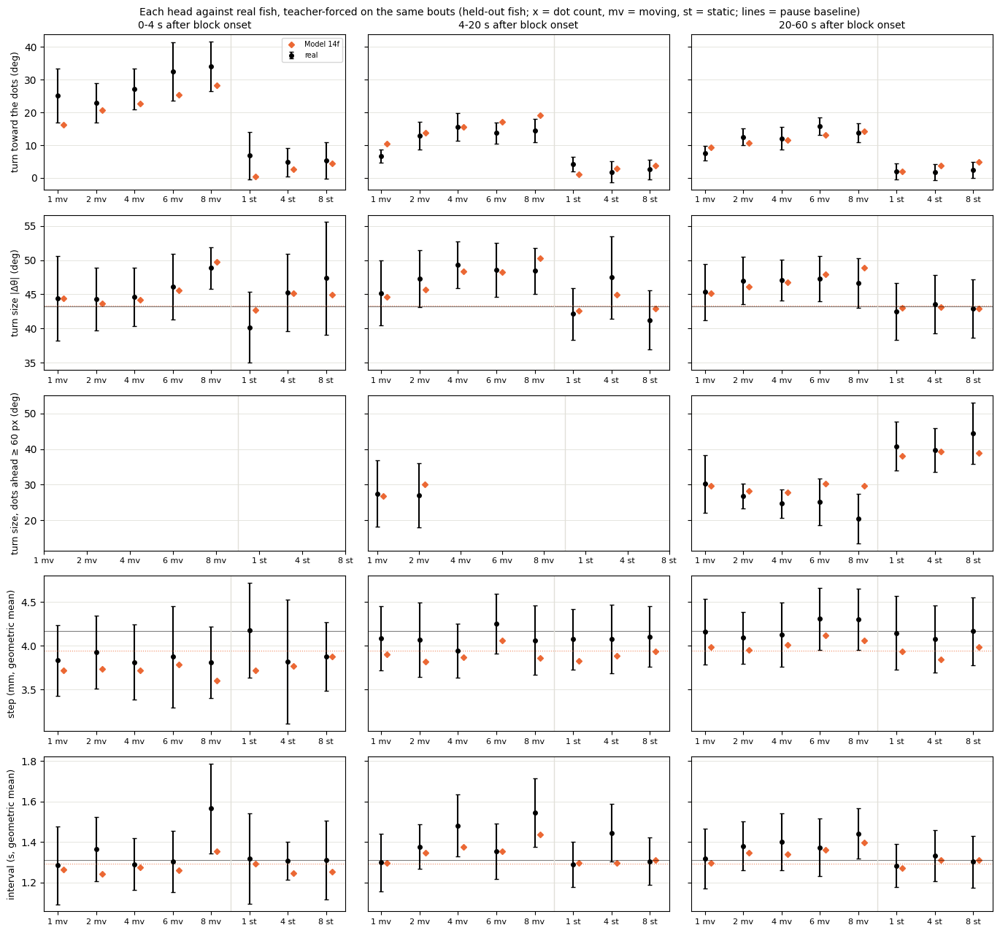

In [35]:
unit_eval.show('14f')

### F, seed 101


== held-out likelihood per head (bits per bout)
turn             7.630
displacement     4.520
interval         1.207
joint           13.357

== window classifier: AUC (standard, steady-state) and the spread of simulated individuals
generation-time override ['wall_reject'] -> arms tagged '_rej', writing panelB_model1_rej.csv / c2st_model1_rej.csv
arms filter ['S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last'] -> writing panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv / c2st_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv
15 (checkpoint, fish) rollout jobs, R=20, c2st_reps=8, jobs=4  (420 rollouts total)
stimulus: RE-ANCHORED to each simulated fish at block onset (the rig's rule)
wrote panelB_model1_rej_S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last.csv  (15 rows) in 498s

Metric B, mean over held-out fish (lower = closer to real):
arm                     S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_rej
abs_dtheta_w1                         

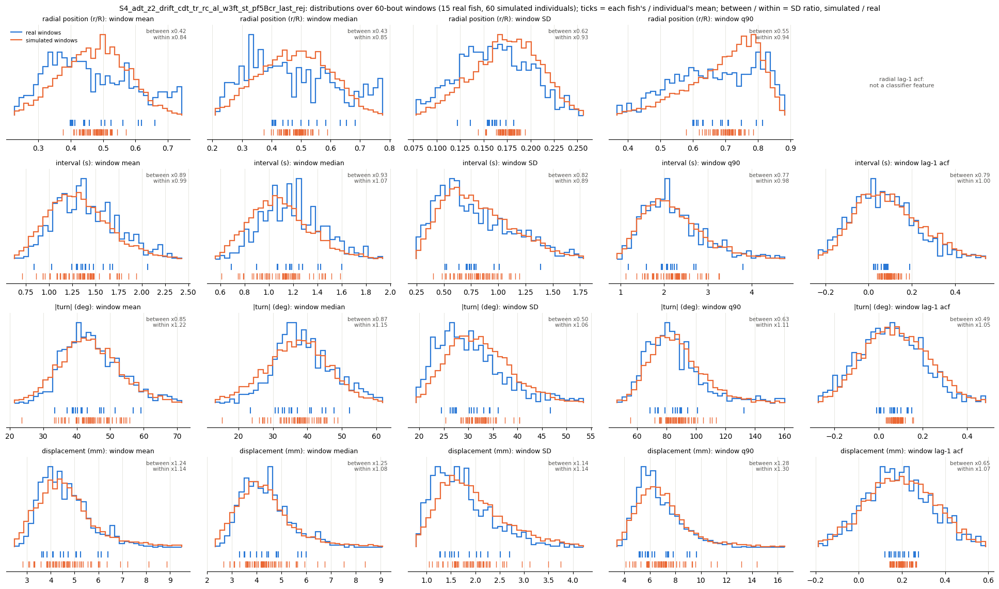


== distance to the dots across the block
  S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last_fold4.pt: 3 rollouts
dropped 10.0% of generated stimulus bouts: dot centroid outside the dish
the plot in numbers (mm): err = mean |gen - real| over 0-60 s; dip amplitude / latency (moving);
drift over 0-20 s in mm/s (static); plateau = 20-60 s, mean +/- SEM across fish
        err mm  err/SEM dip r dip g lat r lat g drift r drift g     plateau r     plateau g
cond                                                                                       
d1s3.5    1.44     0.95  0.15  0.62   3.0   5.0                  22.3 +/- 0.9  23.0 +/- 1.0
d2s3.5    1.29     1.05  2.64  2.97  11.0   9.0                  17.4 +/- 0.9  18.6 +/- 0.7
d4s3.5    1.32     0.68  4.68  5.04  19.0  11.0                  18.7 +/- 1.7  17.2 +/- 0.8
d6s3.5    1.41     0.92  4.62  3.85  13.0   9.0                  16.7 +/- 1.3  16.5 +/- 1.0
d8s3.5    0.82     0.69  4.97  3.22  11.0  11.0                  16.3 +/- 1.0  15.8 

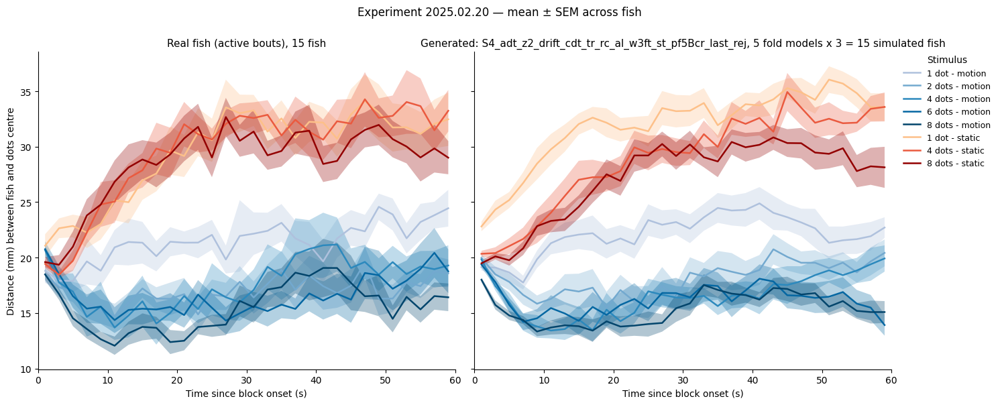


== the same profile matched to the real block composition: dip, plateau, grading, errors
distinct programme blocks behind each REAL point (95 exist; the generated side is reweighted onto these):
cond_label  d1s3.5  d2s3.5  d4s3.5  d6s3.5  d8s3.5  d1s0  d4s0  d8s0
tbin                                                                
1.0             12      12      12      12      12    11    12    12
3.0             12      12      12      12      12    11    12    12
5.0             12      12      12      12      12    11    12    12
7.0             12      12      12      12      12    11    12    12
9.0             12      12      12      12      12    11    12    12
11.0            12      12      12      12      12    11    12    12

the plot in numbers, each variant as plotted and matched to the real block composition:
                        mv_err_mm  mv_err_sem   dip   lat  plateau  d1_plateau  grading  st_err_mm  st_err_sem  static_drift
variant                               

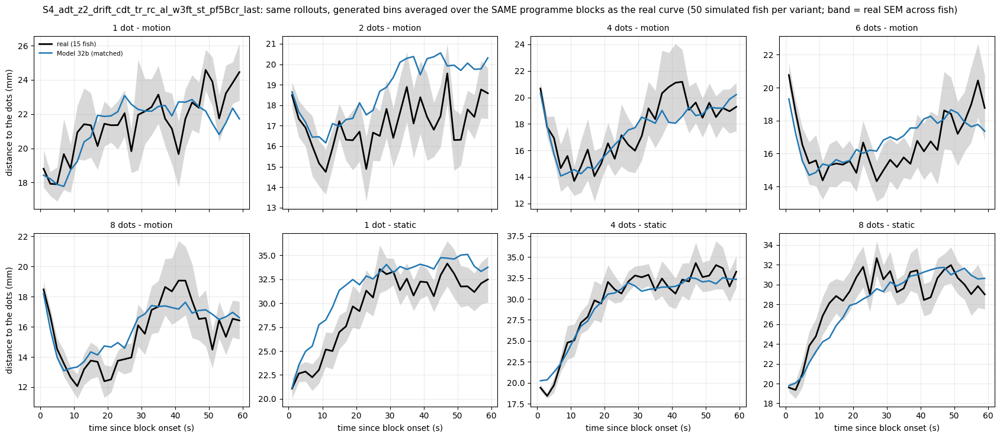


== attraction per dot count
PLATEAU (20-60 s) vs a STIMULUS-BLIND NULL, mm. attraction = null - plateau = what the dots are worth.
Real is a STEP (~0 for one dot, ~6 from two up); a code that reads count off magnitude gives a RAMP.
              real                   S4_adt_z2_drift_cdt_tr_rc_al_w3ft_st_pf5Bcr_last                  
           plateau   null attraction                                          plateau   null attraction
cond_label                                                                                             
d1s3.5       22.41  23.57       1.16                                            23.01  22.39      -0.62
d2s3.5       17.39  23.58       6.19                                            19.47  22.39       2.92
d4s3.5       18.74  23.93       5.19                                            17.95  22.54       4.58
d6s3.5       16.69  23.12       6.43                                            17.20  22.56       5.36
d8s3.5       16.41  23.36       6.94   

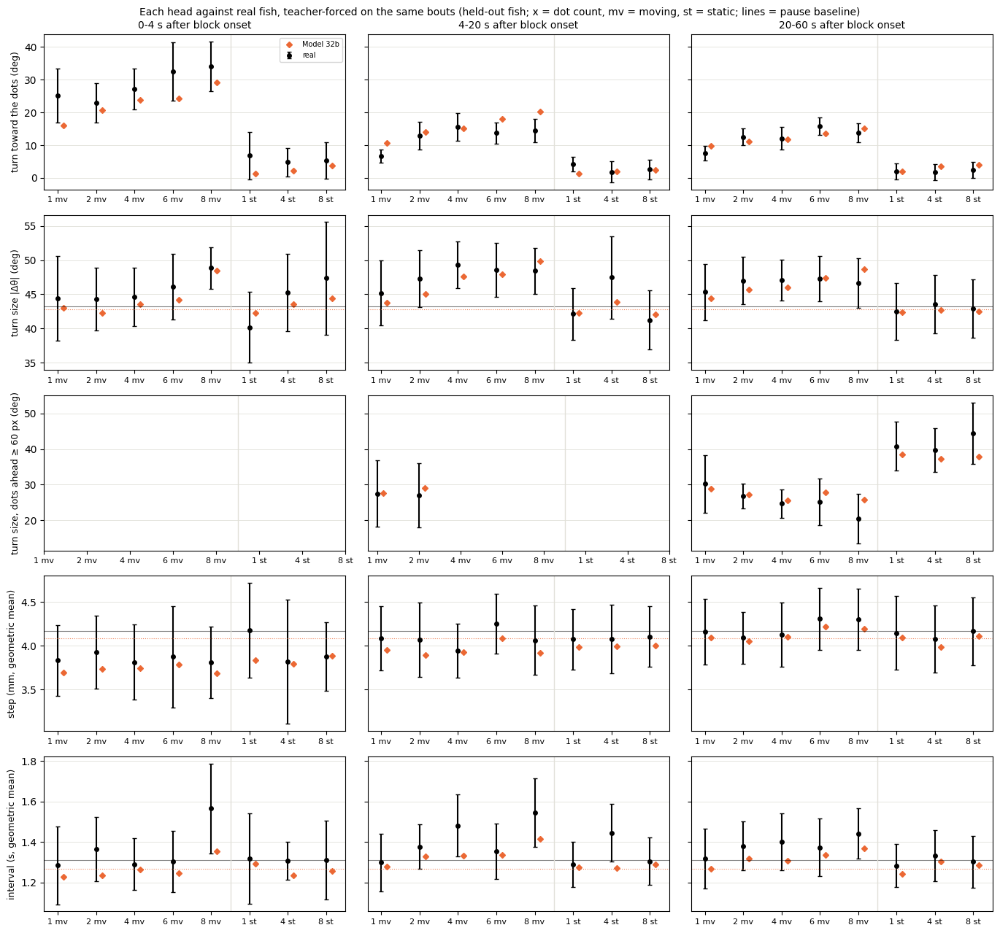

In [36]:
unit_eval.show('32b')